# 02-LangChain RAG开发：模型、链、记忆与向量检索

本篇对应课程第 2 份课件《02大模型RAG开发》，按课件顺序介绍 RAG 原理、向量与余弦相似度、LangChain 环境和模型组件、提示词模板、Runnable 链、输出解析器、会话记忆、文档加载、文本切分、向量存储，以及把检索结果放入提示词的基本方法。

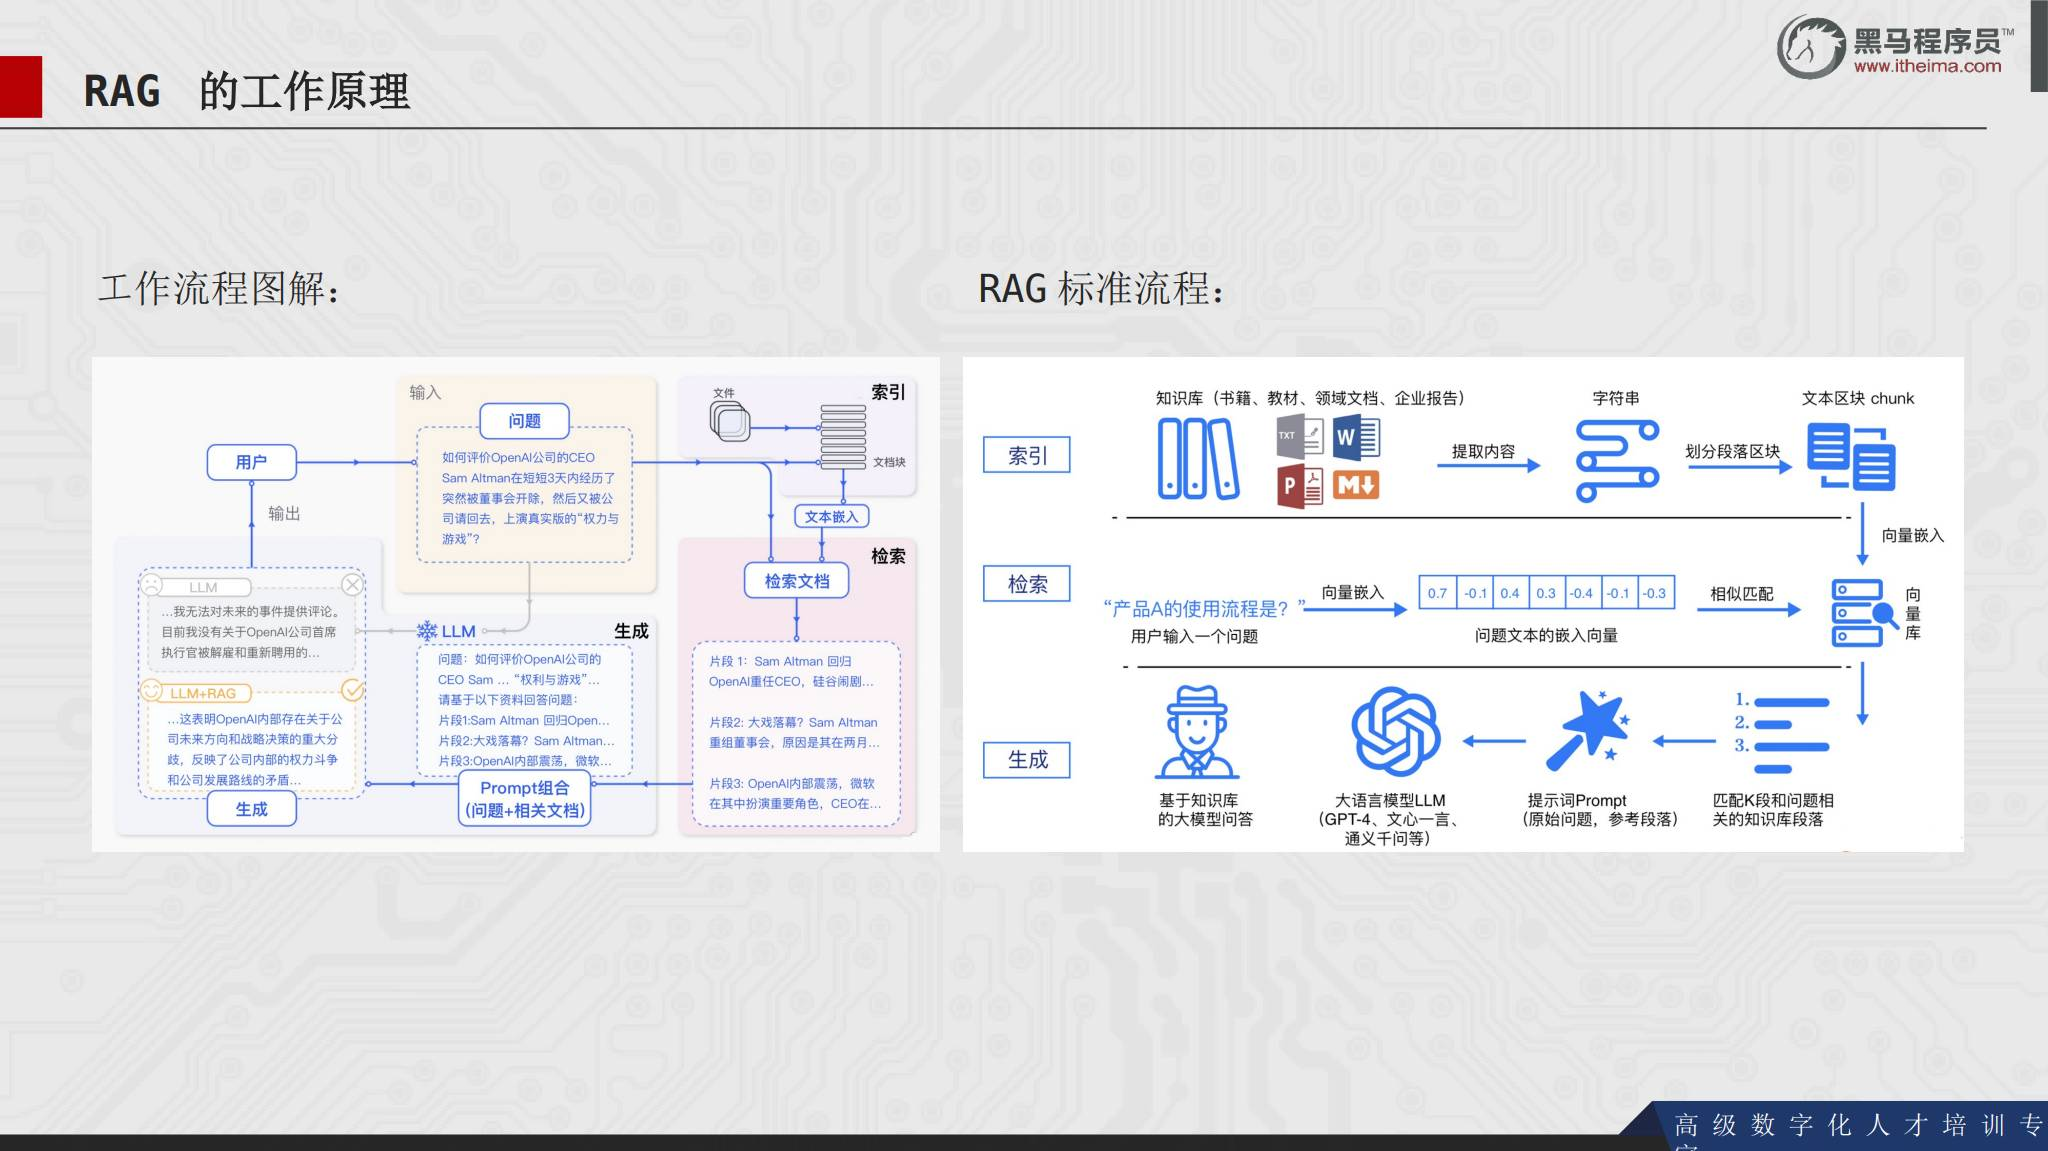


## 1. RAG 解决什么问题

传统大模型存在四类限制：

- **知识不是实时的**：模型训练完成后不会自动更新知识。
- **领域知识不足**：公开训练数据无法覆盖企业内部资料或高度专业的领域。
- **幻觉问题**：模型可能生成看似合理、实际上错误的信息。
- **数据安全问题**：把内部资料直接交给外部服务需要谨慎处理。

RAG（Retrieval-Augmented Generation，检索增强生成）为模型提供来自特定数据源的检索结果，用这些内容修正和补充模型回答。课程将它概括为：

> RAG = 检索技术 + LLM 提示

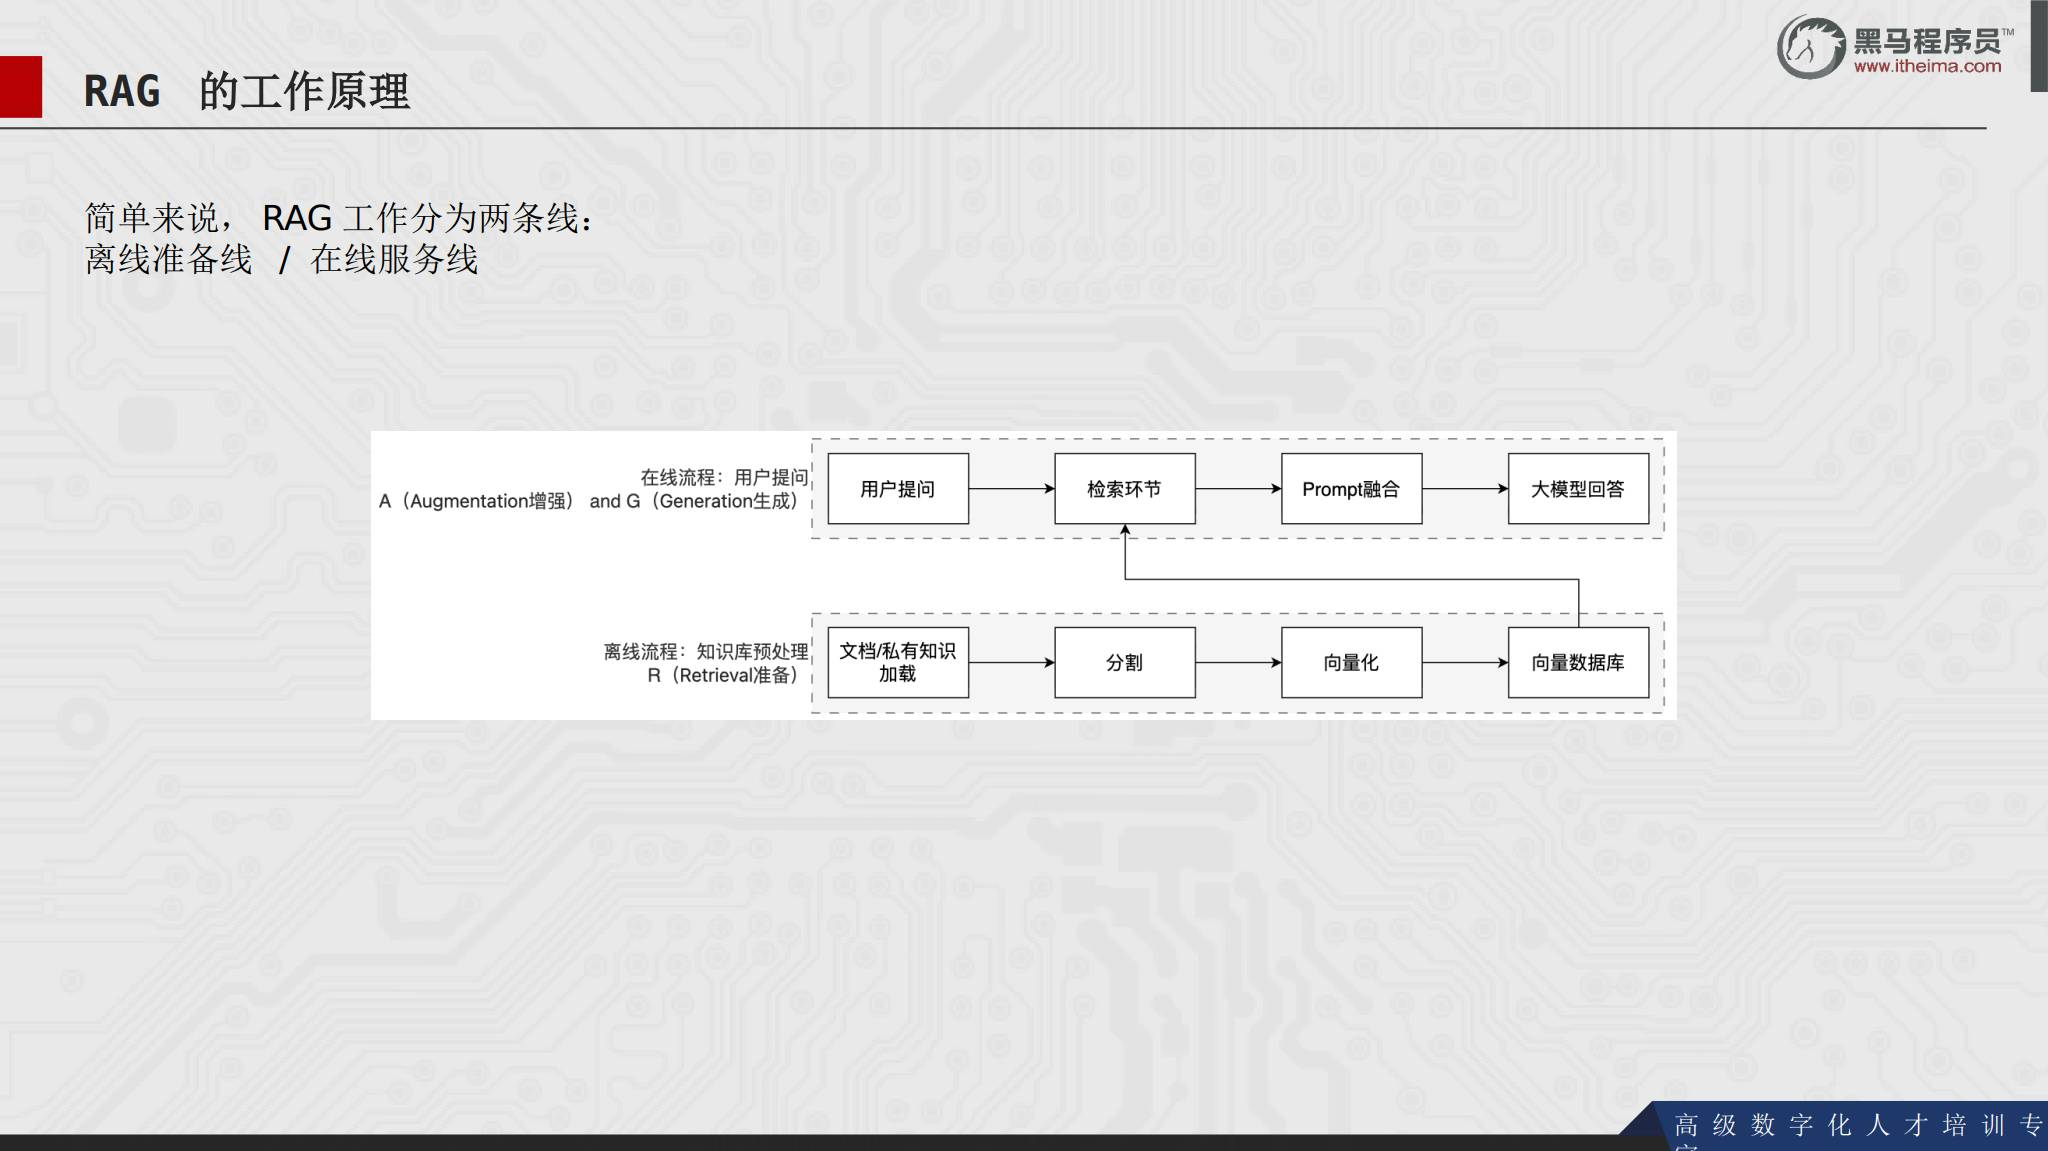


## 2. RAG 的离线线和在线线

RAG 分成两条相互配合的流程：

| 流程 | 主要工作 | 运行时机 |
| --- | --- | --- |
| 离线准备线 | 加载知识、提取内容、分割文本、向量化、写入向量数据库 | 知识库更新时 |
| 在线服务线 | 用户提问、问题向量化、相似度检索、拼接 Prompt、调用 LLM | 每次查询时 |

离线线把资料准备成可检索的索引，在线线只需检索相关片段并生成回答。

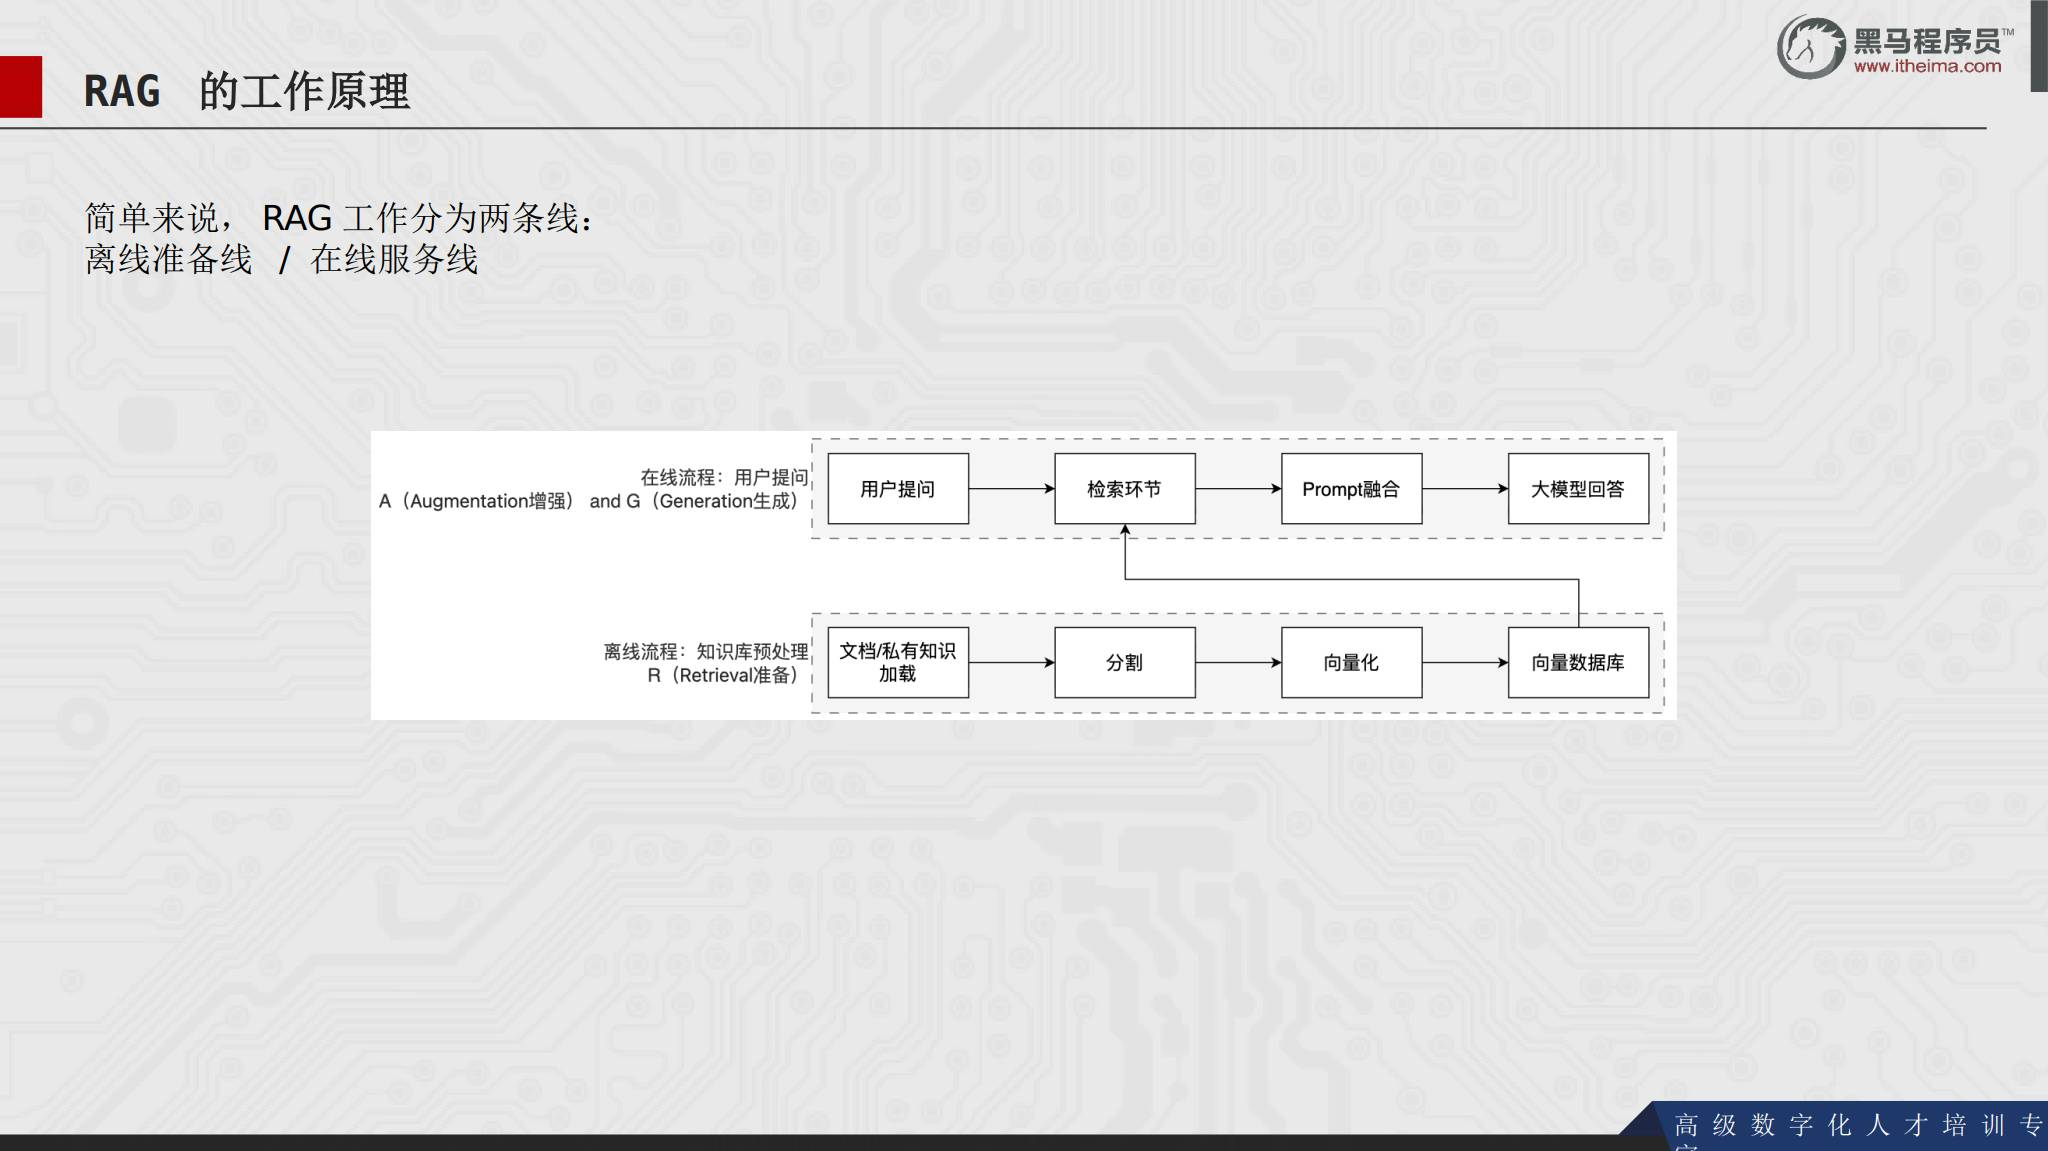


## 3. RAG 的标准流程

RAG 标准流程由索引、检索和生成三个阶段组成：

### 索引阶段

加载不同来源的文档，提取文本，分割成固定大小的 `chunk`，通过嵌入模型转换为向量，最后存入向量数据库。

### 检索阶段

用户输入的 `query` 也被转换为向量，与向量数据库中的文本向量做相似度匹配，取出最相关的 `top_k` 个文本块。

### 生成阶段

把检索到的文本作为上下文，与原始问题一起放入 Prompt，提交给 LLM 生成有上下文关联的答案。

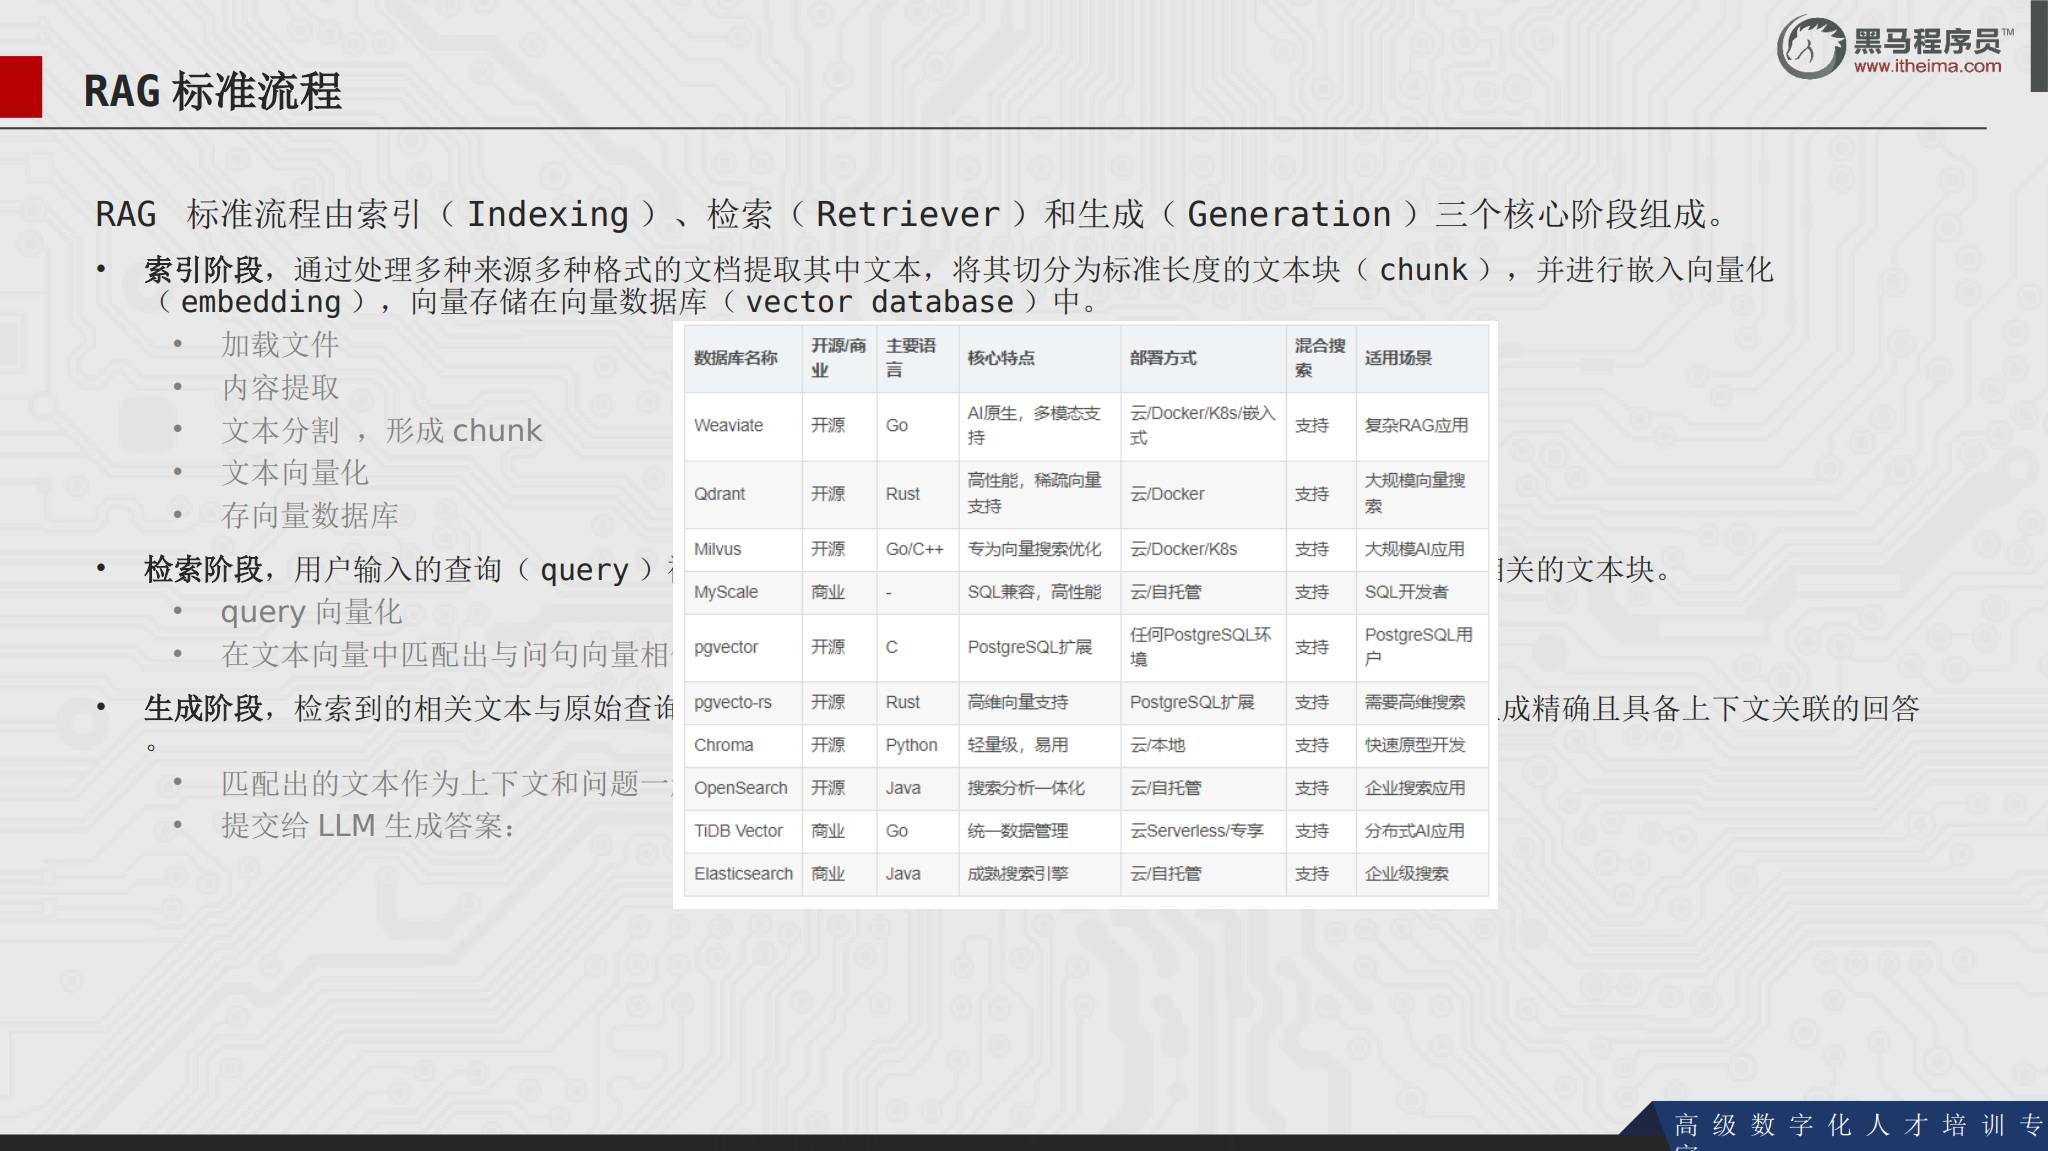


## 4. RAG 的核心价值

课程总结了 RAG 的三个主要价值：

1. **解决知识时效性问题**：可以接入最新的公司财报、政策文件等资料。
2. **降低模型幻觉**：回答基于检索到的事实资料，减少只凭模型记忆编造内容。
3. **无需重新训练模型**：更新知识库即可补充知识，相比微调成本更低、速度更快。

RAG 并不自动保证答案正确，资料质量、切片策略、嵌入模型和检索参数都会影响结果。


## 5. 向量是什么

向量可以理解为文本的“数学身份证”：把文本的语义信息转换成固定长度的数字列表，让计算机可以计算不同文本的相似程度。

例如，两种不同说法“如何快速学习 RAG”和“如何快速学会 RAG”可能表达相近含义，嵌入模型会把它们映射到相近的向量位置。课件中的数字只是说明概念，并不是真实模型输出。

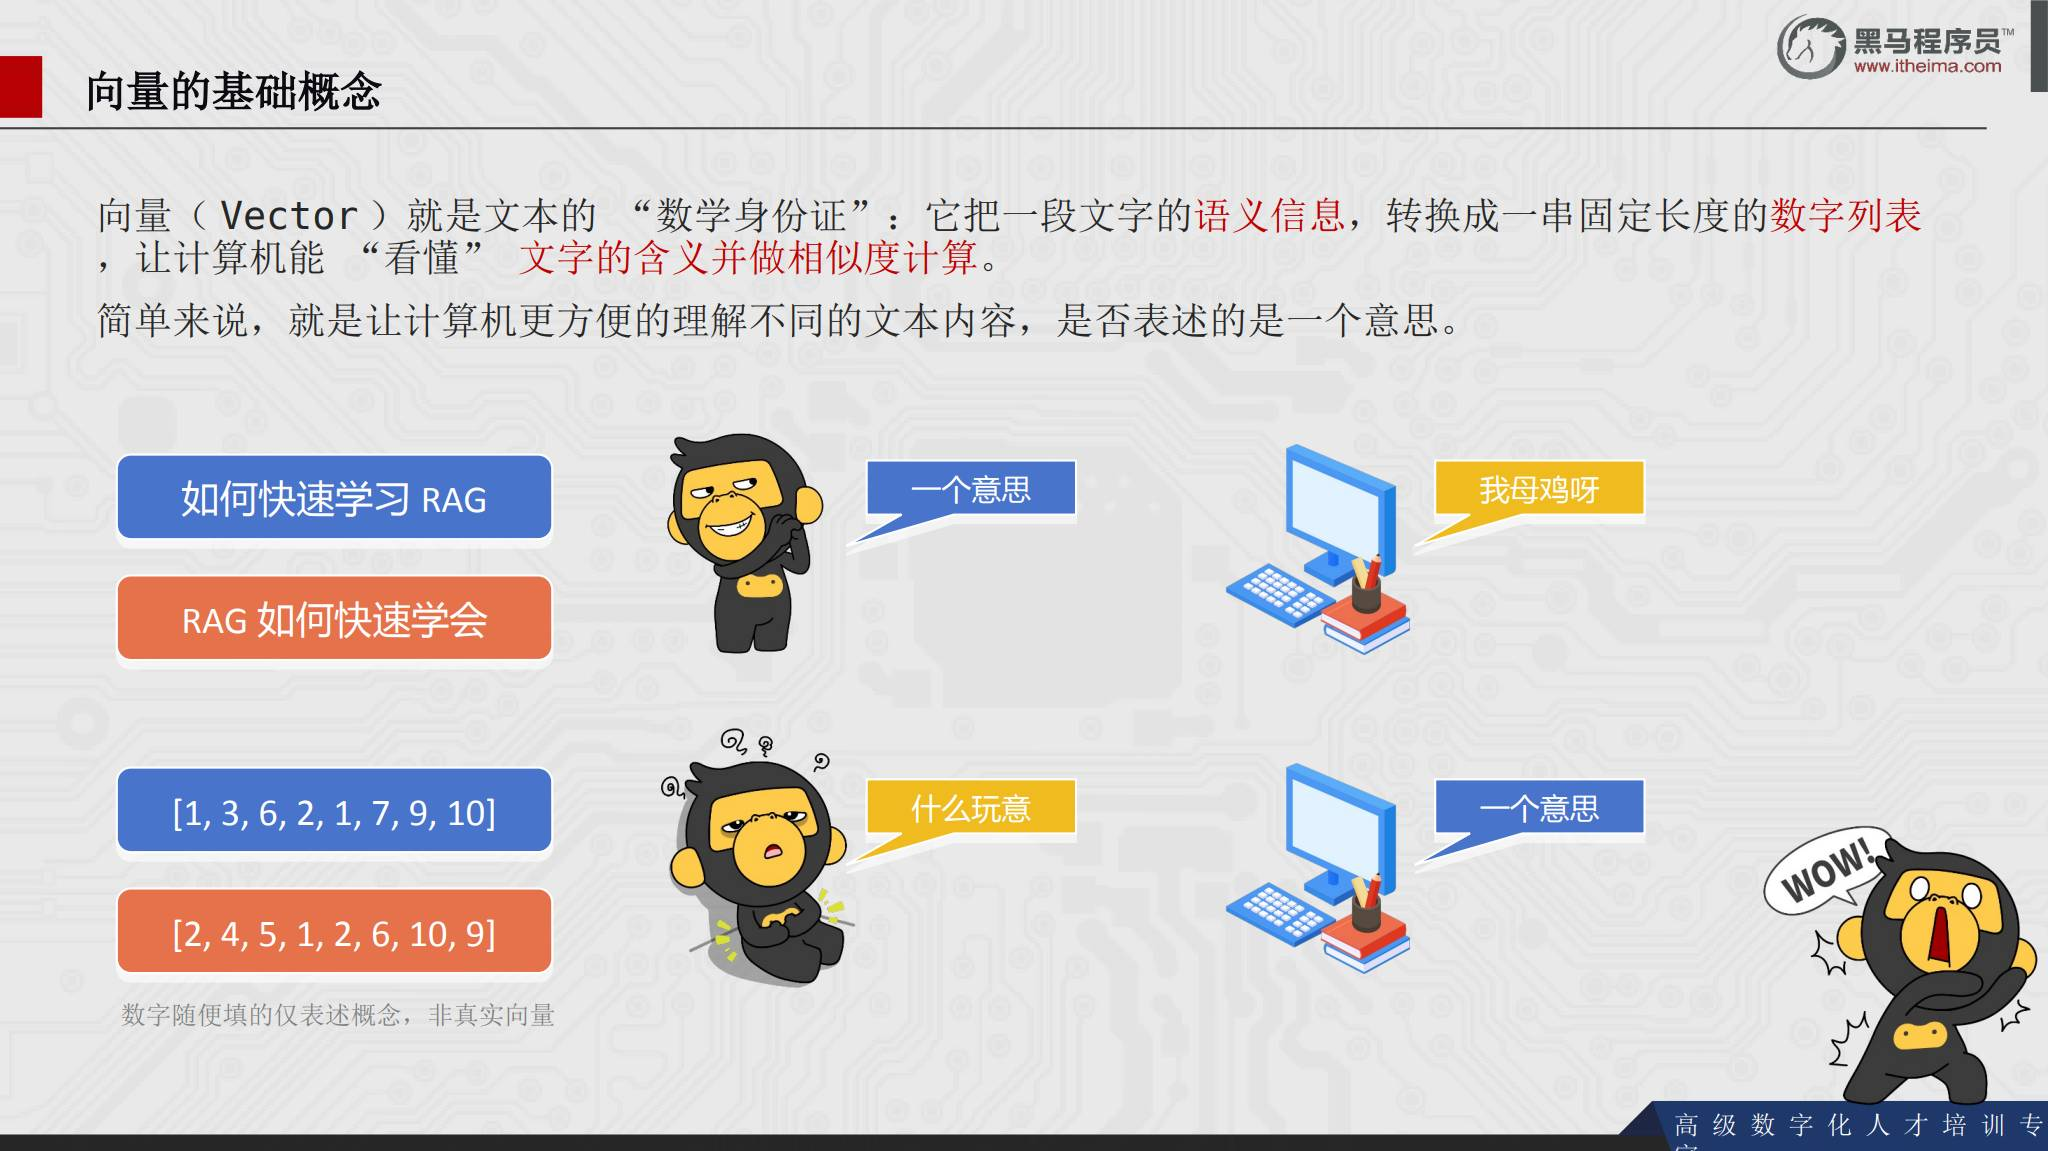


## 6. 嵌入模型与相似度匹配

嵌入模型接收文本，返回固定长度的浮点数列表。相似度算法再比较问题向量和文档向量的关系。

课件用以下示例说明：

```text
A：如何快速学打篮球 → [0.2, 0.5, 0.8]
B：打篮球怎么学得快 → [0.18, 0.52, 0.79]
C：运动后吃什么好呢 → [0.9, 0.1, 0.2]
```

A 与 B 的语义更接近，A 与 C 的相似度较低。实际系统不会手写这些数字，而是调用文本嵌入模型。

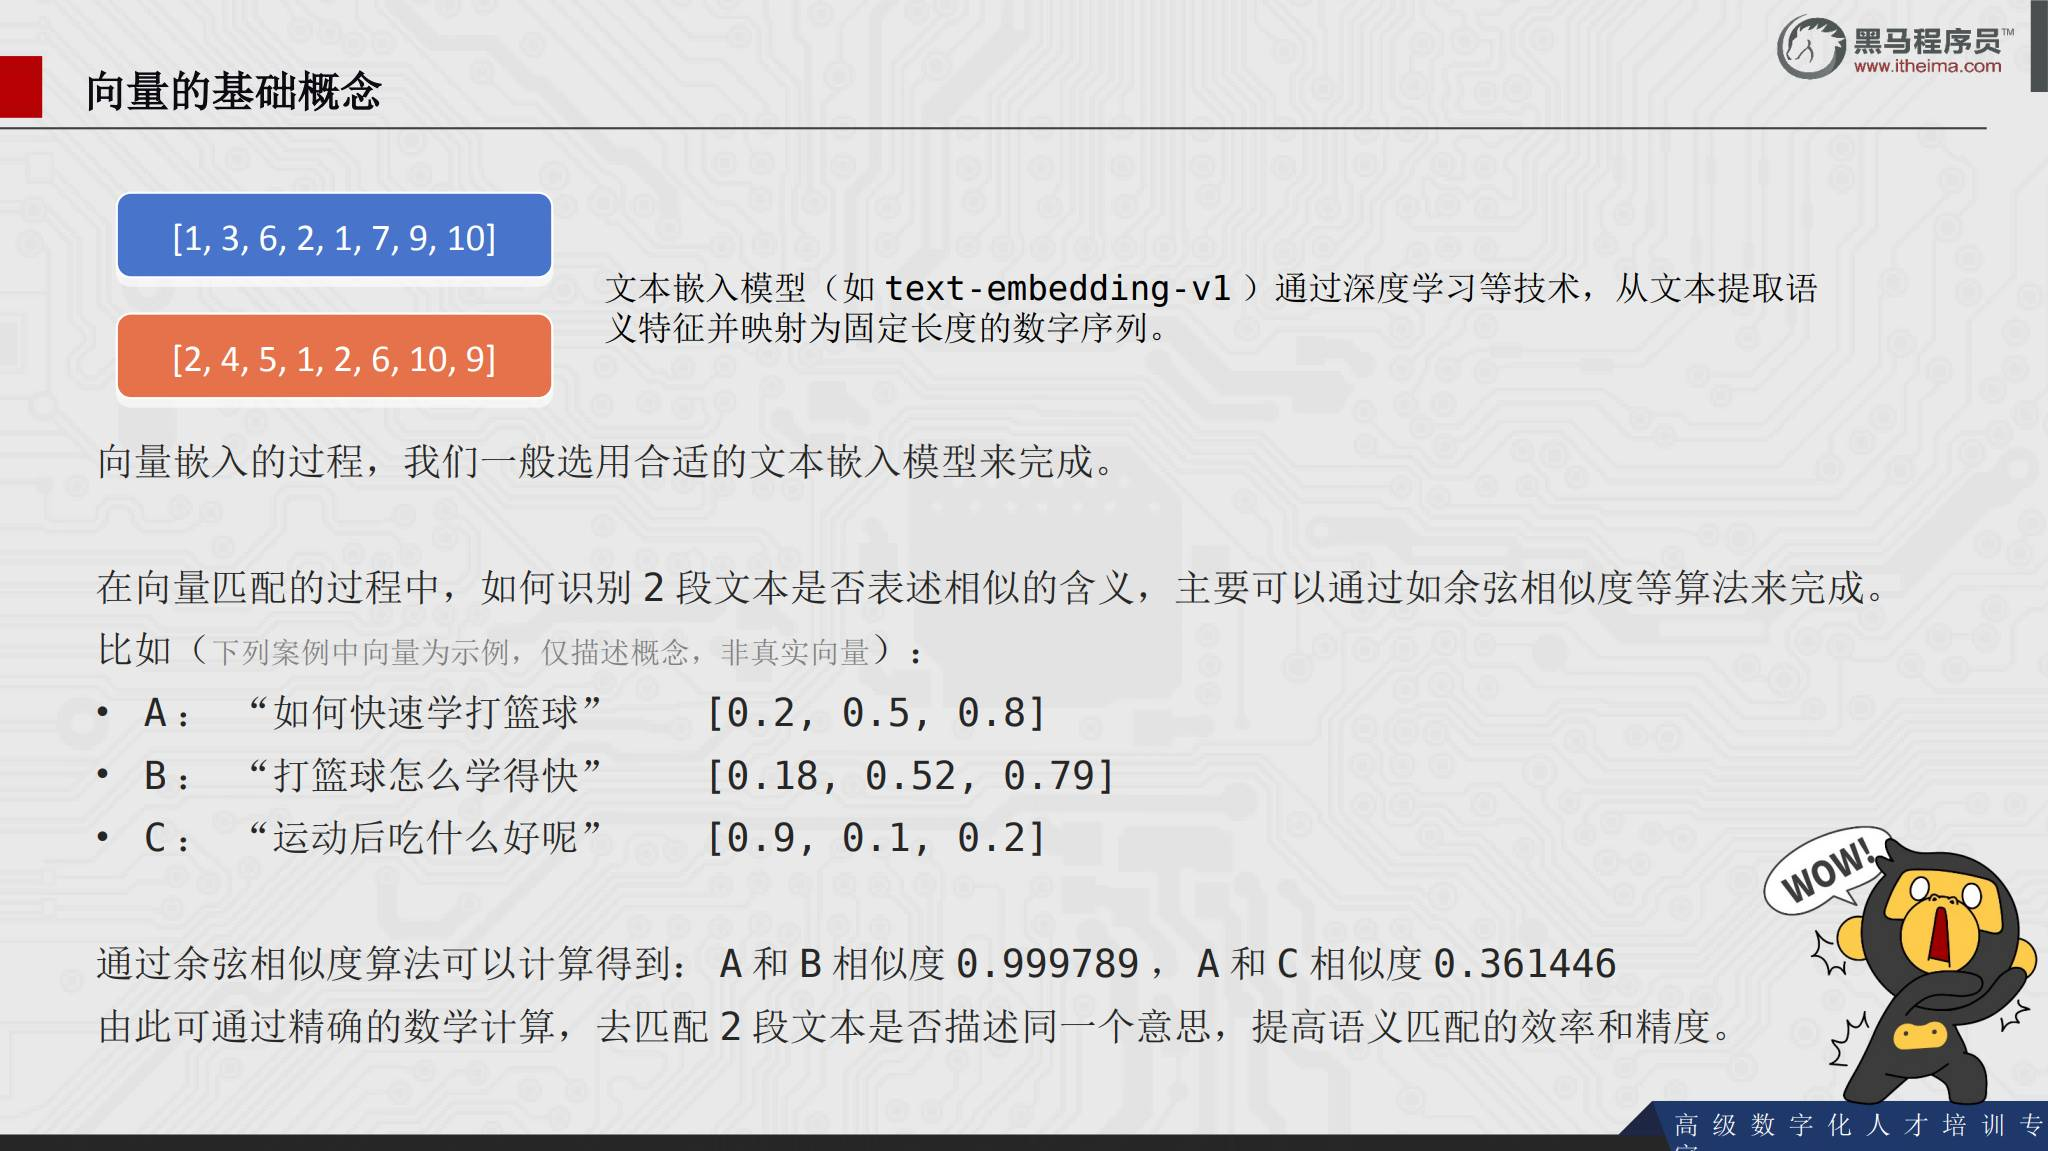


## 7. 向量维度的取舍

向量维度表示模型用多少个抽象语义特征描述文本。维度越多，通常能记录更细的语义特征，匹配可能更精确；但向量存储、计算和检索的压力也会增大。

课件以 `text-embedding-v1` 的 1536 维向量作为实用示例。选择维度需要在精确度和性能之间平衡，不能只追求更高维度。


## 8. 余弦相似度

余弦相似度主要比较两个向量的方向，减弱向量长度差异的影响。夹角越小，方向越接近，文本语义通常越相似。

公式是：

```text
cosine_similarity(A, B) = A · B / (||A|| × ||B||)
```

其中 `A · B` 是对应维度乘积之和，`||A||` 和 `||B||` 是向量模长。课件用二维向量说明：同向但长度不同的 `[0.5, 0.5]` 和 `[0.7, 0.7]` 相似度为 1；方向相反的向量相似度接近 -1。

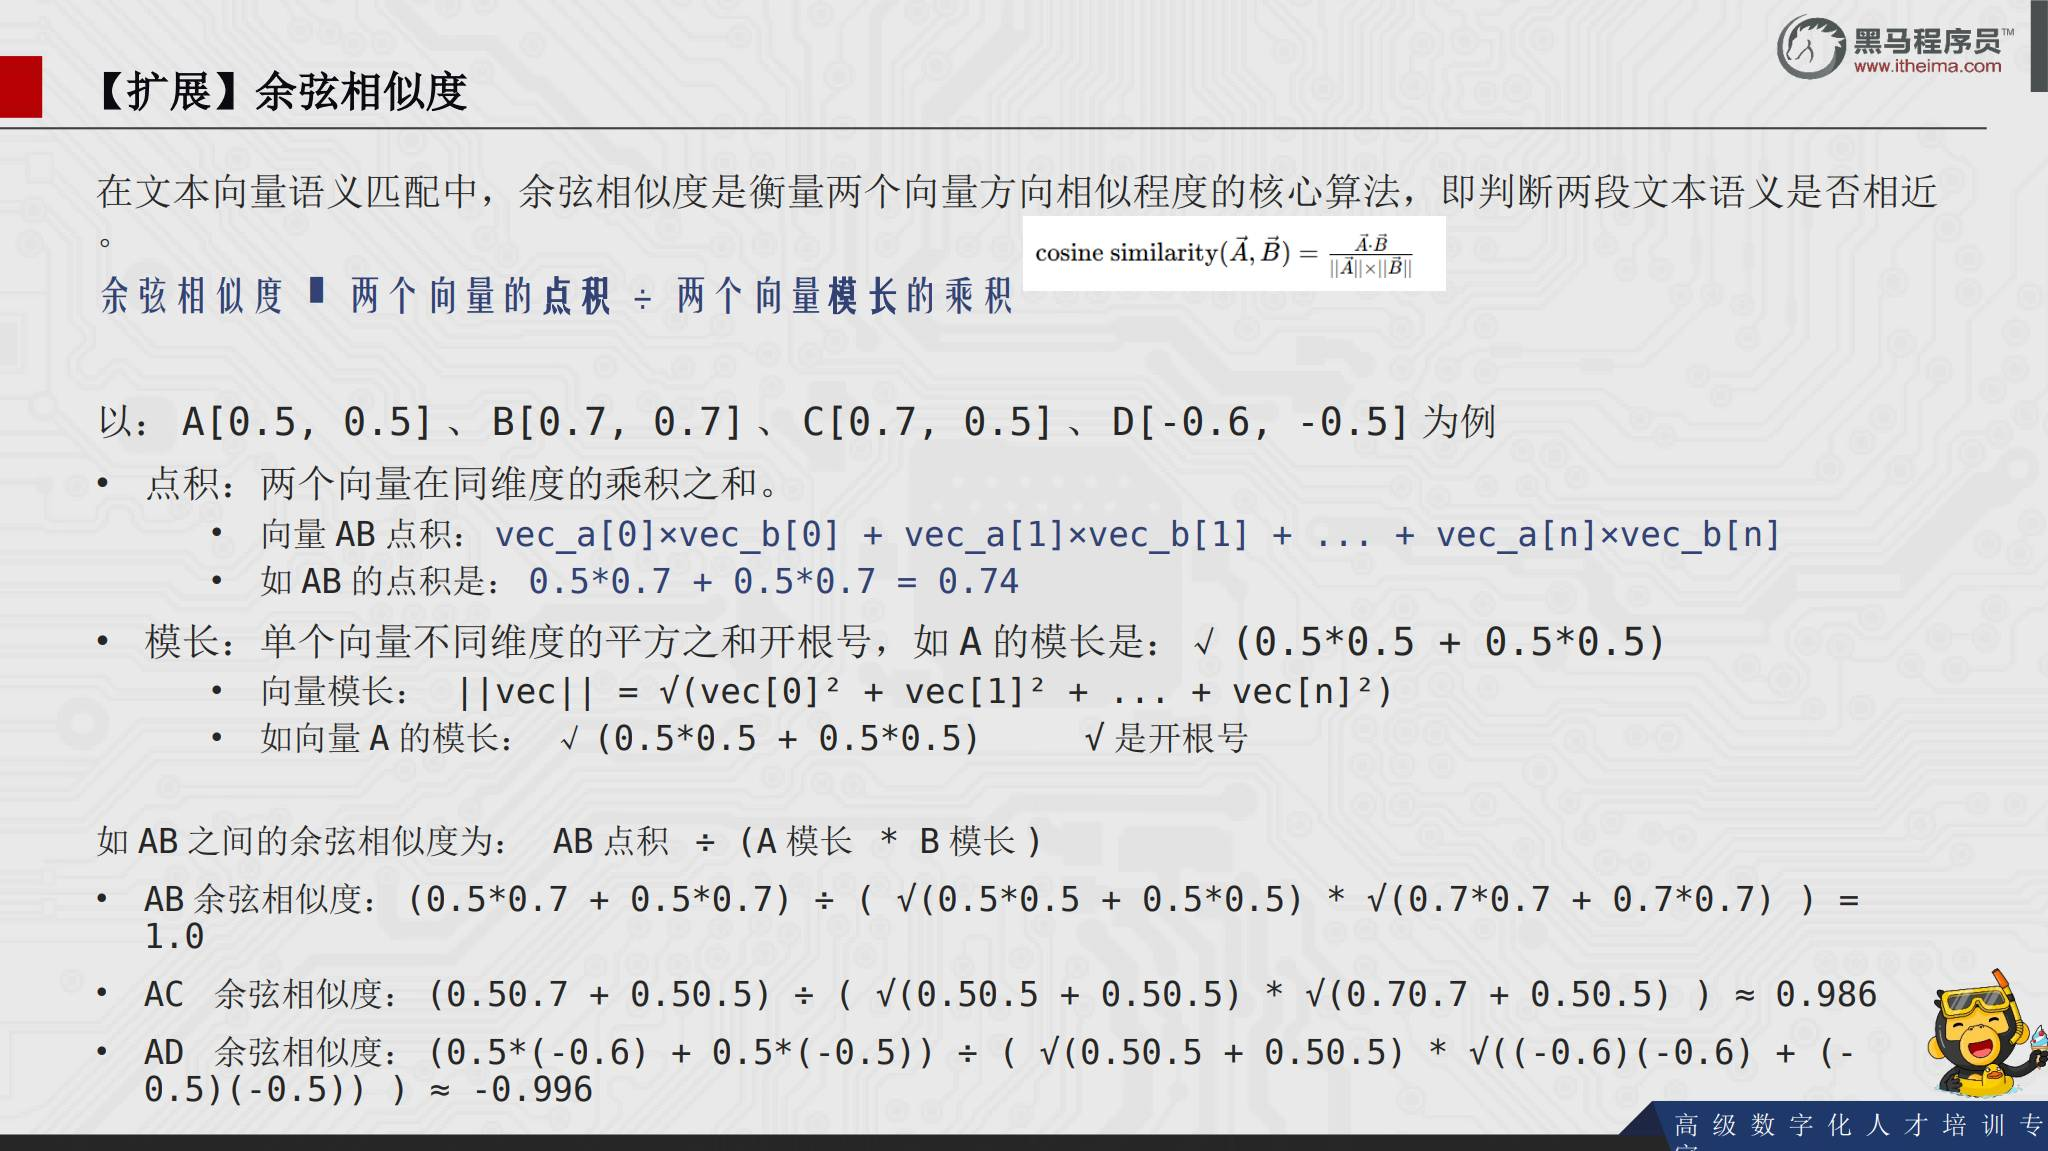


## 9. LangChain 是什么

LangChain 由 Harrison Chase 创建，是围绕大语言模型建立的 Python 框架。它不负责开发 LLM，而是为不同模型和应用组件提供通用接口，把模型、提示词、文档、记忆、链和 Agent 连接起来。

课件将 LangChain 的功能概括为：

| 组件 | 作用 |
| --- | --- |
| Prompts | 优化和组织提示词 |
| Models | 调用不同类型的模型 |
| History | 管理会话历史 |
| Indexes | 管理和分析文档 |
| Chains | 构建功能执行链 |
| Agent | 构建智能体 |

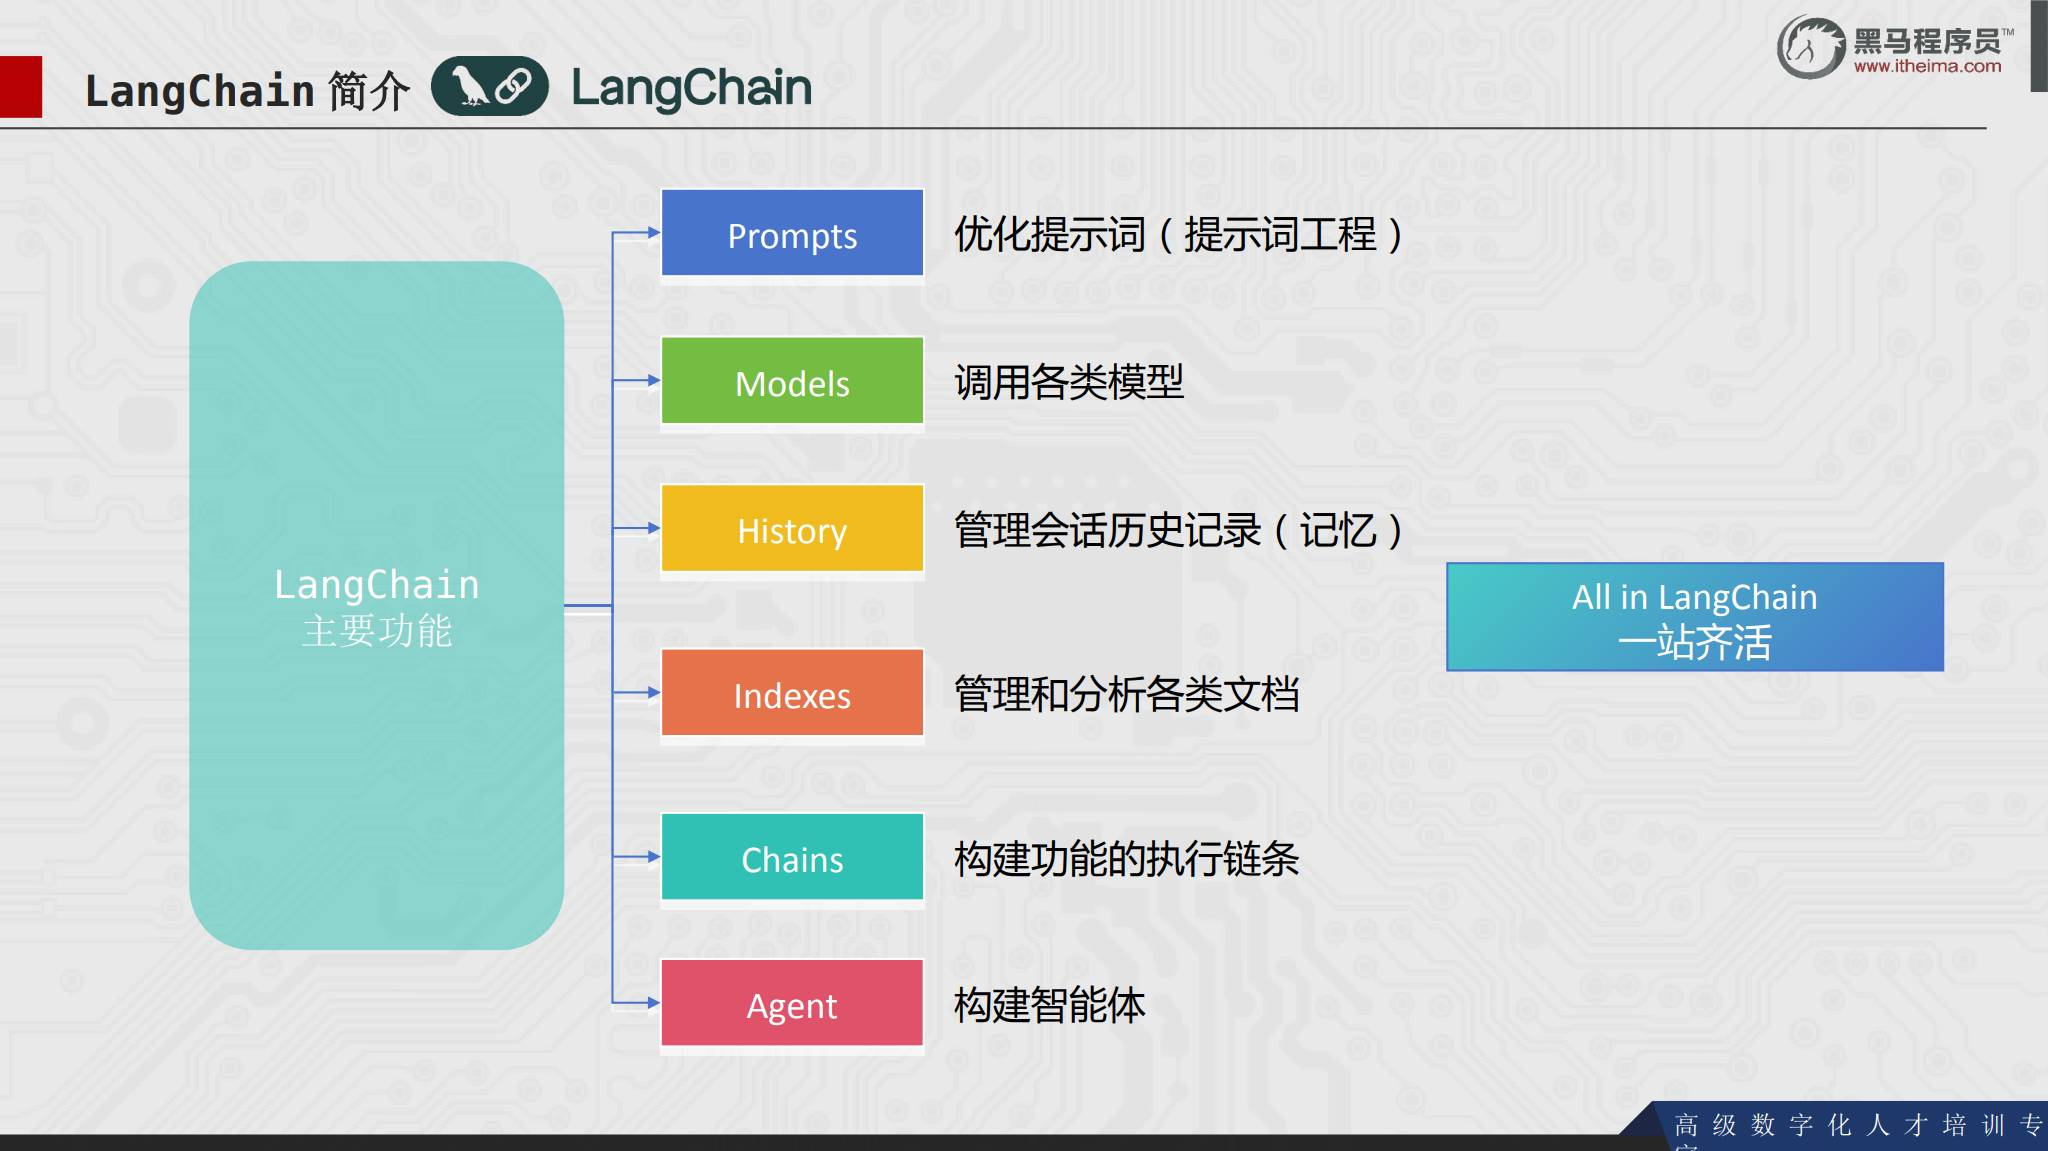


## 10. LangChain 环境安装

课件给出的安装命令是：

```bash
pip install langchain langchain-community langchain-ollama langchain-chroma dashscope chromadb bs4 jq
```

各包的作用：

- `langchain`：核心包。
- `langchain-community`：社区集成包，包含通义千问等第三方模型调用。
- `langchain-ollama`：调用 Ollama 本地模型。
- `langchain-chroma`：调用 Chroma 向量存储。
- `dashscope`：阿里云通义千问 Python SDK。
- `chromadb`：轻量向量数据库。
- `bs4`：解析 HTML 文档。
- `jq`：JSONLoader 的 JSON 查询依赖。


## 11. LangChain 的三类模型

LangChain 为不同模型提供统一接口，课程分为三类：

| 类型 | 输入和输出 | 主要场景 |
| --- | --- | --- |
| LLM | 文本输入，文本输出 | 普通文本生成 |
| Chat Model | 消息列表输入，消息输出 | 多轮对话 |
| Embeddings Model | 文本输入，向量输出 | 向量化和语义检索 |

开发时先根据任务选择模型类型，再选择具体服务商和模型名称。


## 12. 调用通义千问 LLM

课件使用 `langchain_community` 中的 `Tongyi`：

```python
from langchain_community.llms.tongyi import Tongyi

llm = Tongyi(model="qwen-max")
result = llm.invoke("帮我讲个笑话吧")
print(result)
```

`invoke()` 一次返回完整结果。云端模型所需的访问凭证应通过环境变量等方式配置，不要写入公开代码。

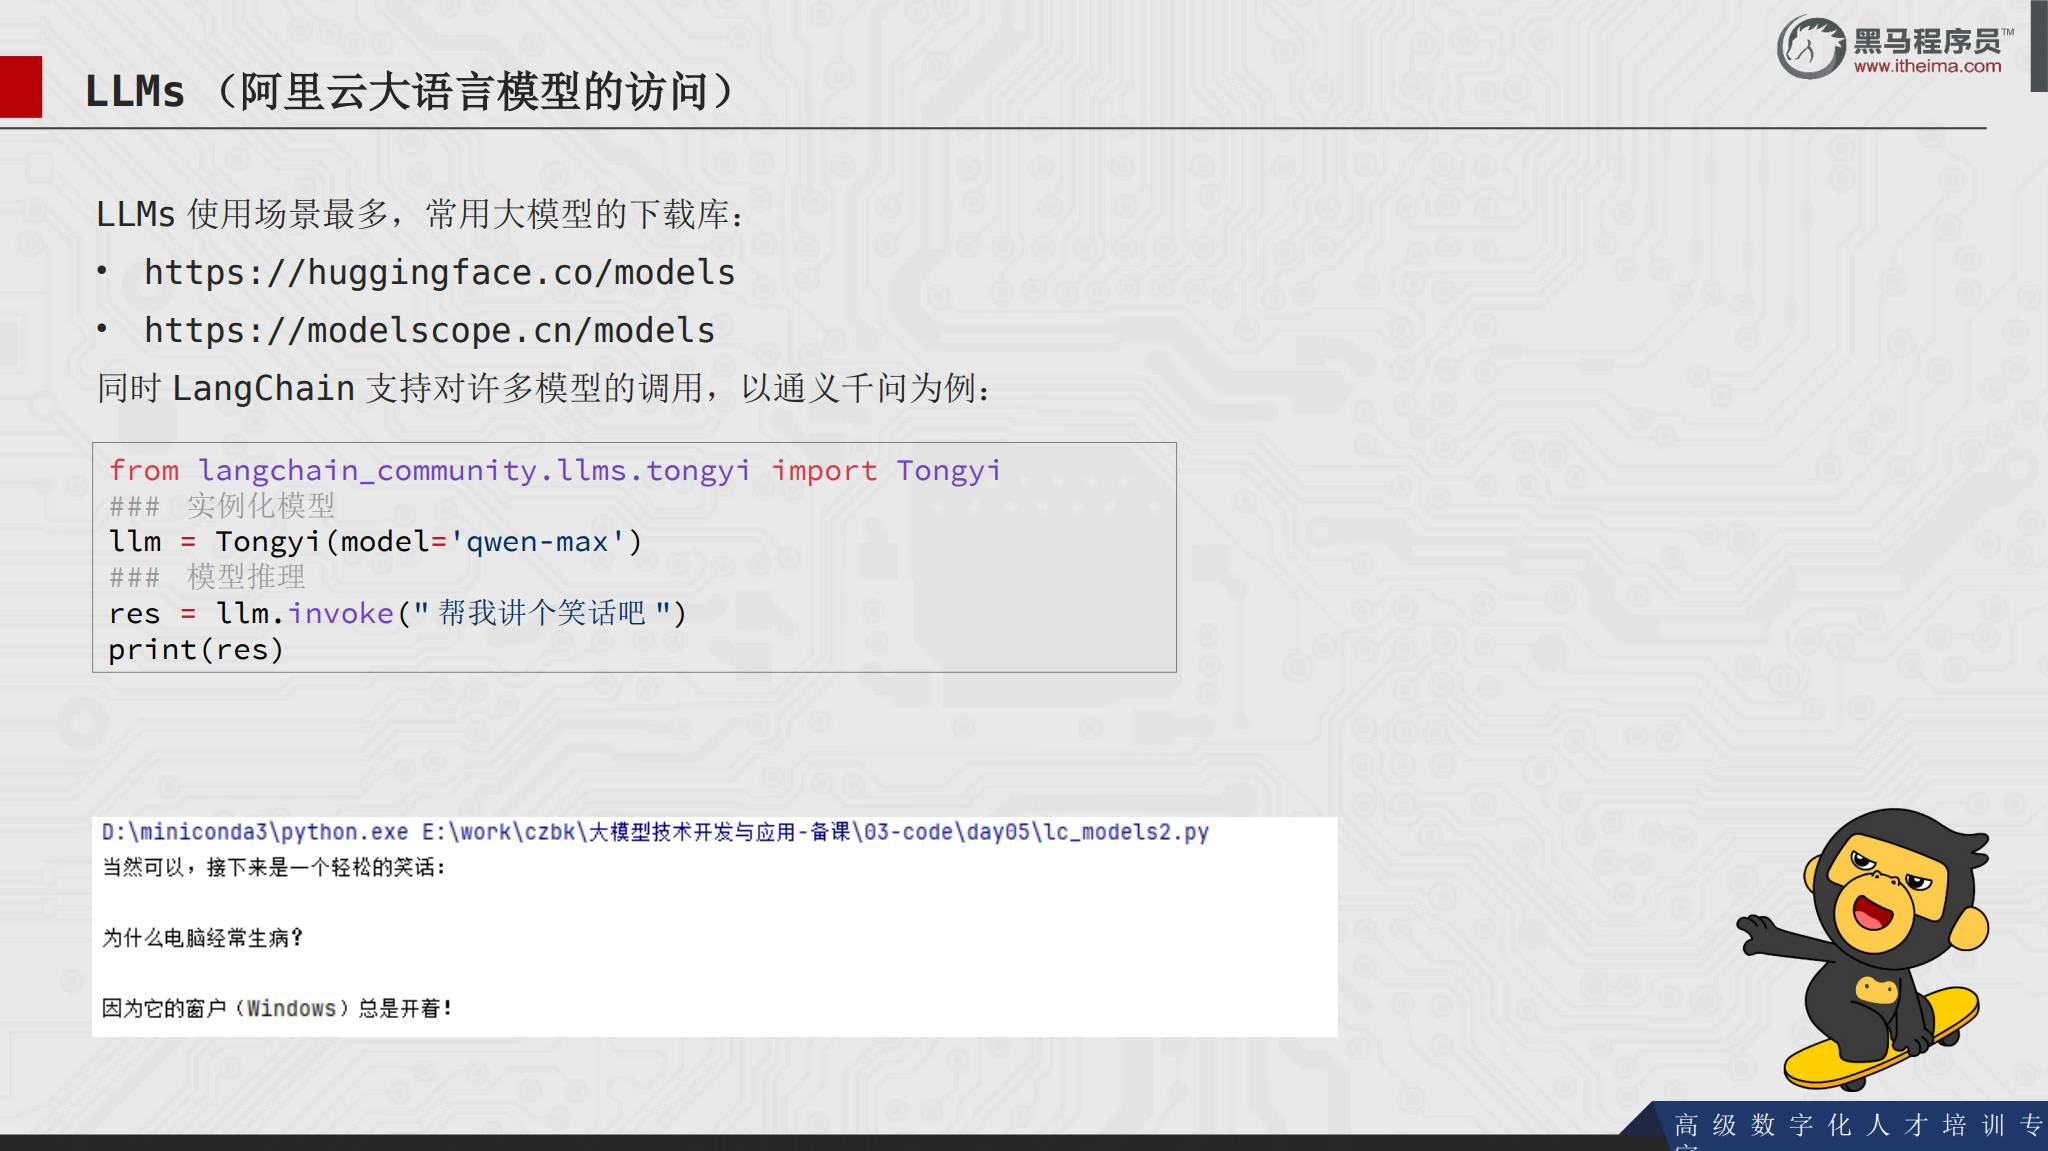


## 13. 调用 Ollama 本地模型

确保 Ollama 已启动，并且本地已经下载目标模型：

```python
from langchain_ollama import OllamaLLM

model = OllamaLLM(model="qwen3:4b")
result = model.invoke("你是谁呀，能做什么？")
print(result)
```

云端 Tongyi 和本地 `OllamaLLM` 的调用方式一致，主要变化是导入的模型类和模型名称。

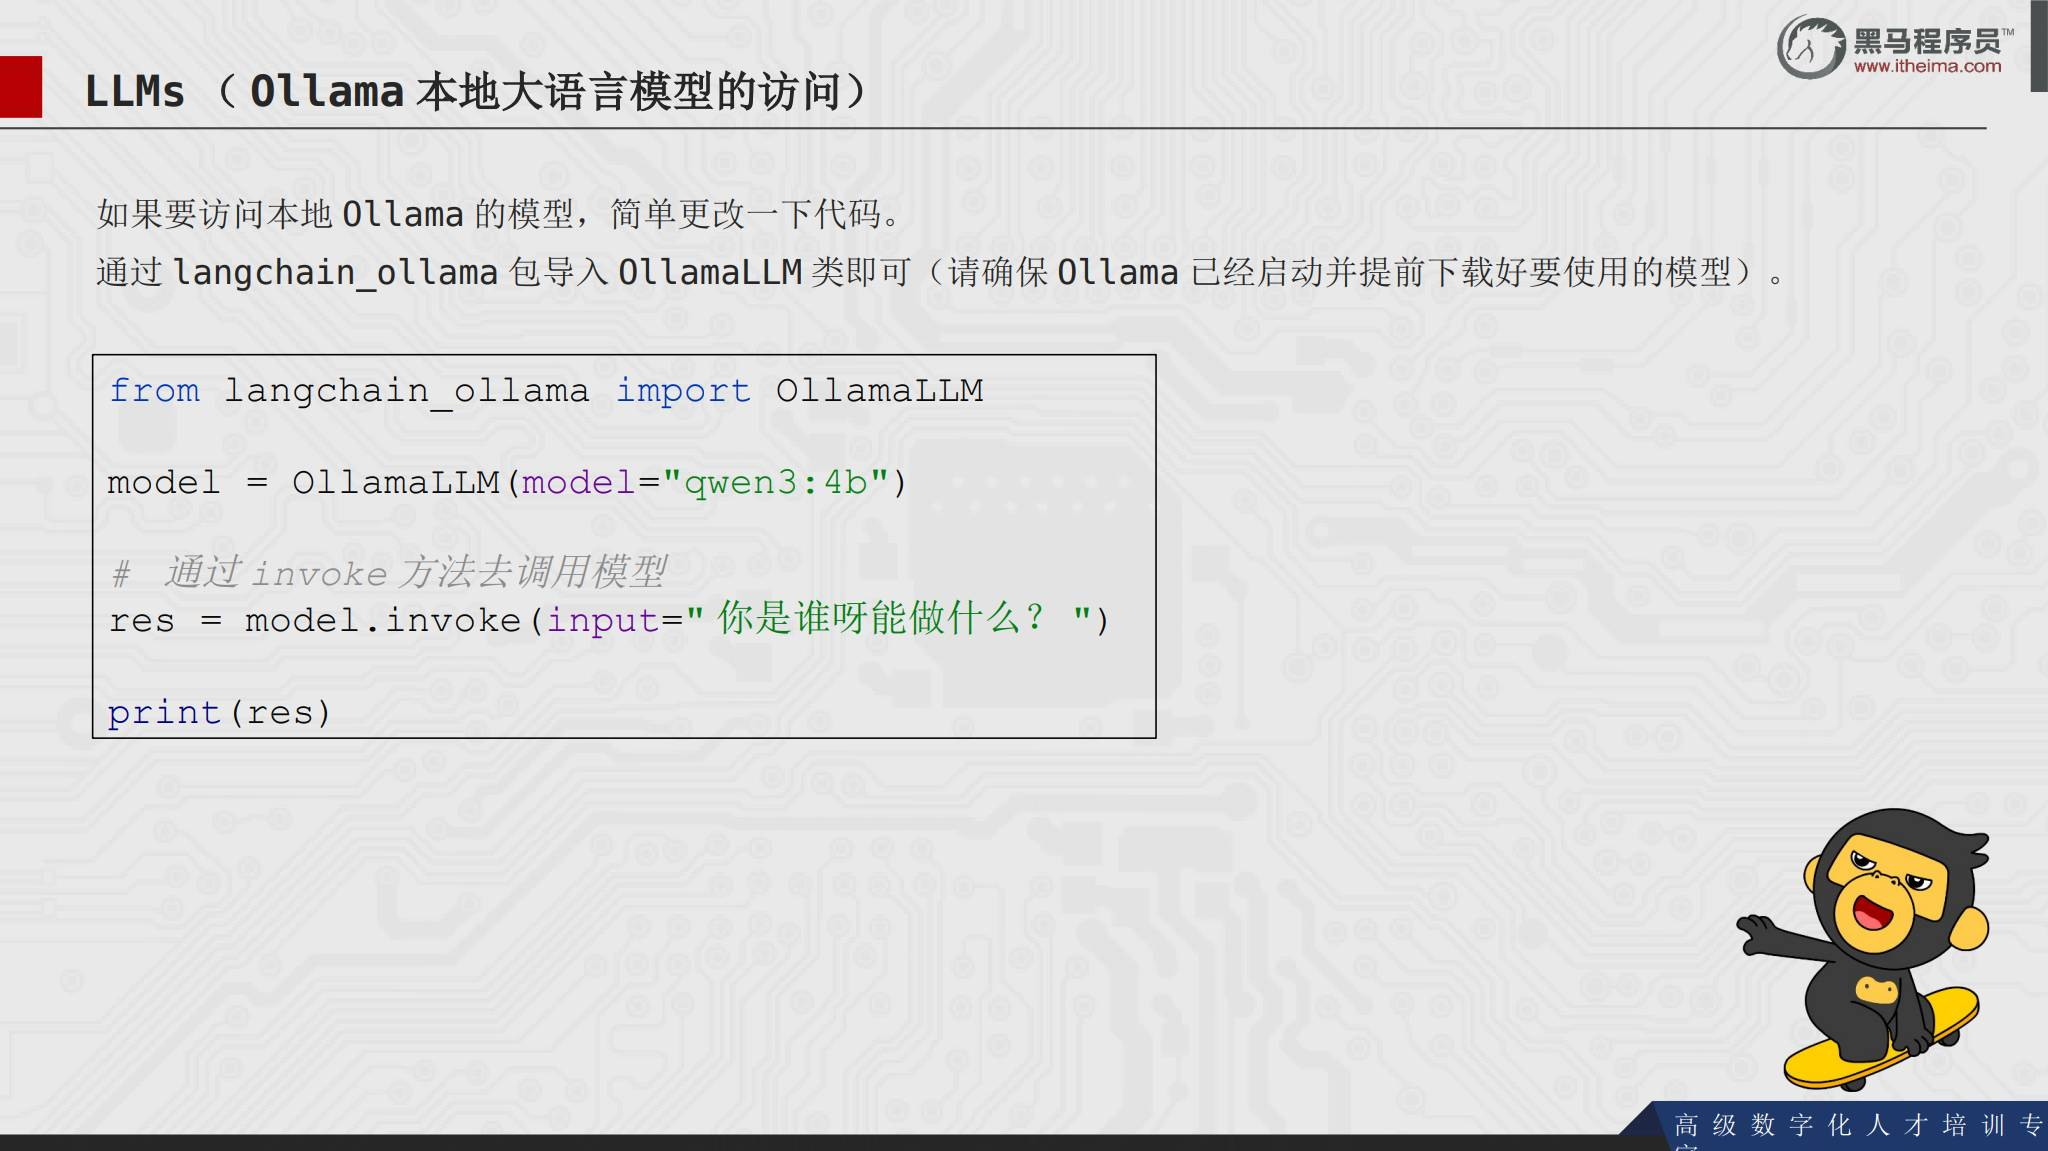


## 14. `invoke` 与 `stream`

模型对象提供两个通用调用方法：

- `invoke`：一次返回完整结果。
- `stream`：逐段返回结果，适合流式输出。

```python
model = Tongyi(model="qwen-max")
for chunk in model.stream("你是谁呀，能做什么？"):
    print(chunk, end="", flush=True)
```

课件强调，LangChain 1.0 之后，提示词模板、链、向量检索和工具等多数组件都遵循 Runnable 接口，因此通常也支持 `invoke` 和 `stream`。

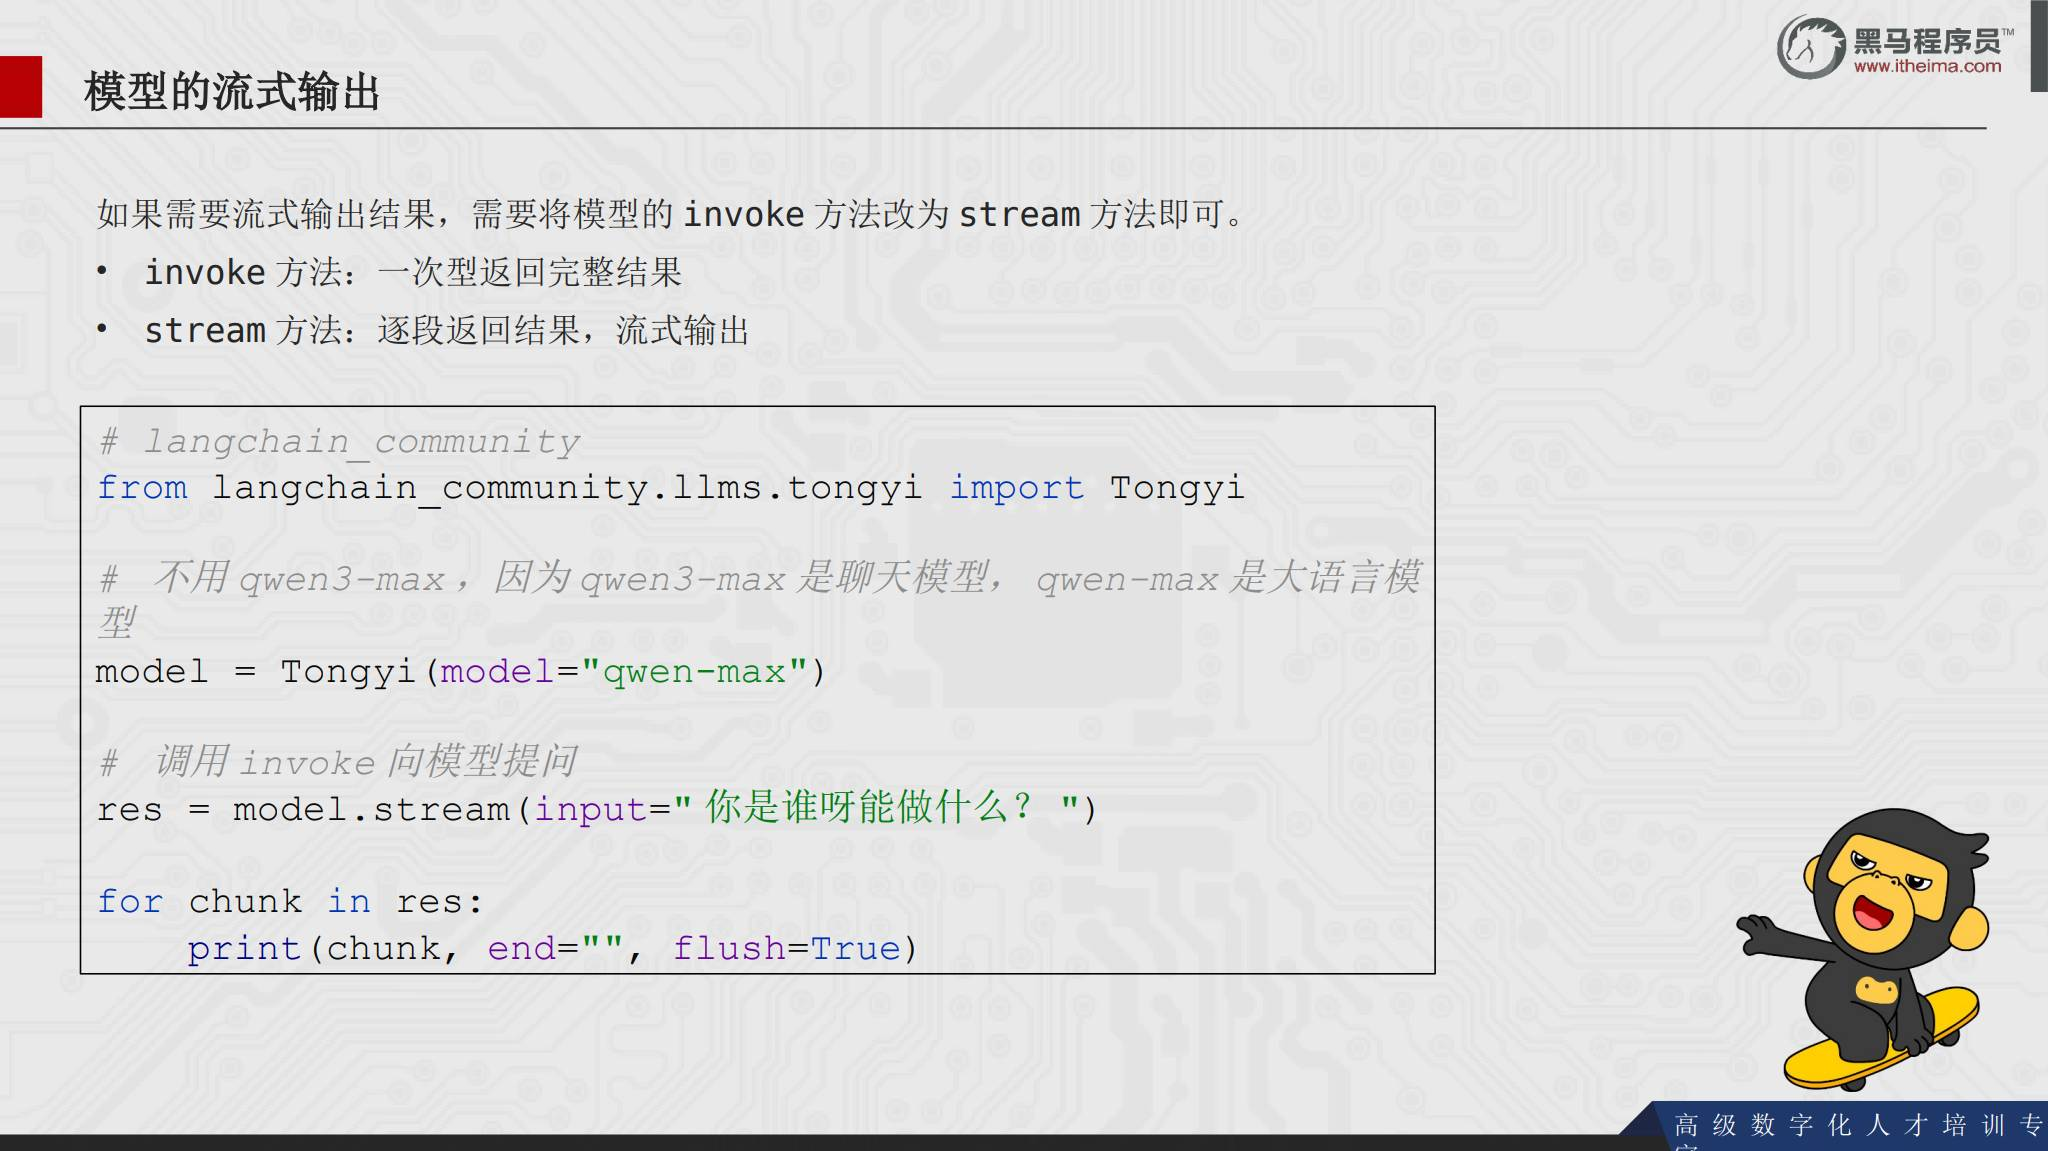


## 15. Chat Model 的消息类型

聊天模型使用消息对象表达对话上下文：

| LangChain 类型 | 对应角色 | 作用 |
| --- | --- | --- |
| `HumanMessage` | `user` | 用户输入 |
| `AIMessage` | `assistant` | 模型回答 |
| `SystemMessage` | `system` | 角色、背景和规则 |

使用 `ChatTongyi` 时，可以把消息列表传给 `stream()`：

```python
from langchain_community.chat_models.tongyi import ChatTongyi
from langchain_core.messages import HumanMessage, SystemMessage

chat = ChatTongyi(model="qwen3-max")
messages = [
    SystemMessage(content="你是一名来自边塞的诗人"),
    HumanMessage(content="给我写一首唐诗"),
]
for chunk in chat.stream(messages):
    print(chunk.content, end="", flush=True)
```

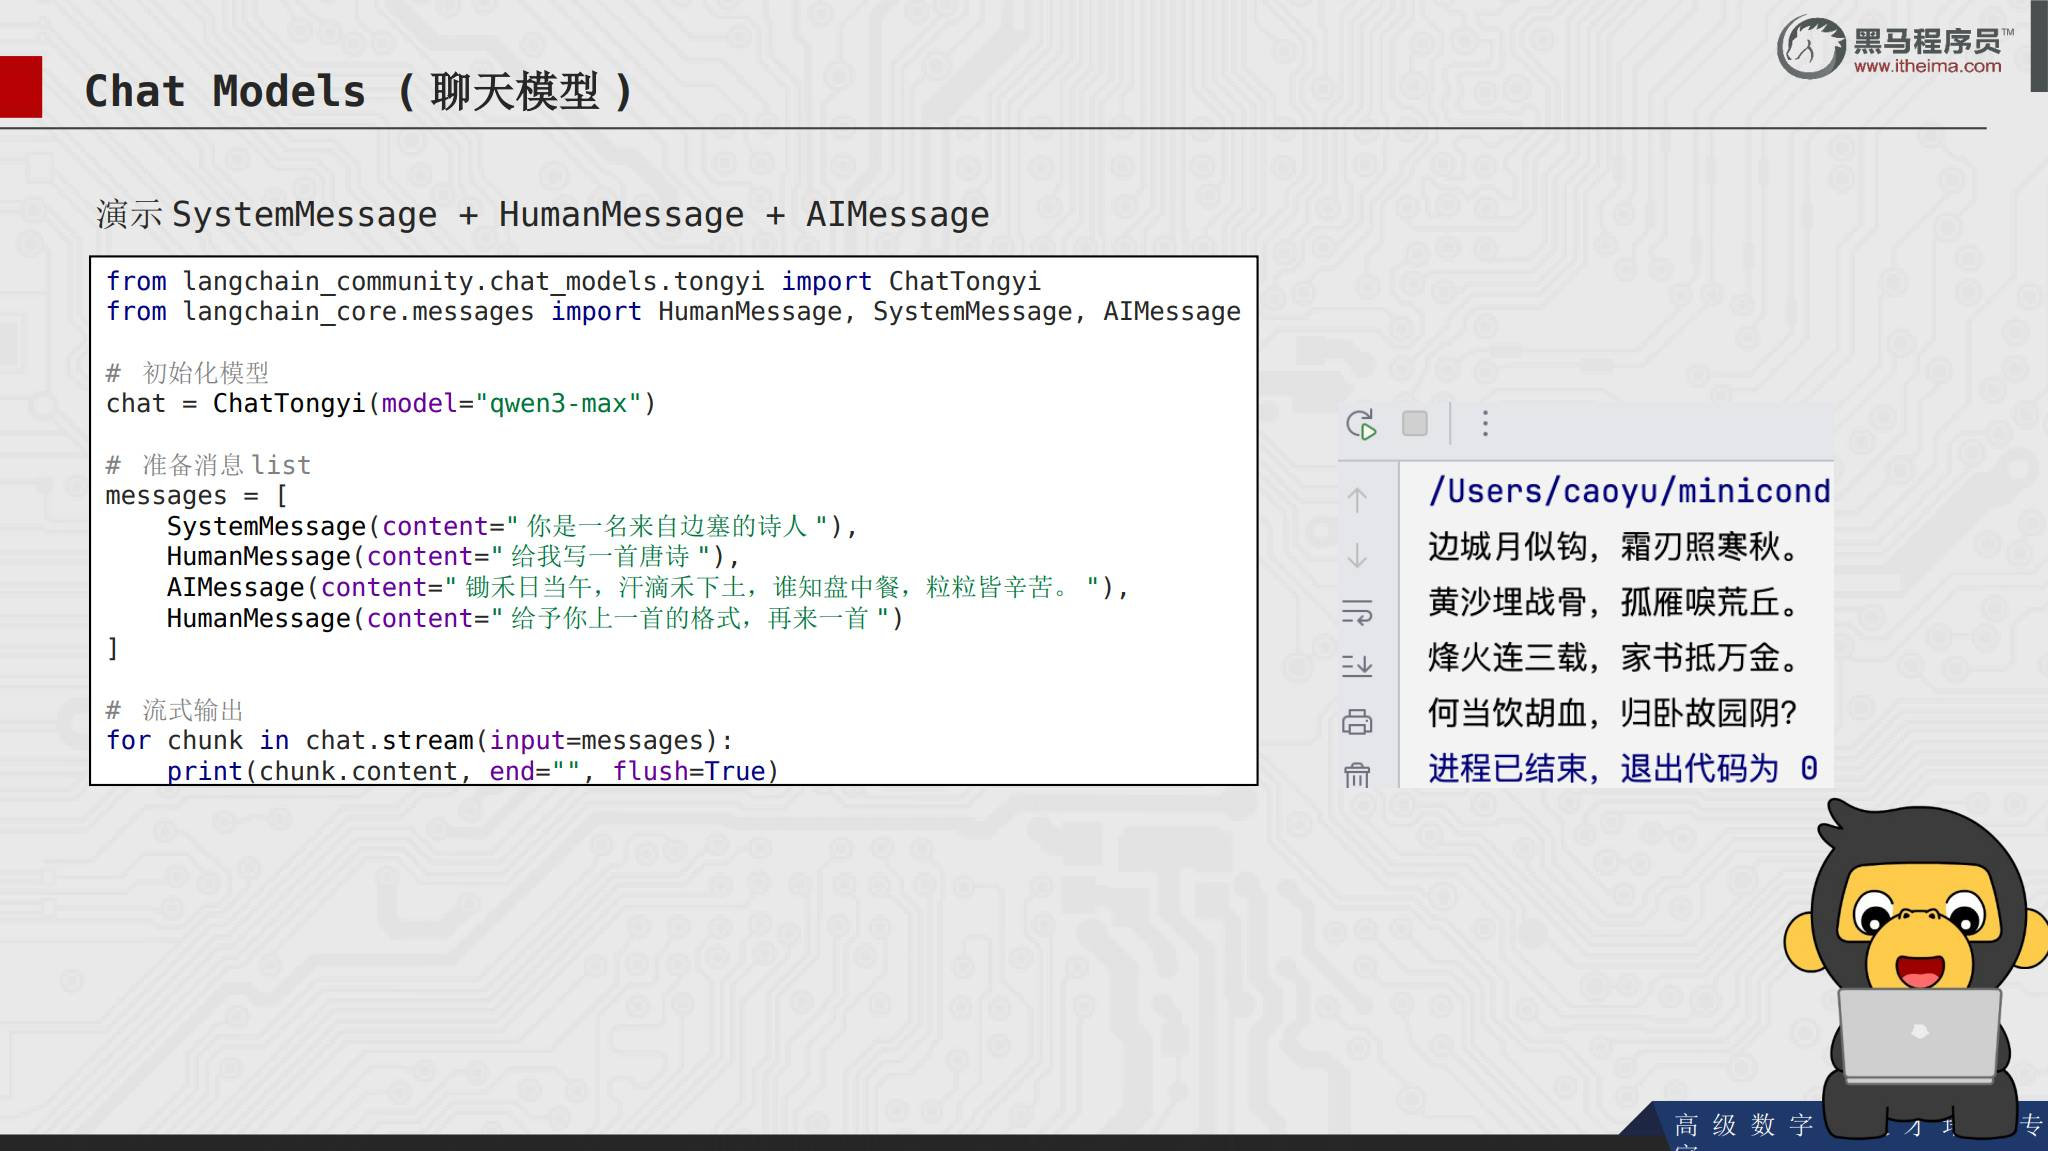


## 16. 消息的元组简写

消息也可以用二元组表示：

```python
messages = [
    ("system", "你是一个边塞诗人。"),
    ("human", "写一首唐诗"),
    ("ai", "锄禾日当午，汗滴禾下土。"),
    ("human", "按照上一个回复的格式再写一首。"),
]
```

简写形式更少导包，也支持 `{变量}` 占位符，在运行时动态填充值；消息类对象则是已经构造好的静态消息。

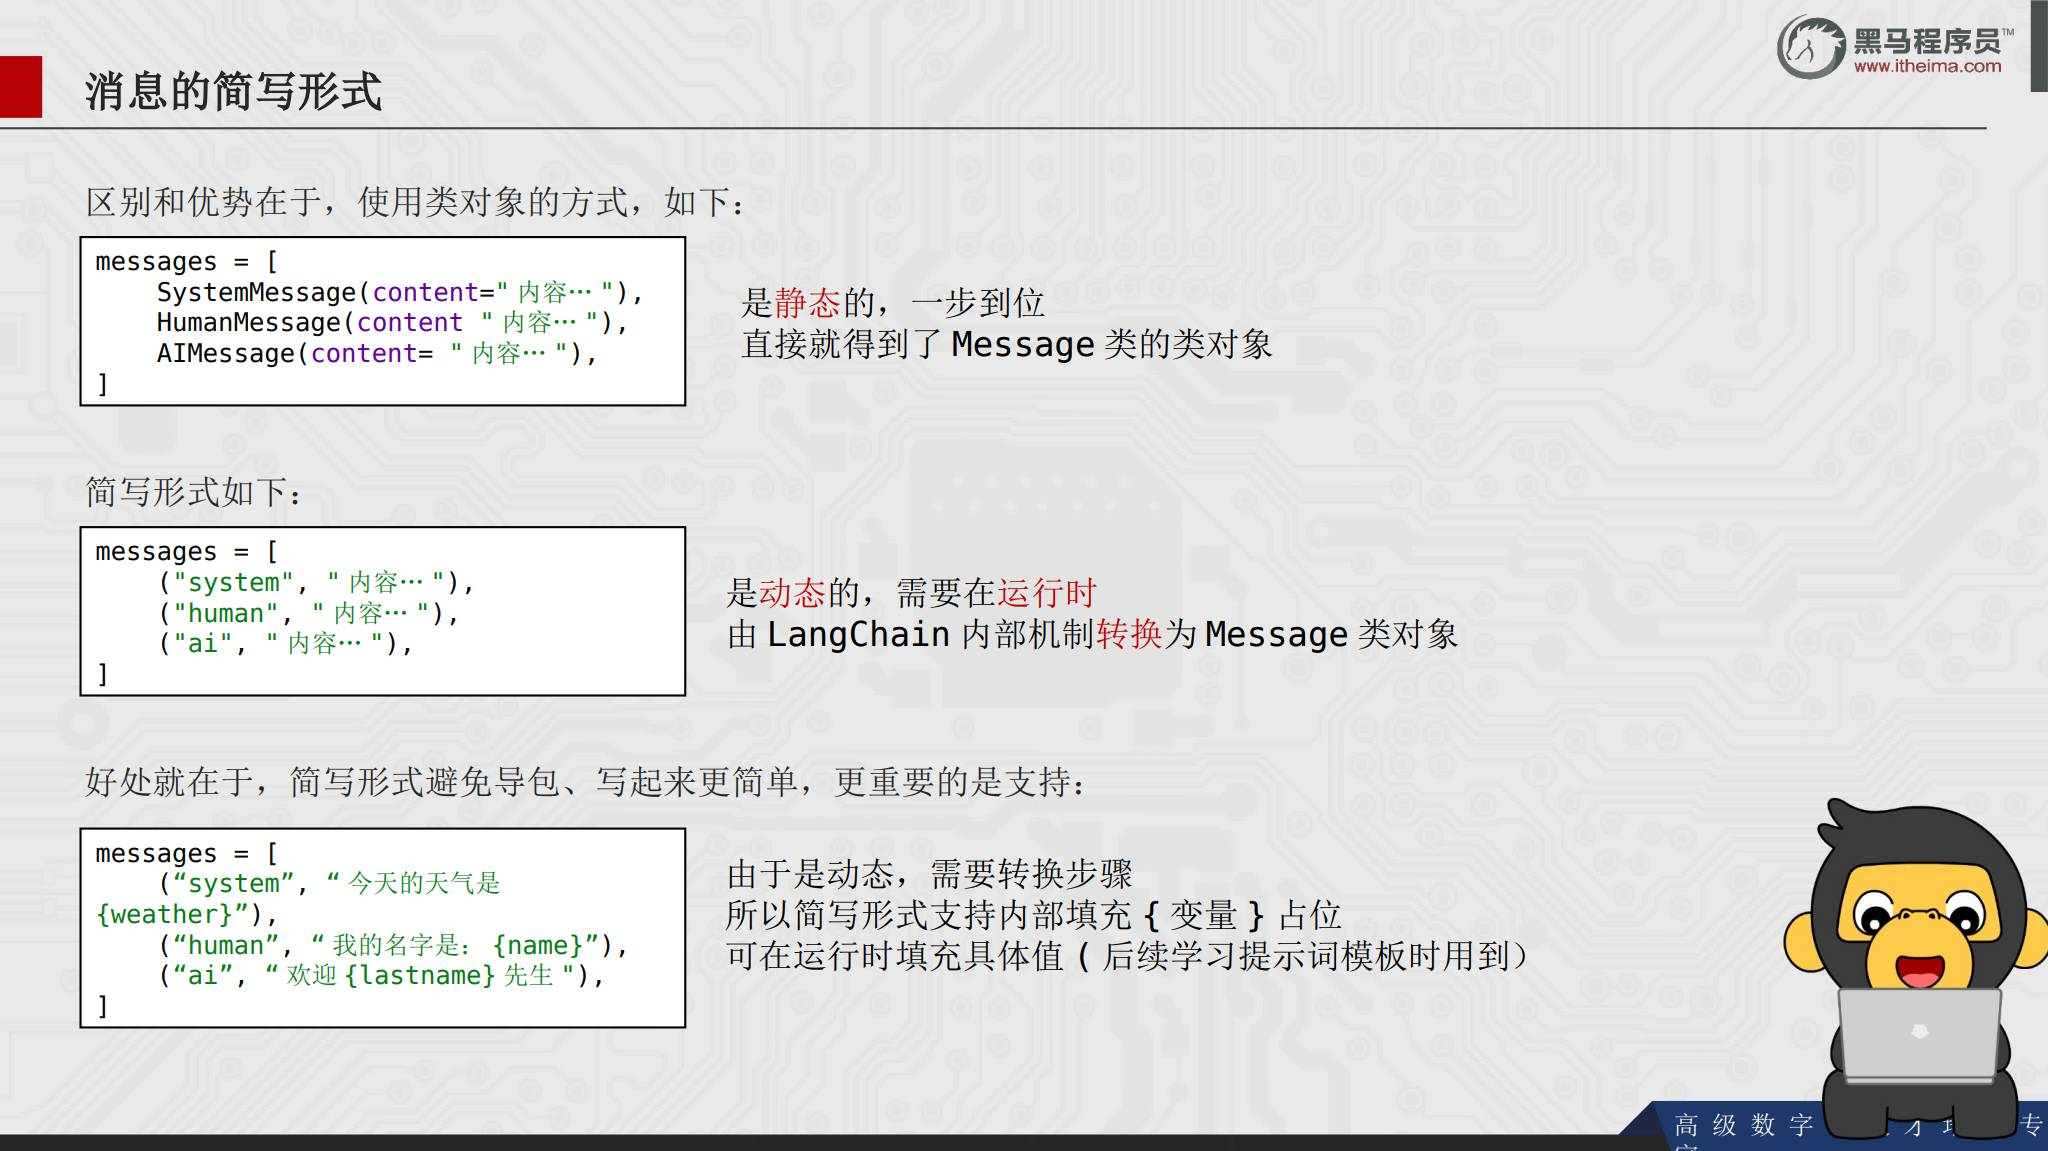


## 17. Embeddings 模型

嵌入模型接收字符串，返回浮点数列表，也就是文本向量。

阿里云嵌入模型：

```python
from langchain_community.embeddings import DashScopeEmbeddings

embed = DashScopeEmbeddings()
query_vector = embed.embed_query("我喜欢你")
document_vectors = embed.embed_documents(["我喜欢你", "我稀饭你", "晚上吃啥"])
```

本地 Ollama 嵌入模型：

```python
from langchain_ollama import OllamaEmbeddings

embed = OllamaEmbeddings(model="qwen3-embedding")
```

两者都提供单条查询向量和批量文档向量的方法。

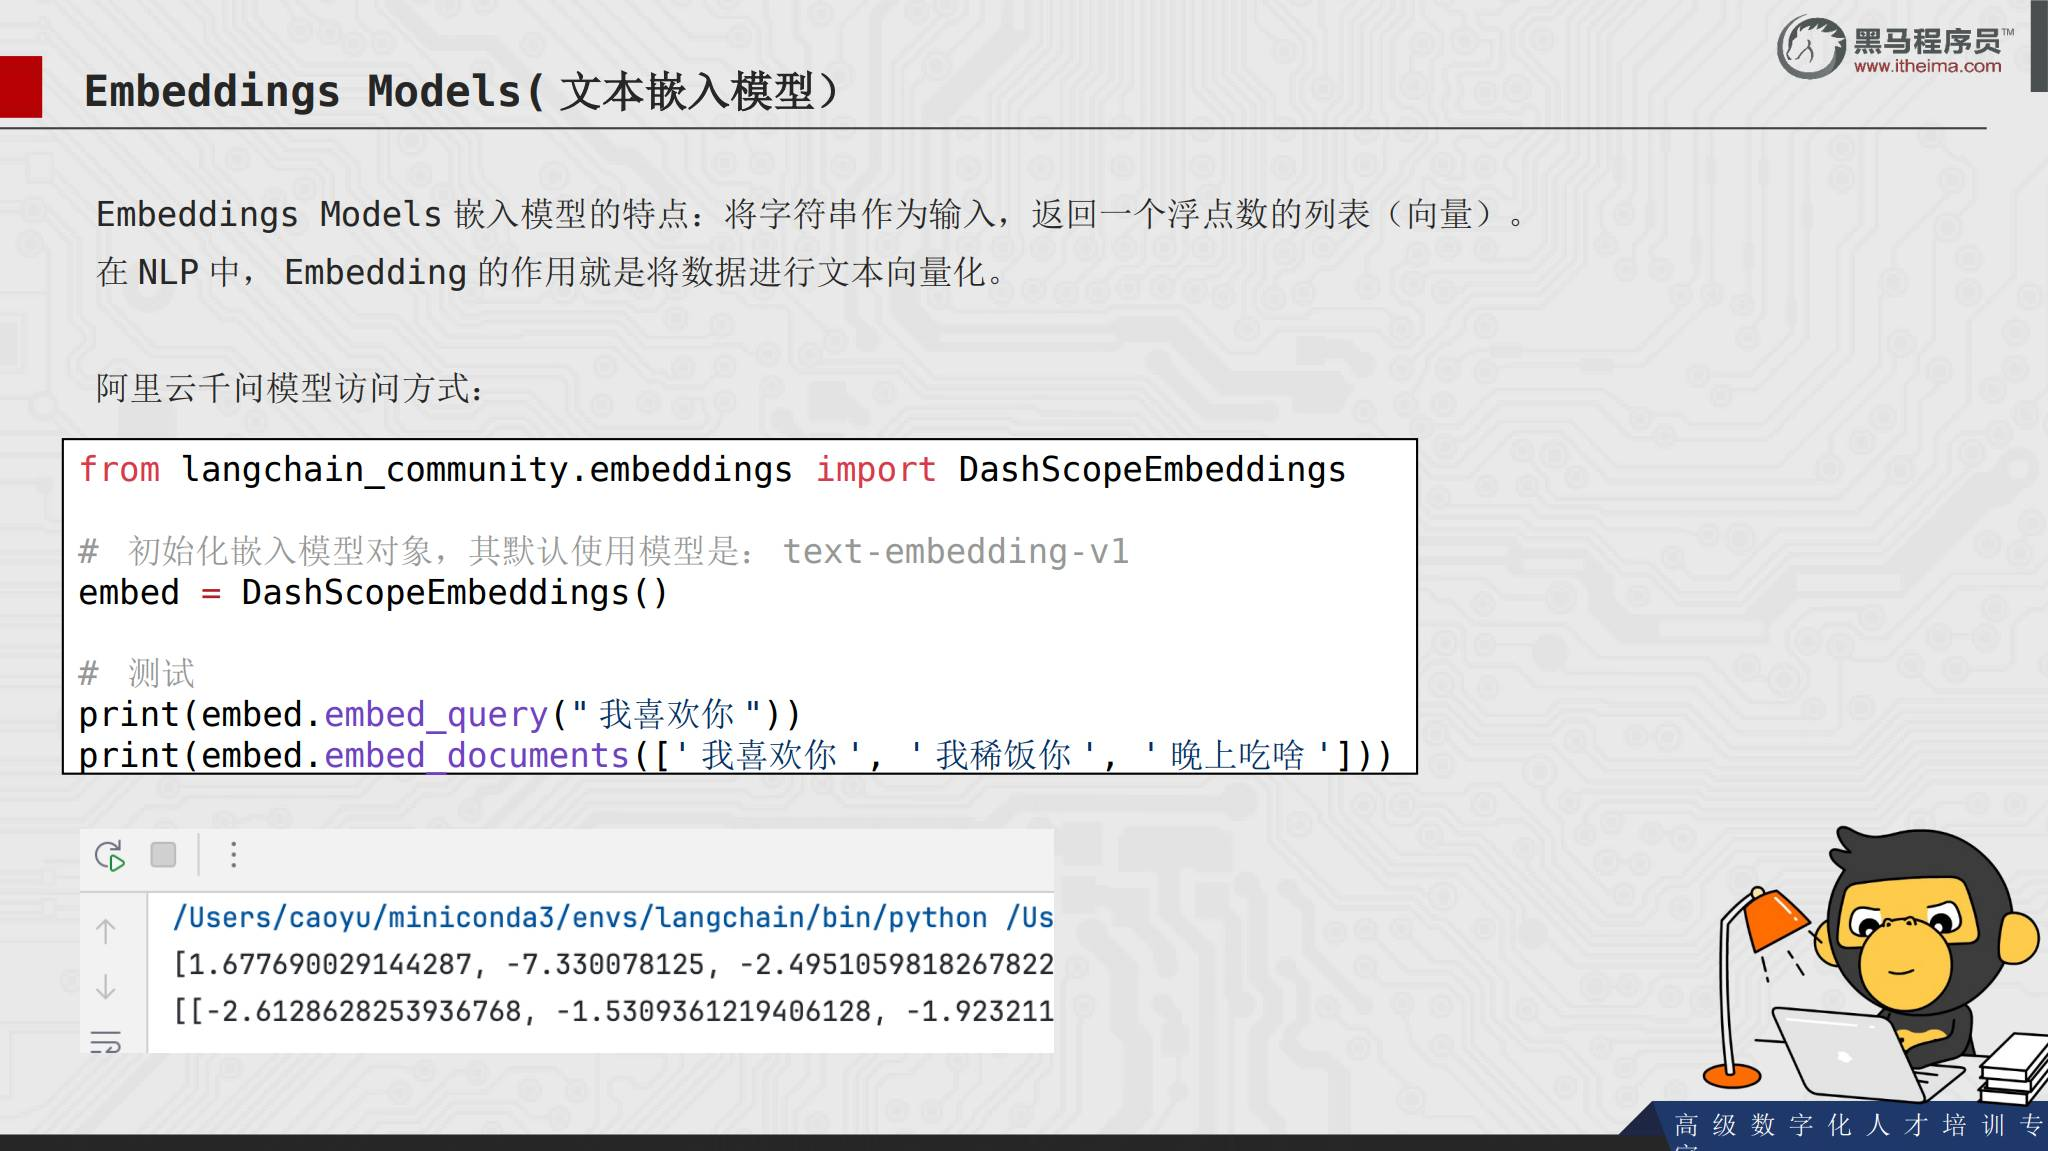


## 18. 模型组件小结

目前掌握的 LangChain 模型接口可以这样记：

| 方式 | 云端通义千问 | Ollama 本地模型 | 常用方法 |
| --- | --- | --- | --- |
| LLM | `Tongyi` | `OllamaLLM` | `invoke`、`stream` |
| Chat Model | `ChatTongyi` | `ChatOllama` | `invoke`、`stream` |
| Embeddings | `DashScopeEmbeddings` | `OllamaEmbeddings` | `embed_query`、`embed_documents` |


## 19. PromptTemplate：通用提示词模板

`PromptTemplate` 可以把提示词标准化，并在运行时注入变量：

```python
from langchain_core.prompts import PromptTemplate

prompt_template = PromptTemplate.from_template(
    "我的邻居姓 {lastname}，刚生了 {gender}，请帮忙起名字，简略回答。"
)
prompt_text = prompt_template.format(lastname="张", gender="女儿")
```

也可以和模型组成链：

```python
chain = prompt_template | model
result = chain.invoke({"lastname": "曹", "gender": "女儿"})
```

模板类便于在大型工程中统一管理提示词，并且可以直接接入 Runnable 链。

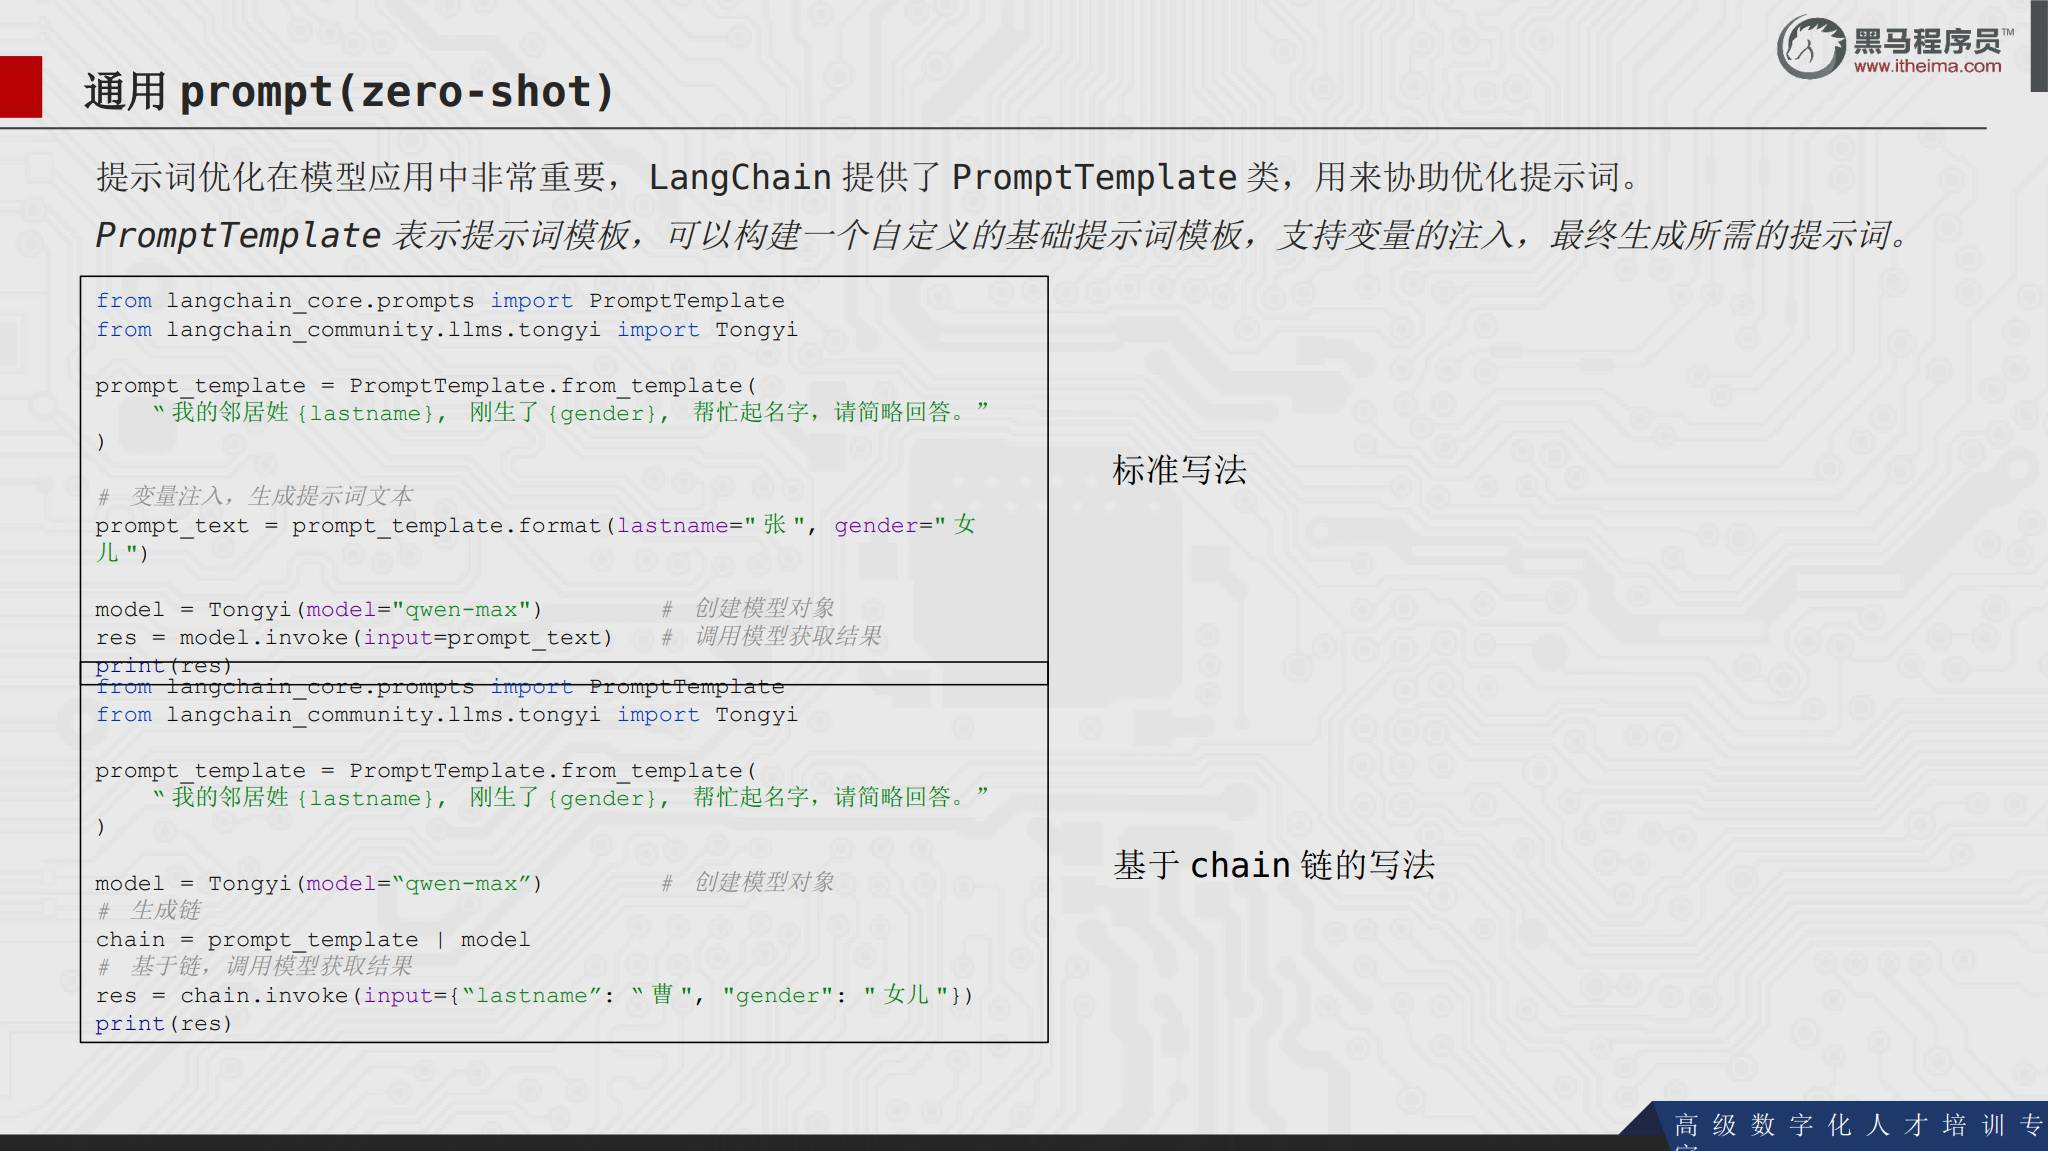


## 20. FewShotPromptTemplate

`FewShotPromptTemplate` 用模板拼接少量示例，再把当前输入放在示例之后。它的五个核心参数是：

| 参数 | 作用 |
| --- | --- |
| `examples` | 示例数据，通常是字典列表 |
| `example_prompt` | 单个示例的格式模板 |
| `prefix` | 示例数据前的任务说明 |
| `suffix` | 示例数据后的当前任务 |
| `input_variables` | 需要注入的变量名列表 |

```python
from langchain_core.prompts import FewShotPromptTemplate, PromptTemplate

example_prompt = PromptTemplate.from_template("单词：{word}，反义词：{antonym}")
examples = [
    {"word": "大", "antonym": "小"},
    {"word": "上", "antonym": "下"},
]
few_shot_prompt = FewShotPromptTemplate(
    example_prompt=example_prompt,
    examples=examples,
    prefix="给出单词的反义词，参考以下示例：",
    suffix="基于示例告诉我：{input_word} 的反义词是？",
    input_variables=["input_word"],
)
prompt_text = few_shot_prompt.invoke({"input_word": "左"}).to_string()
```

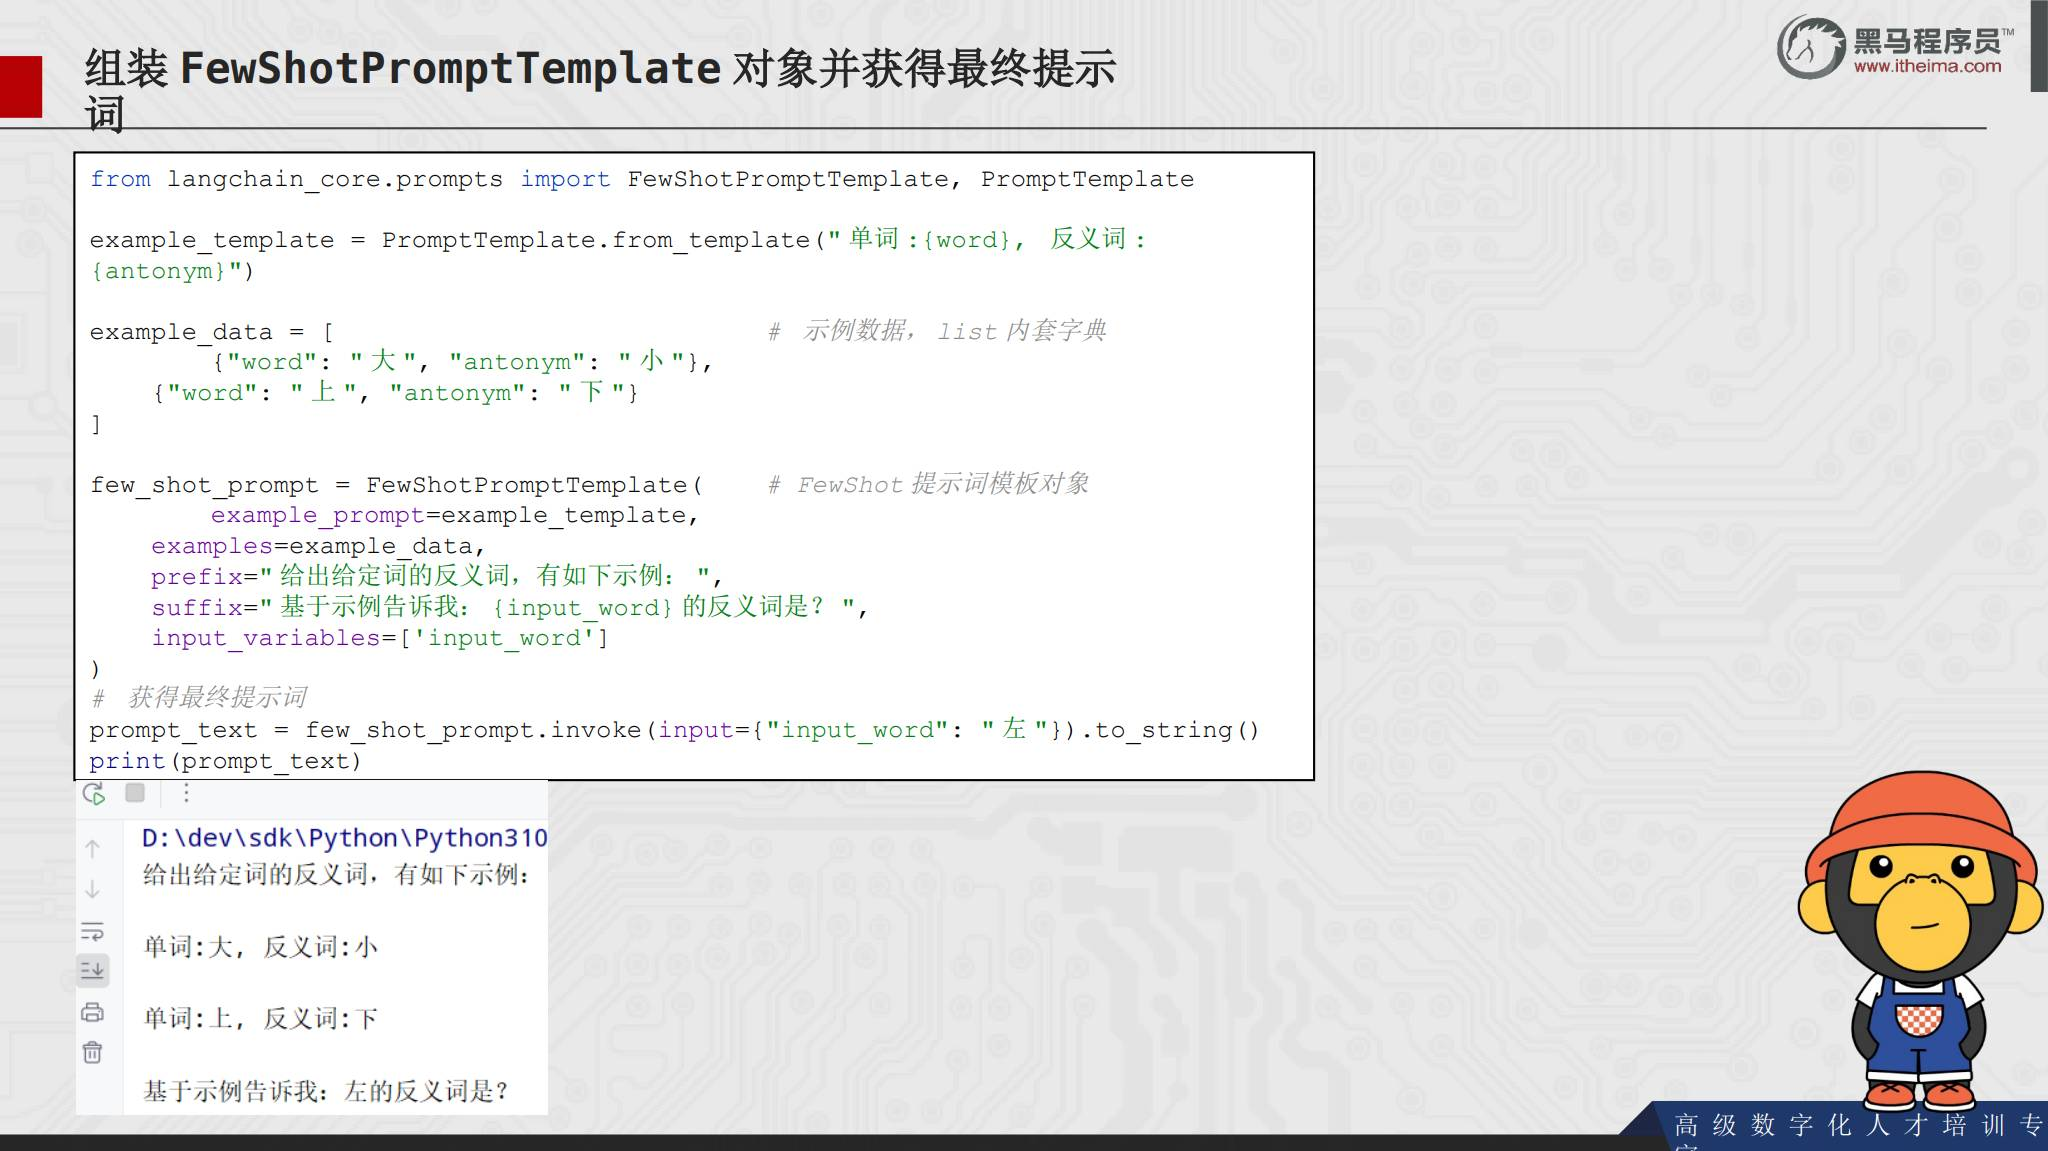


## 21. `format` 与 `invoke`

PromptTemplate、FewShotPromptTemplate 和 ChatPromptTemplate 都提供 `format` 与 `invoke`。

| 方法 | 作用 | 返回或特点 |
| --- | --- | --- |
| `format` | 直接替换变量，生成提示词 | 更接近普通字符串格式化 |
| `invoke` | 按 Runnable 接口执行模板 | 返回 PromptValue，可继续接入链 |

`MessagesPlaceholder` 等结构化占位符需要通过 `invoke` 动态注入，不能简单用 `format` 完成。


## 22. ChatPromptTemplate 与历史消息

`ChatPromptTemplate.from_messages()` 可以把多轮对话组织成聊天模板。历史消息不是静态内容，需要用 `MessagesPlaceholder` 在运行时注入：

```python
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

chat_template = ChatPromptTemplate.from_messages([
    ("system", "你是一个贴心的助手。"),
    MessagesPlaceholder("history"),
    ("human", "{question}"),
])

prompt_value = chat_template.invoke({
    "history": [("human", "你好"), ("ai", "你好，有什么可以帮你？")],
    "question": "继续回答我的问题",
})
```

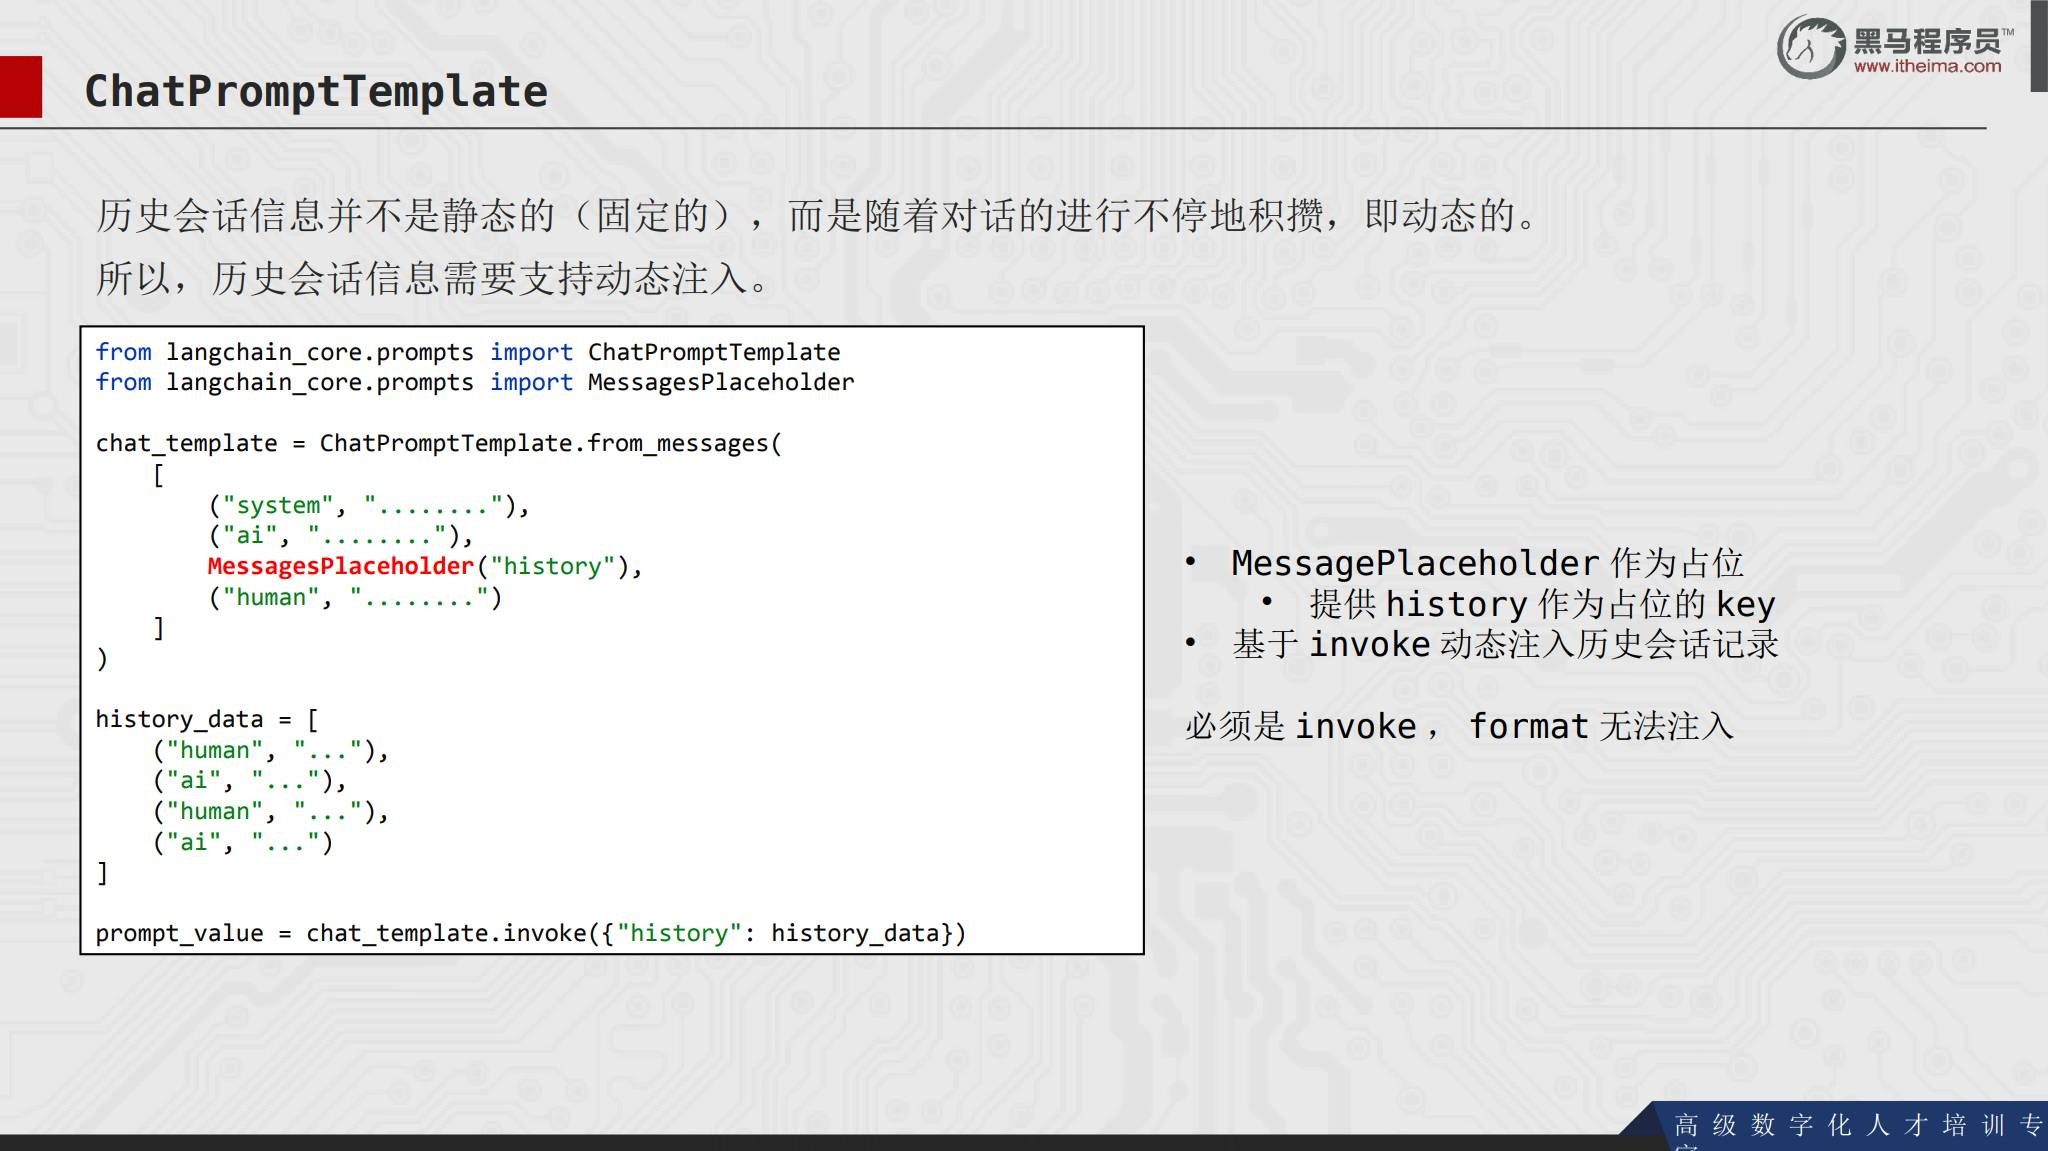


## 23. 使用聊天模板构建链

聊天模板、聊天模型和输出解析器可以组成一条链：

```python
from langchain_core.output_parsers import StrOutputParser

chain = chat_template | model | StrOutputParser()
for chunk in chain.stream({"history": [], "question": "粗的反义词是什么？"}):
    print(chunk, end="", flush=True)
```

有历史消息时，把 `HumanMessage`、`AIMessage` 列表放进 `history`；没有历史时传入空列表。`StrOutputParser` 负责提取文本内容，去掉模型消息对象的其他元数据。


## 24. LangChain 链的基础

链的核心是：**一个组件的输出自动作为下一个组件的输入**。使用 `|` 把 Runnable 组件连接起来：

```python
chain = prompt | model
```

前提是参与连接的对象实现 Runnable 接口，或者是可调用函数、映射等支持的类型。组成的链通常是 `RunnableSequence`，也支持 `invoke` 和 `stream`。

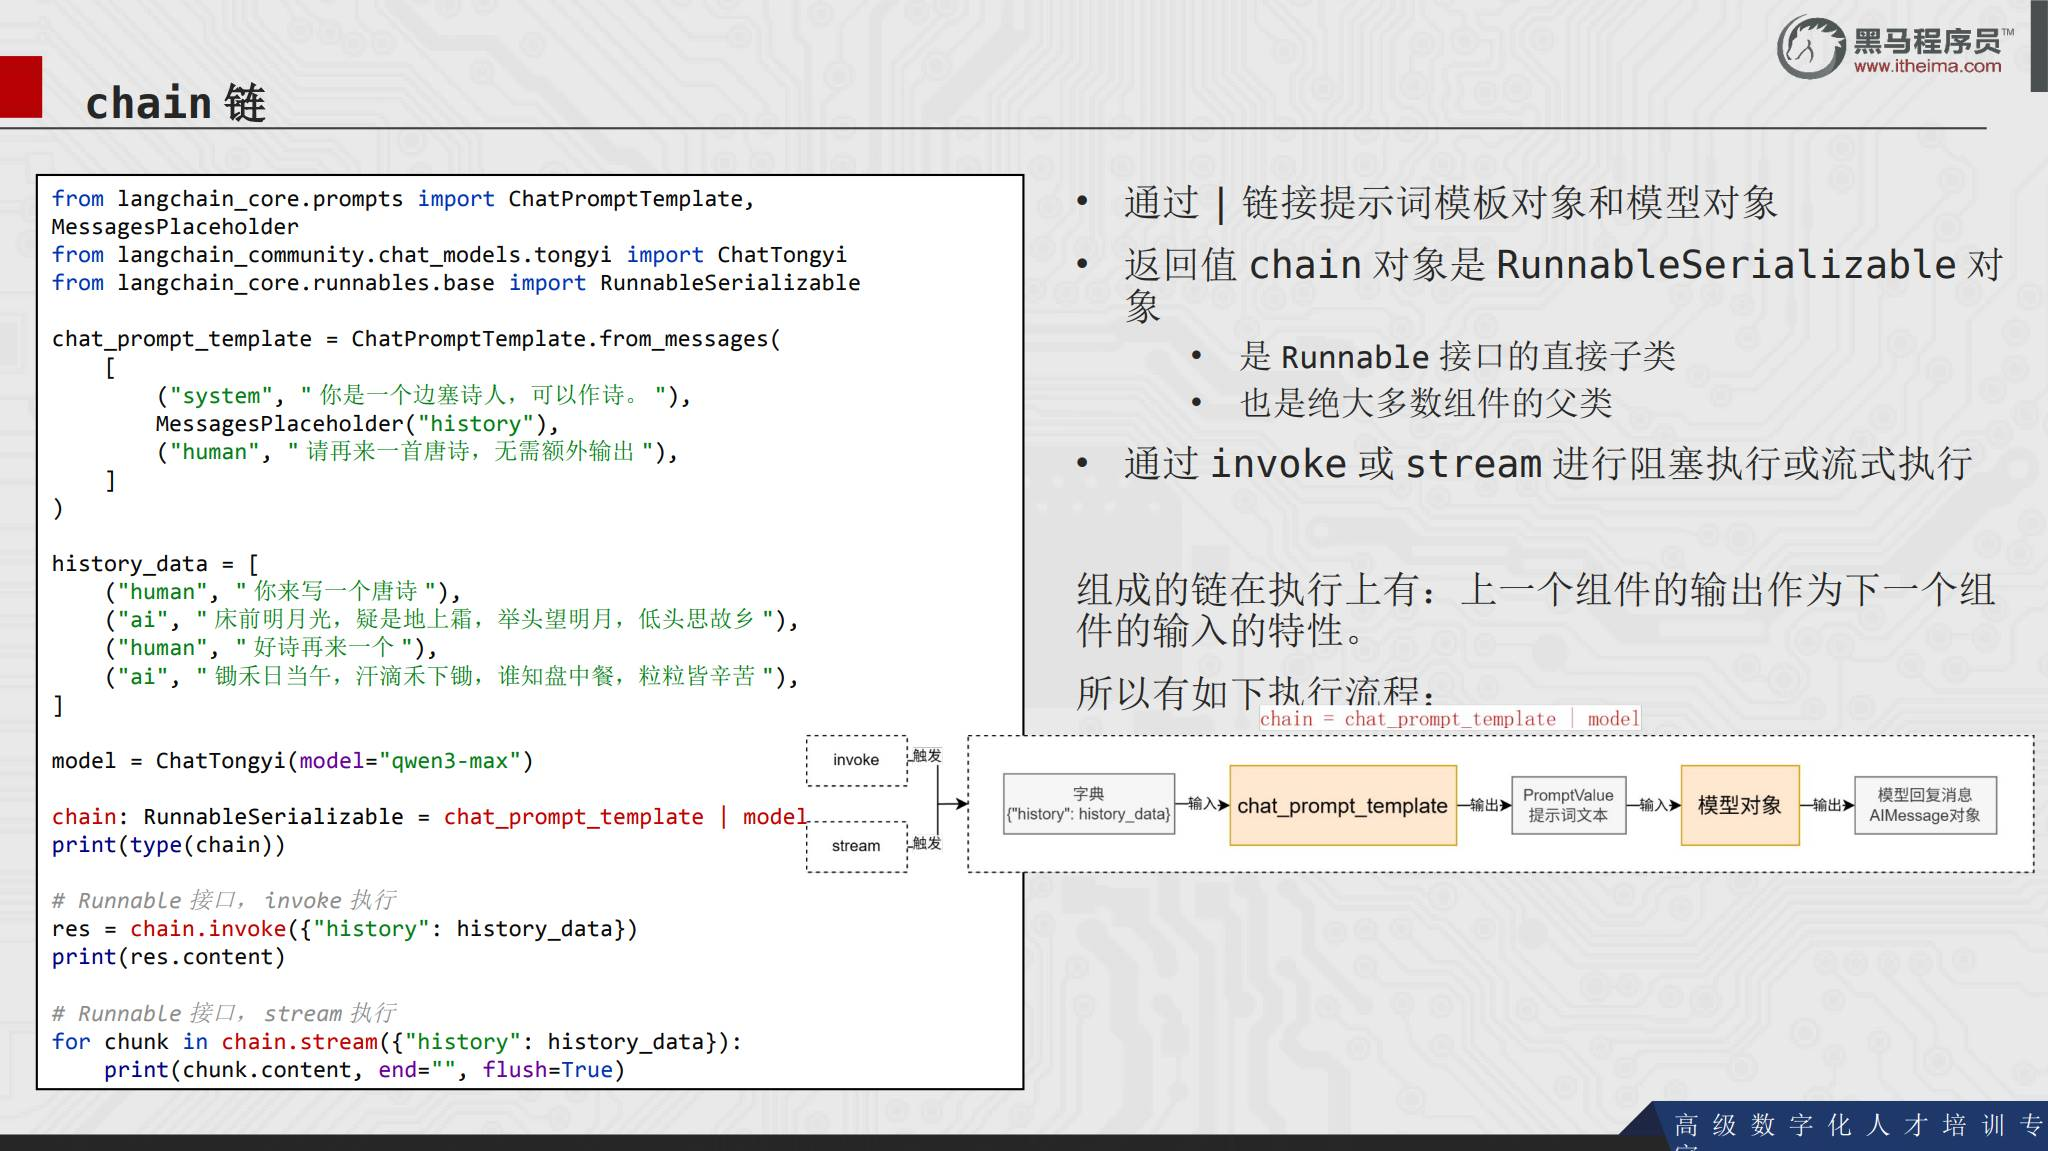


## 25. `|` 运算符重载

Python 中 `a | b` 本质上会调用 `a.__or__(b)`。LangChain 的 Runnable 基类重写了这个方法，使得组件可以像管道一样串联。

课件用 `Test` 和 `MySequence` 演示：

```python
class Test:
    def __init__(self, name):
        self.name = name

    def __or__(self, other):
        return MySequence(self, other)


class MySequence:
    def __init__(self, *args):
        self.sequence = list(args)

    def __or__(self, other):
        self.sequence.append(other)
        return self

    def run(self):
        for item in self.sequence:
            print(item)
```

这个例子只用于理解语法。实际 LangChain 链由 Runnable 组件负责数据传递。

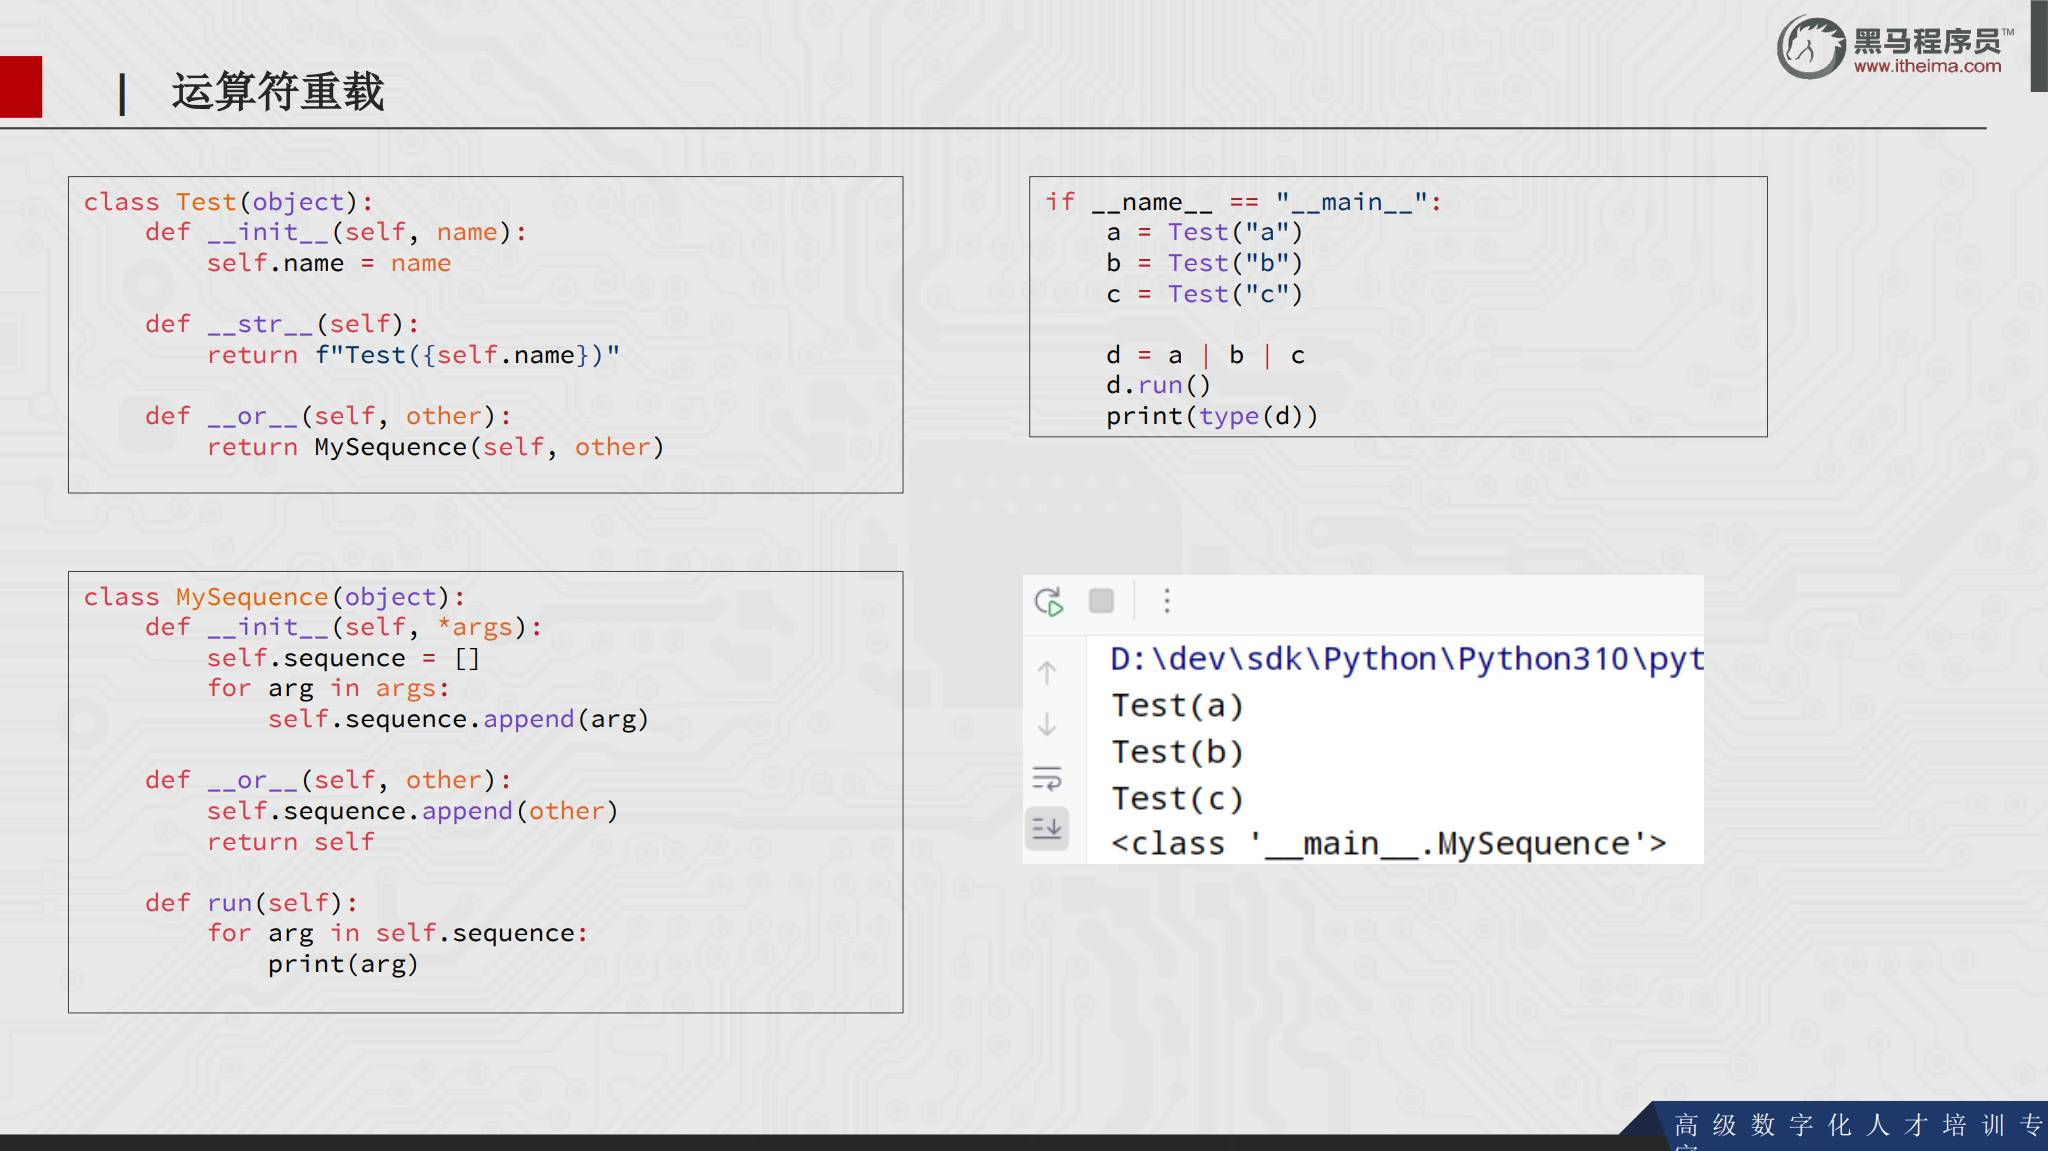


## 26. StrOutputParser

聊天模型输出通常是 `AIMessage`，而下一个模型可能需要字符串、PromptValue 或消息序列。如果直接写 `prompt | model | model`，类型可能不兼容。

`StrOutputParser` 是 LangChain 内置的简单字符串解析器，可以把 `AIMessage` 转换为字符串，也实现了 Runnable 接口，可以放入链中：

```python
from langchain_core.output_parsers import StrOutputParser

chain = prompt | model | StrOutputParser() | model
```

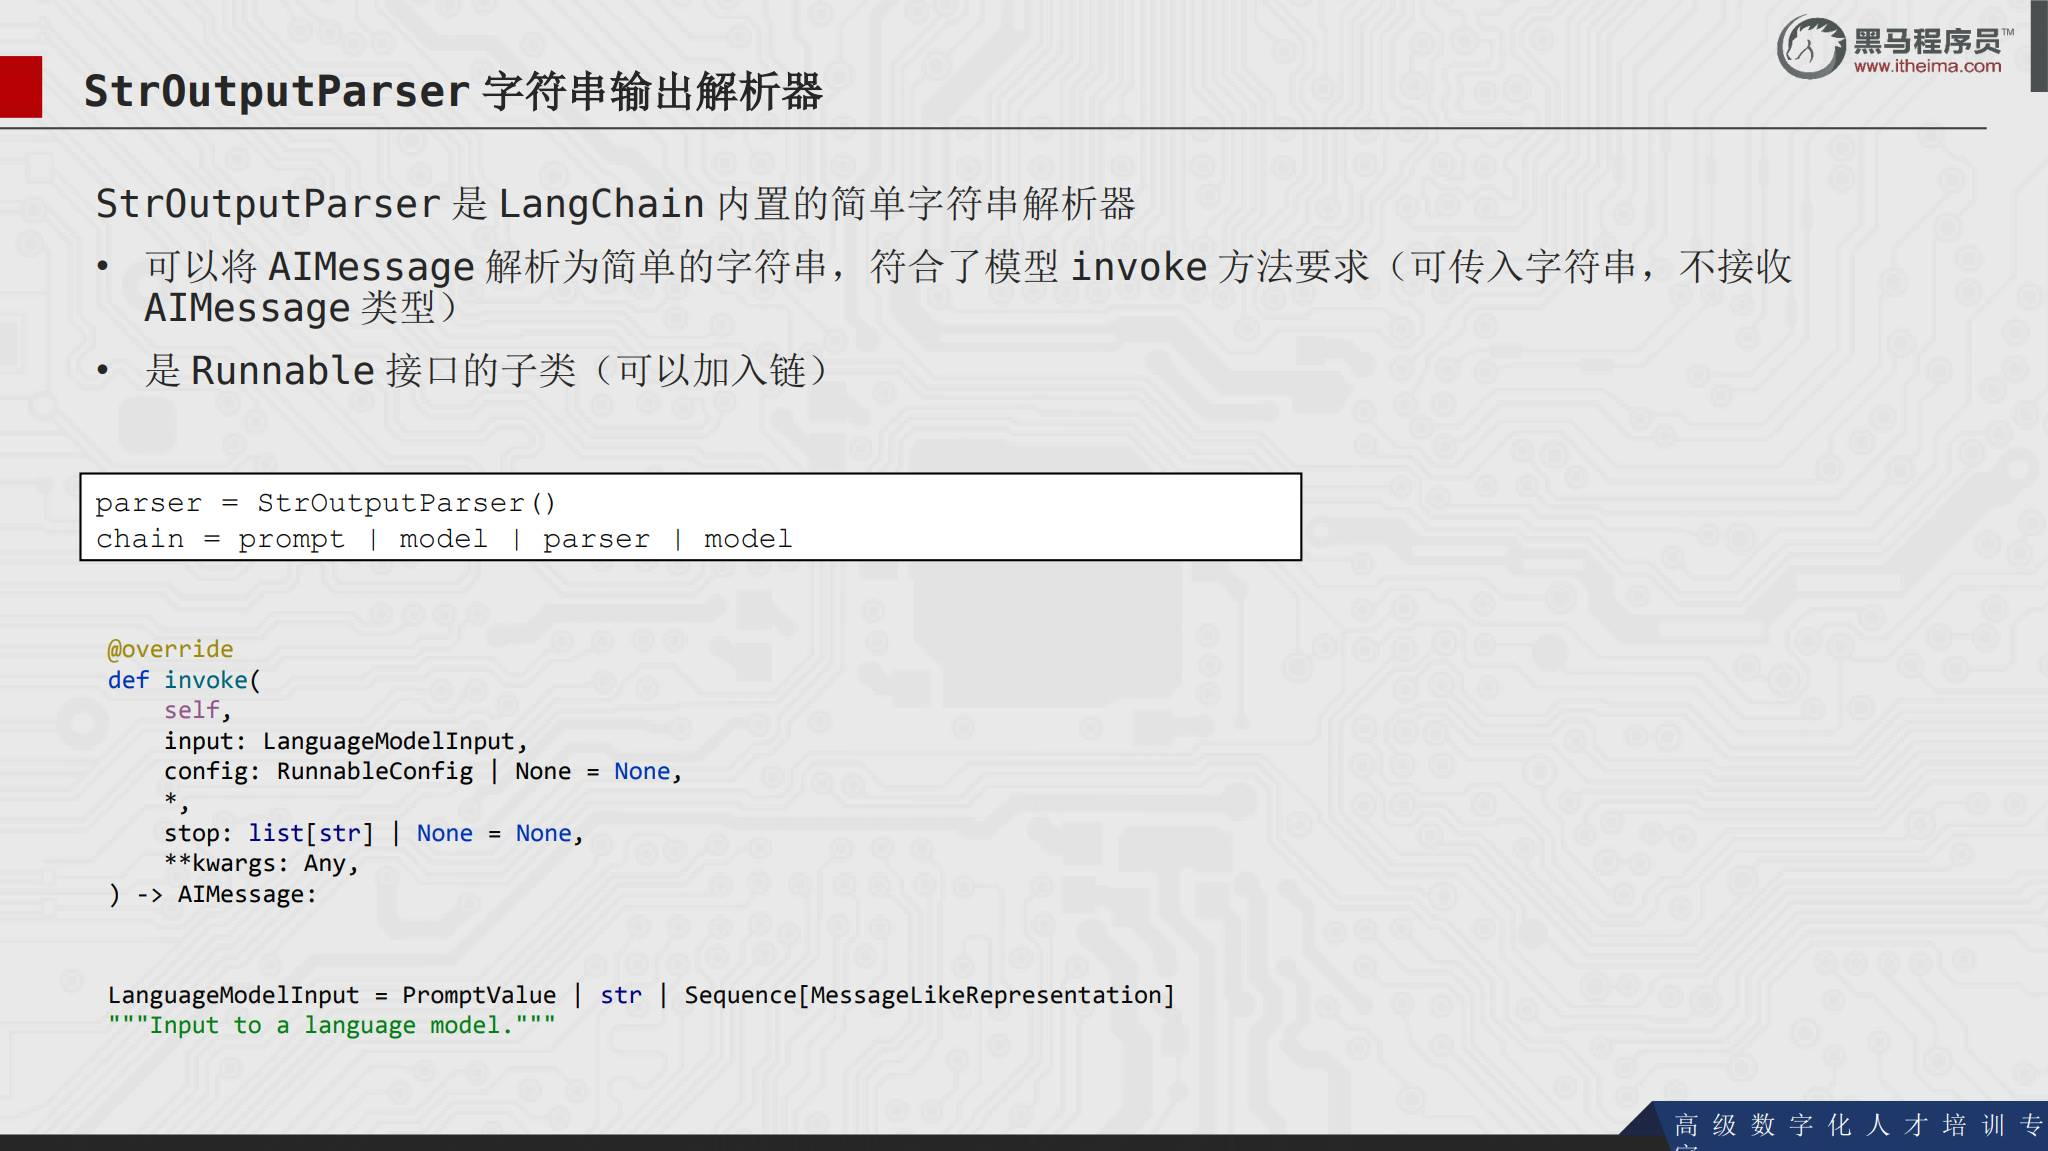


## 27. JsonOutputParser 与多模型链

多模型链中，前一个模型的输出通常应该先经过处理，再填入第二个提示词模板。需要把 `AIMessage` 转成字典时，可以使用 `JsonOutputParser`：

```python
from langchain_core.output_parsers import JsonOutputParser, StrOutputParser

first_prompt = PromptTemplate.from_template(
    "我邻居姓：{lastname}，刚生了{gender}，请严格以 JSON 返回，key 为 name。"
)
second_prompt = PromptTemplate.from_template("姓名 {name}，请帮我解析含义。")

chain = first_prompt | model | JsonOutputParser() | second_prompt | model | StrOutputParser()
result = chain.invoke({"lastname": "张", "gender": "女儿"})
```

要点是对齐前后组件的数据类型：提示词模板接收字典，模型输出消息，JSON 解析器输出字典，最终字符串解析器输出文本。

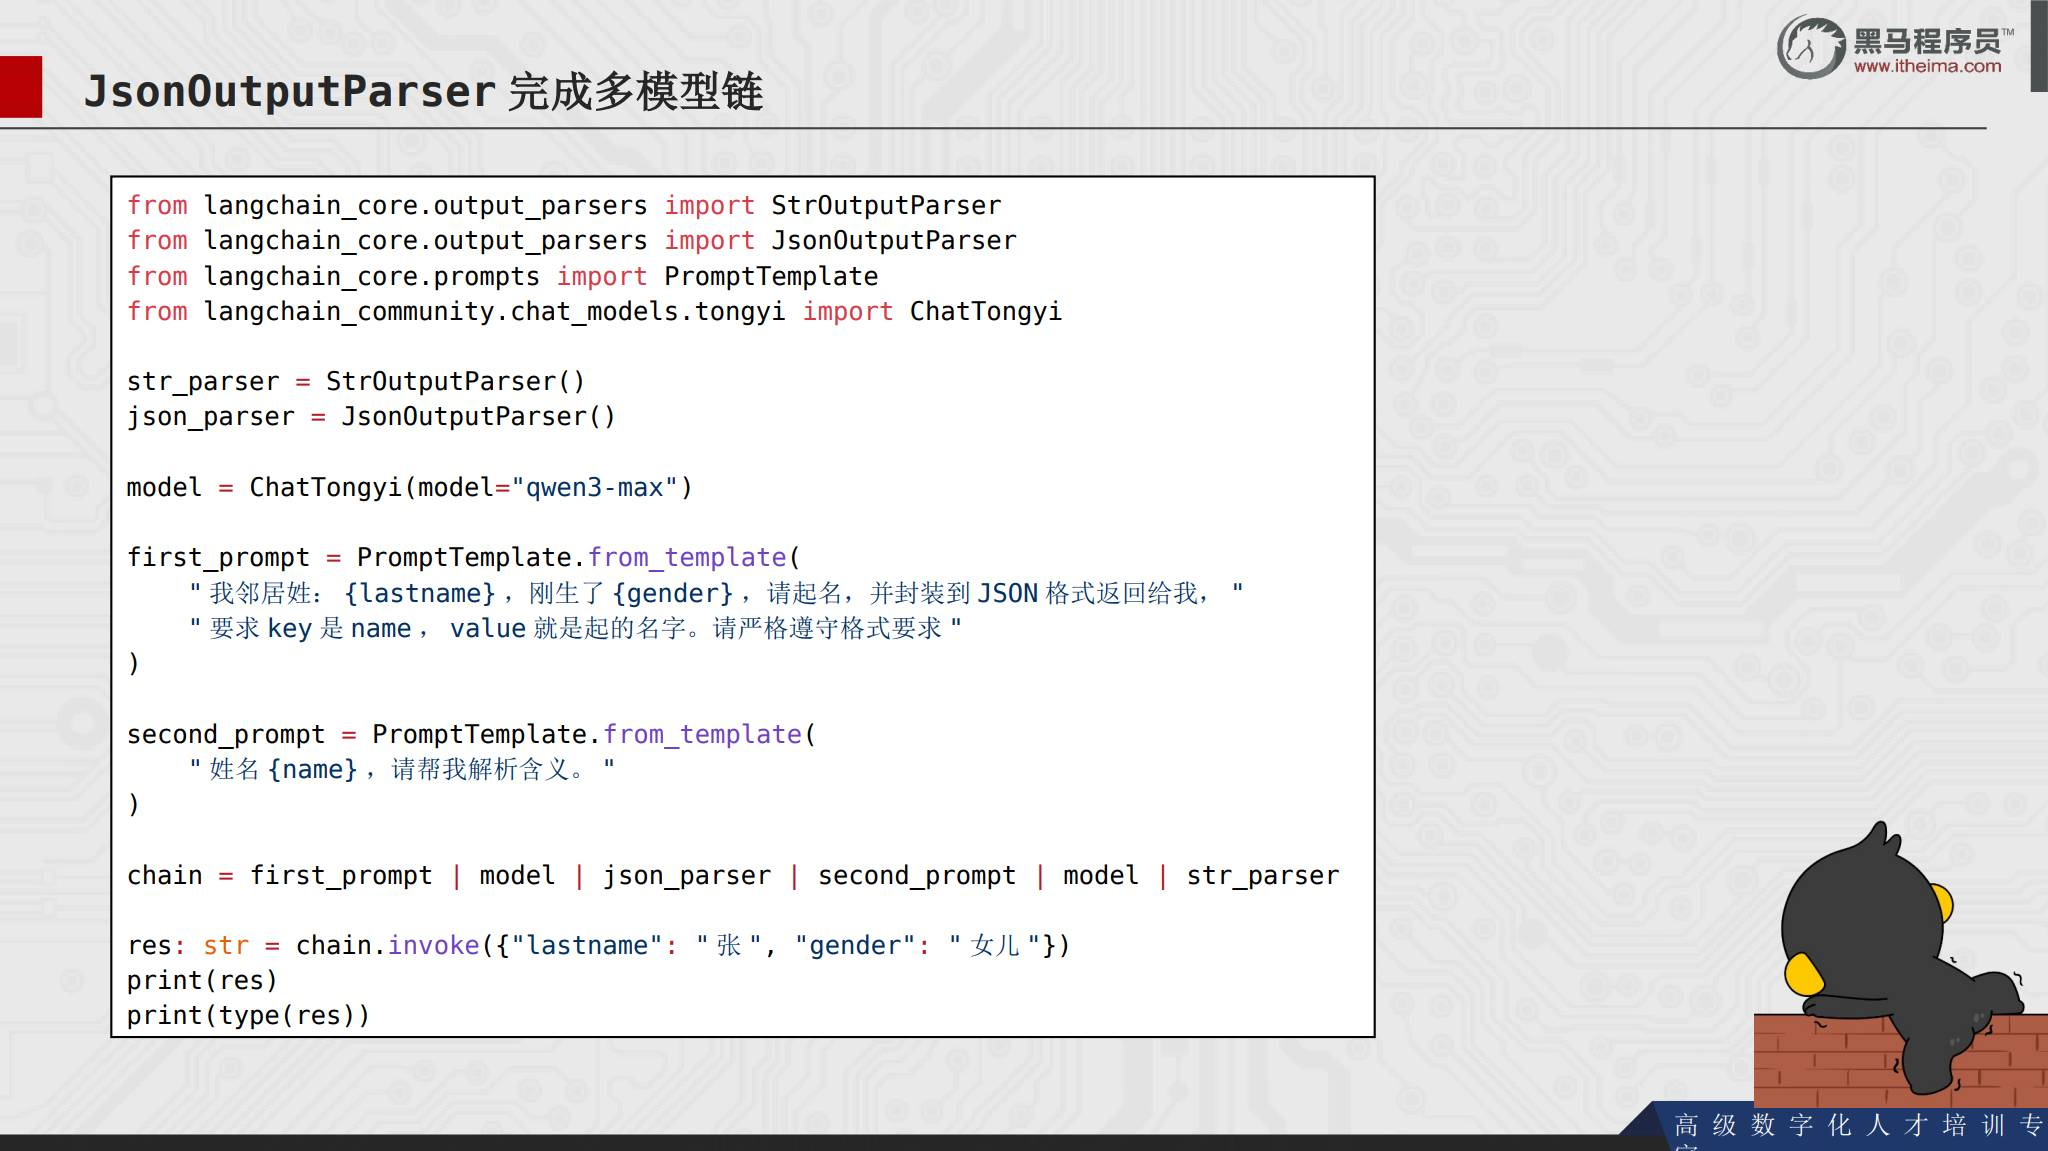


## 28. RunnableLambda 与自定义函数

除了固定的解析器，也可以把自己的数据转换函数加入链。`RunnableLambda` 会把普通函数包装成 Runnable：

```python
from langchain_core.runnables import RunnableLambda

to_name = RunnableLambda(lambda ai_msg: {"name": ai_msg.content})
chain = first_prompt | model | to_name | second_prompt | model | StrOutputParser()
```

由于 Runnable 的 `__or__` 也支持 Callable，普通函数可以直接入链，LangChain 会自动转换为 RunnableLambda：

```python
chain = first_prompt | model | (lambda ai_msg: {"name": ai_msg.content}) | second_prompt | model
```

自定义函数应保持清晰的输入输出约定，避免破坏后续组件需要的数据结构。

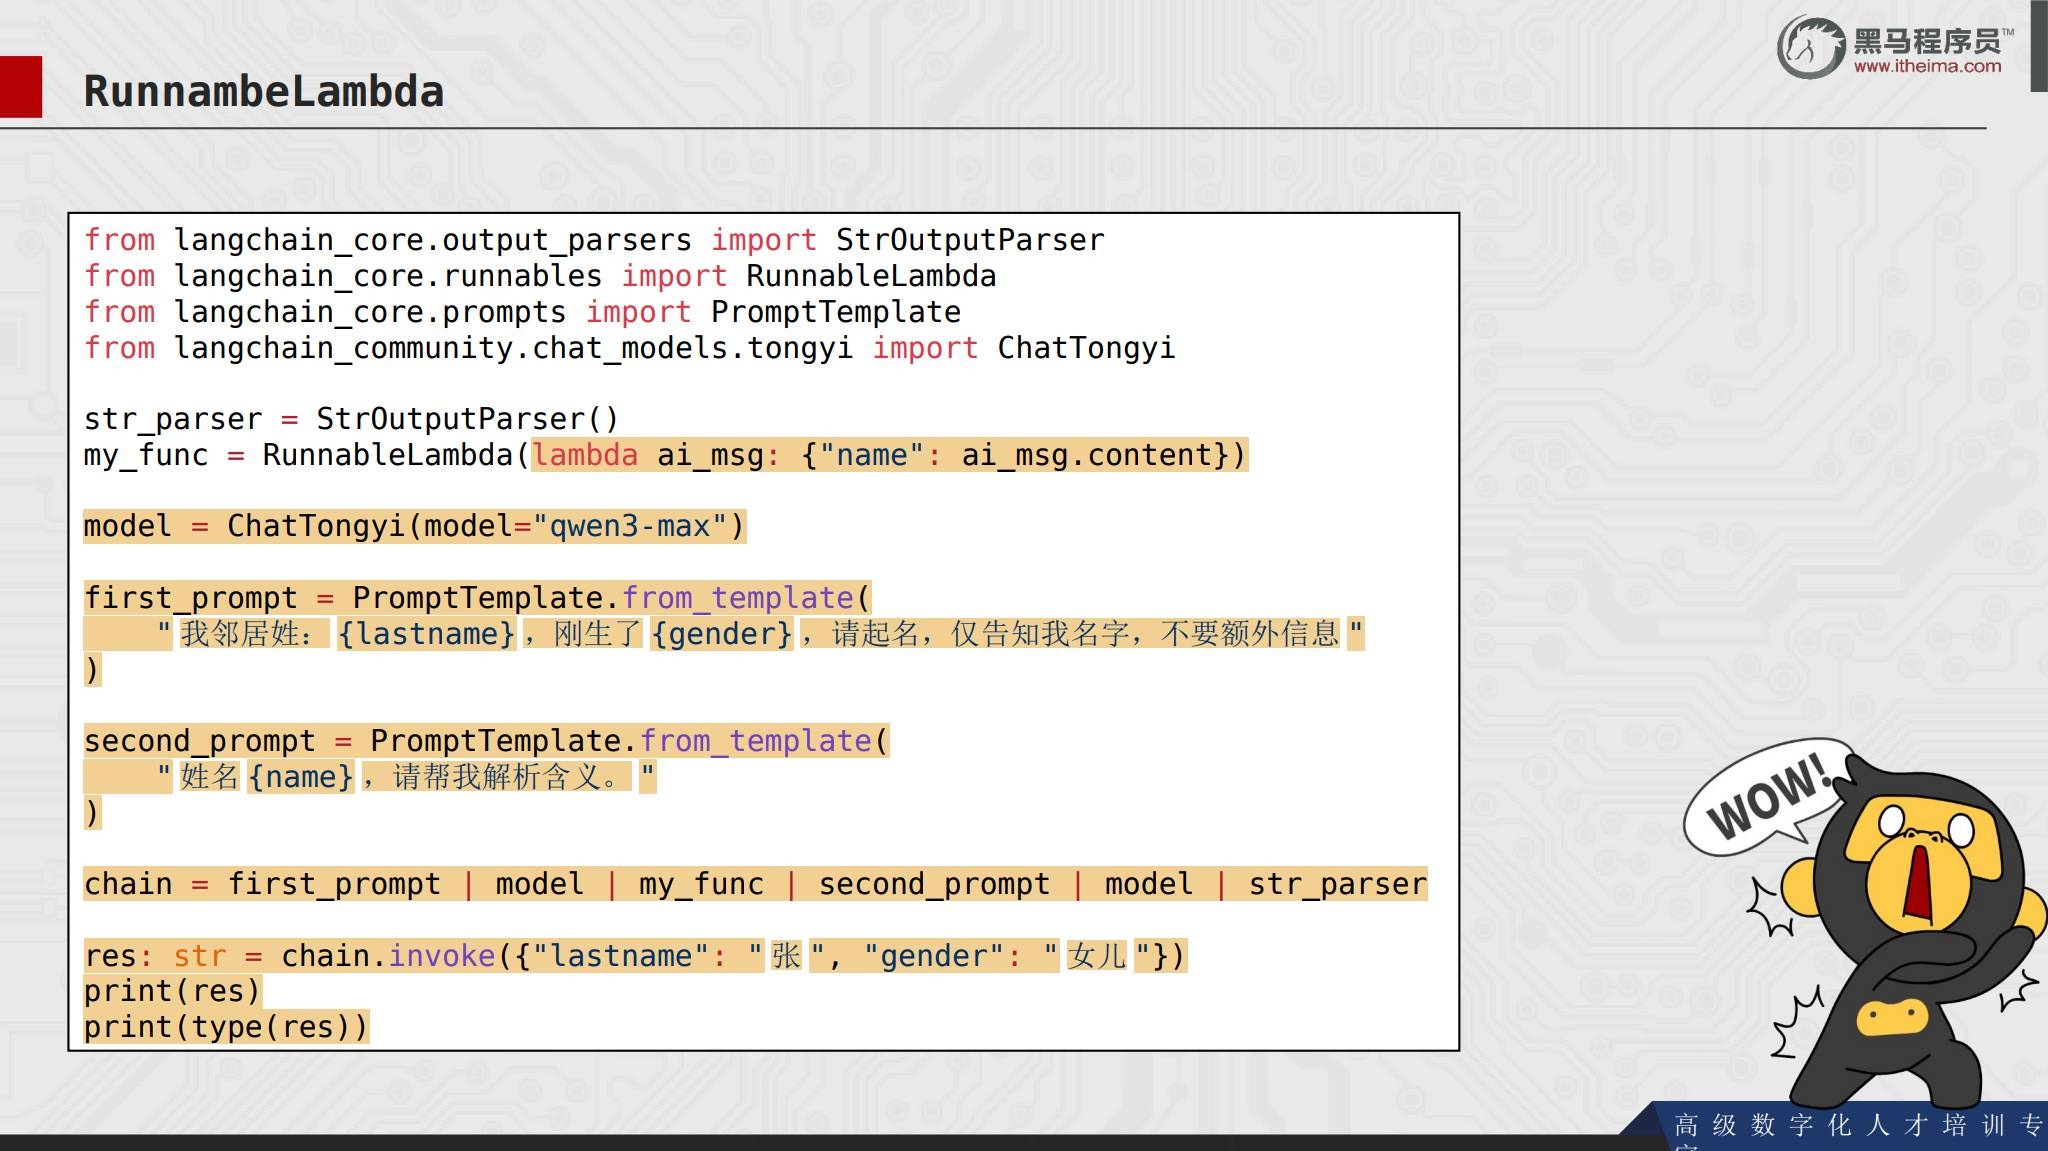


## 29. RunnableWithMessageHistory 与临时记忆

LangChain 可以在已有链上附加会话历史：

- `RunnableWithMessageHistory` 创建带历史功能的新 Runnable。
- `InMemoryChatMessageHistory` 把消息保存在内存中，适合临时会话。
- 用 `session_id` 区分不同会话。

```python
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory

history_store = {}

def get_history(session_id):
    if session_id not in history_store:
        history_store[session_id] = InMemoryChatMessageHistory()
    return history_store[session_id]

conversation_chain = RunnableWithMessageHistory(
    base_chain,
    get_history,
    input_messages_key="input",
    history_messages_key="chat_history",
)

config = {"configurable": {"session_id": "user_001"}}
conversation_chain.invoke({"input": "小明有一只猫"}, config=config)
```

程序退出后，内存中的历史会丢失。

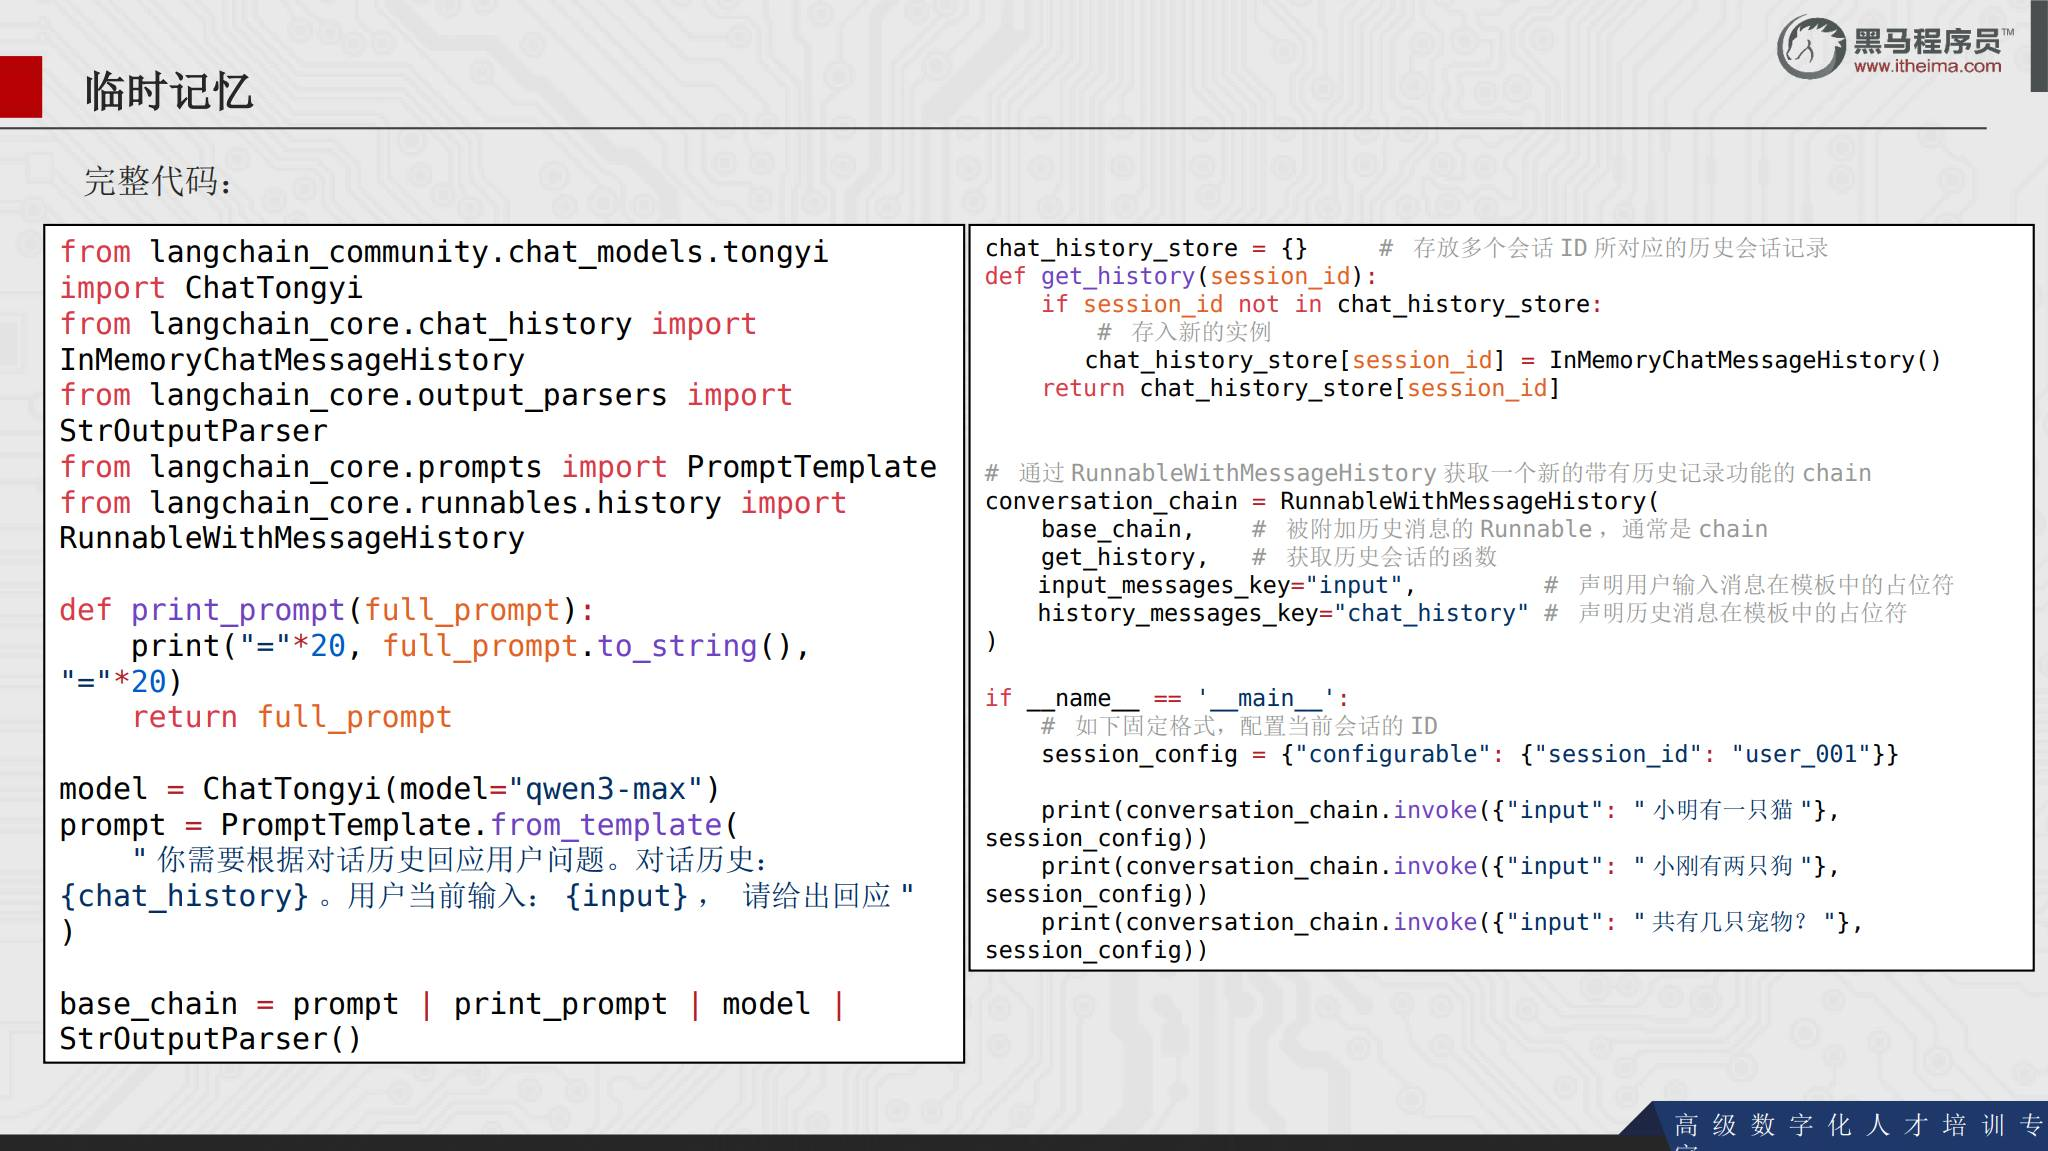


## 30. 文件持久化的长期记忆

如果需要程序重启后继续保留消息，可以实现 `FileChatMessageHistory`，把每个会话写入 JSON 文件。课件给出的核心设计是：

- 用 `session_id` 作为文件名，不同会话写入不同文件。
- 继承 `BaseChatMessageHistory`。
- 实现 `add_messages`、`messages` 和 `clear` 三个方法。
- 用 `message_to_dict` 序列化消息，用 `messages_from_dict` 恢复消息。

长期记忆的关键不是把所有消息永久堆积，而是选择稳定的存储位置、会话标识和清理策略。

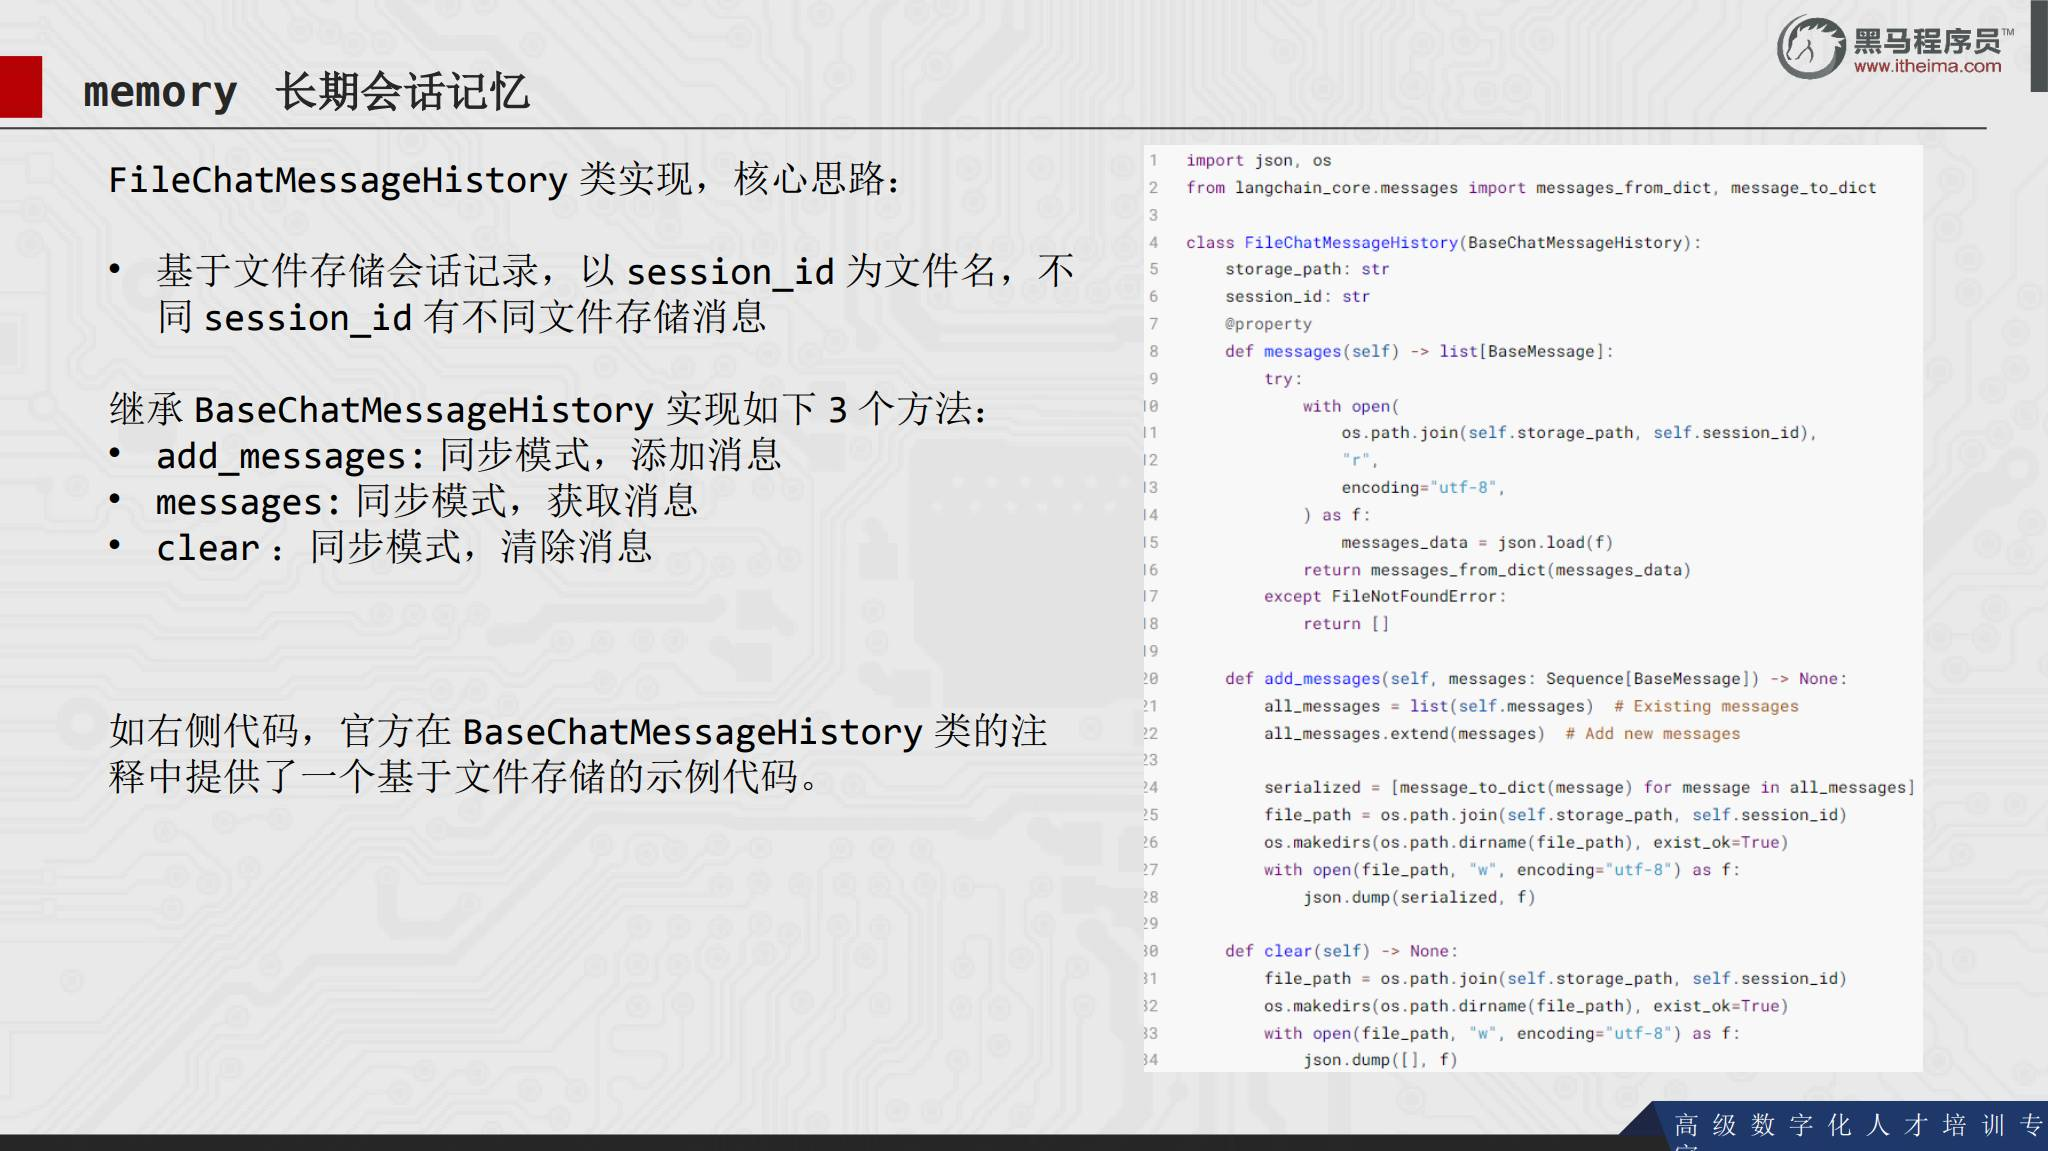


## 31. 文档加载器的统一接口

文档加载器把 CSV、PDF、JSON、TXT 等不同来源的数据转换成 LangChain 统一的 `Document` 对象。

`Document` 主要包含：

- `page_content`：文档正文。
- `metadata`：来源、页码等元数据字典。

```python
from langchain_core.documents import Document

document = Document(
    page_content="Hello, world!",
    metadata={"source": "https://example.com"},
)
```

加载器统一实现 `load()` 和 `lazy_load()`：前者一次性返回全部文档，后者返回生成器，适合大型数据集。

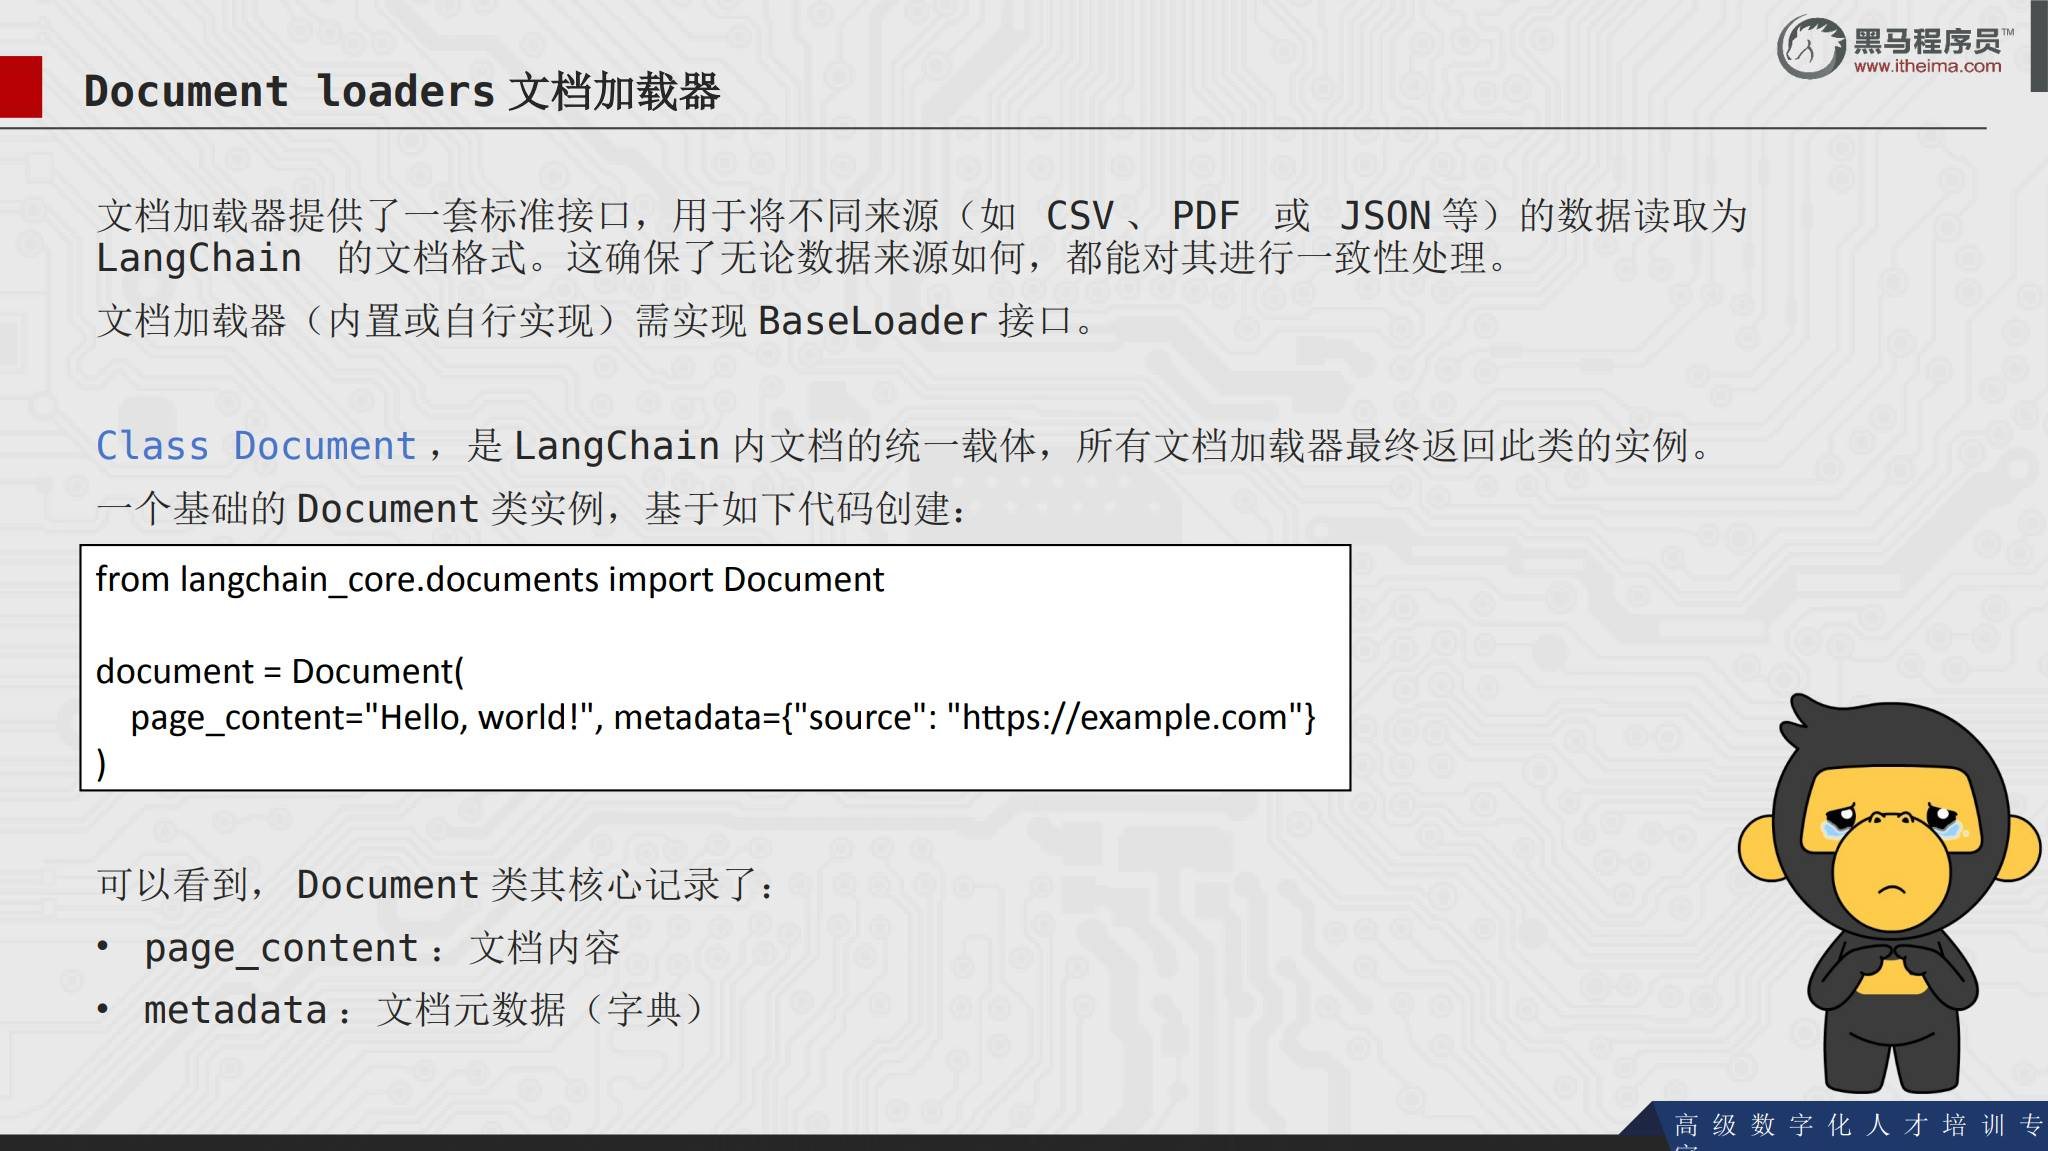


## 32. CSVLoader

CSVLoader 用于读取 CSV 文件：

```python
from langchain_community.document_loaders.csv_loader import CSVLoader

loader = CSVLoader(file_path="./data.csv")
documents = loader.load()
```

如果文件没有表头或分隔符特殊，可以通过 `csv_args` 配置 `delimiter`、`quotechar` 和 `fieldnames`。有表头时不要随意提供 `fieldnames`，否则可能把首行处理方式改变。

对于大文件，可以使用：

```python
for document in loader.lazy_load():
    print(document)
```


## 33. JSONLoader 与 jq 查询语法

JSONLoader 依赖 `jq`，需要先安装：

```bash
pip install jq
```

常见 `jq_schema`：

| 表达式 | 含义 |
| --- | --- |
| `.` | 整个 JSON 根对象 |
| `[]` | 数组 |
| `.name` | 根对象的 `name` |
| `.hobby[1]` | `hobby` 数组的第二个元素 |
| `.other.addr` | 嵌套对象中的 `addr` |
| `.[].name` | 数组中每个对象的 `name` |

```python
from langchain_community.document_loaders import JSONLoader

loader = JSONLoader(
    file_path="./data.json",
    jq_schema=".",
    text_content=False,
    json_lines=True,
)
documents = loader.load()
```

`json_lines=True` 用于每行都是独立 JSON 对象的 JSON Lines 文件。


## 34. PyPDFLoader 与 TextLoader

读取 PDF 需要安装 `pypdf`：

```bash
pip install pypdf
```

```python
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader(file_path="./document.pdf", mode="page")
documents = loader.load()
```

`mode="page"` 按页面生成不同 Document，`mode="single"` 合并成一个 Document。

TextLoader 用于读取 TXT：

```python
from langchain_community.document_loaders import TextLoader

loader = TextLoader("./document.txt", encoding="utf-8")
documents = loader.load()
```

TextLoader 默认把全部内容放进一个 Document；文档较大时，需要继续使用文本分割器。


## 35. RecursiveCharacterTextSplitter

`RecursiveCharacterTextSplitter` 是 LangChain 推荐的默认字符分割器，优先按自然段落和换行切分，在上下文完整性与片段大小之间取得平衡。

```python
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    separators=["\n\n", "\n", "。", "！", "？", ".", "!", "?", " ", ""],
    length_function=len,
)
split_documents = splitter.split_documents(documents)
```

- `chunk_size`：片段最大字符数。
- `chunk_overlap`：相邻片段允许重复的字符数，避免边界处丢失上下文。
- `separators`：按优先级尝试的切分符号。
- `length_function`：统计片段长度的函数。

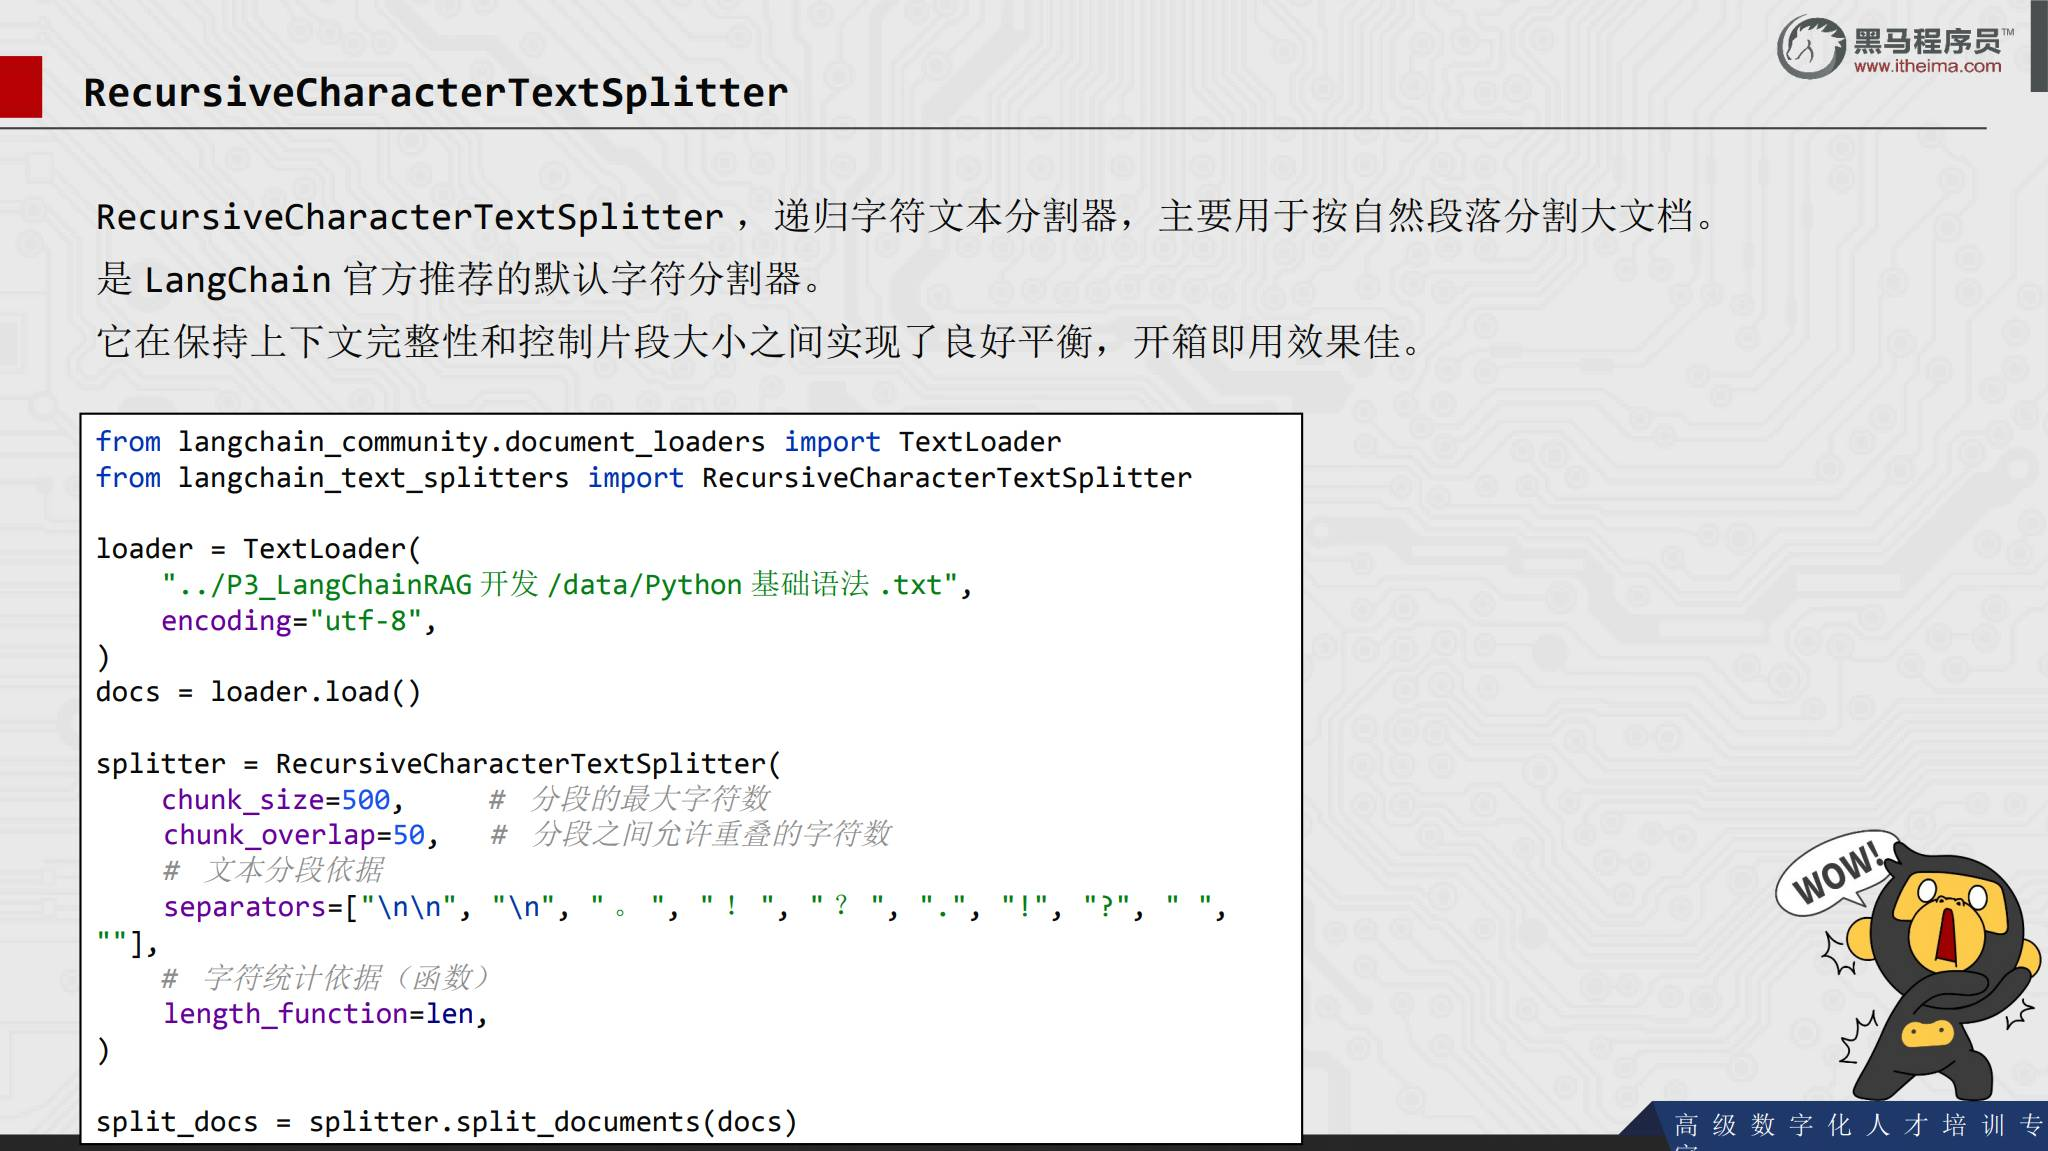


## 36. 向量存储的统一能力

向量存储负责保存嵌入向量，并执行相似度搜索。LangChain 为不同向量库提供统一接口，课程重点介绍：

- `InMemoryVectorStore`：内存向量存储，适合快速测试。
- `Chroma`：外部向量数据库，可以持久化到目录。

常用操作是：

- `add_documents`：添加文档。
- `delete`：按 ID 删除文档。
- `similarity_search`：按问题检索相似文档。

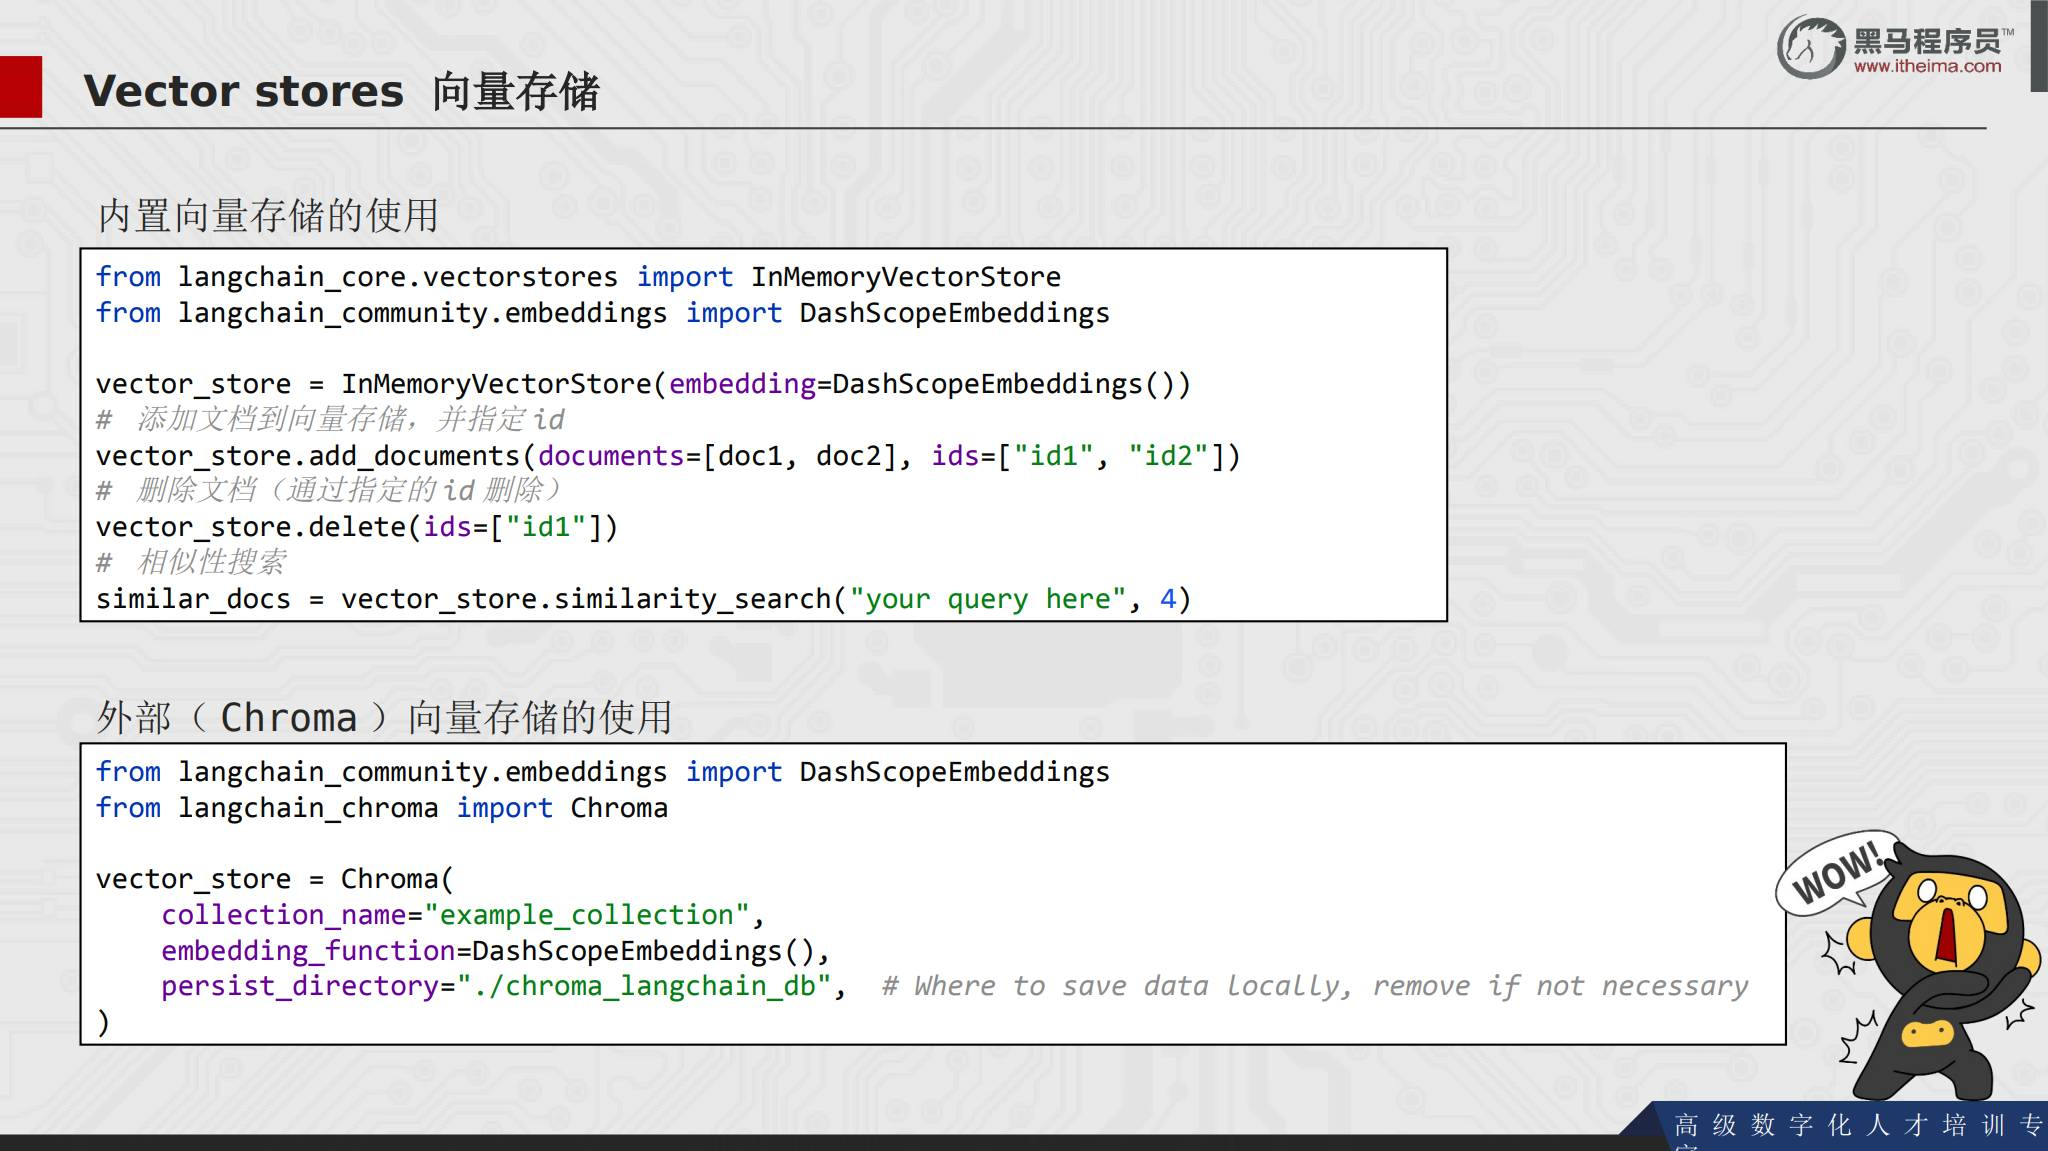


## 37. InMemoryVectorStore 与 Chroma

内存向量存储：

```python
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_community.embeddings import DashScopeEmbeddings

vector_store = InMemoryVectorStore(embedding=DashScopeEmbeddings())
vector_store.add_documents(
    documents=[doc1, doc2],
    ids=["id1", "id2"],
)
vector_store.delete(ids=["id1"])
similar_docs = vector_store.similarity_search("你的问题", k=4)
```

Chroma 持久化存储：

```python
from langchain_chroma import Chroma

vector_store = Chroma(
    collection_name="example_collection",
    embedding_function=DashScopeEmbeddings(),
    persist_directory="./chroma_langchain_db",
)
```

选择哪种存储，取决于是否需要程序重启后保留数据，以及数据规模和部署方式。


## 38. 检索结果加入提示词

RAG 查询的最小代码流程是：

1. 把资料加入向量存储。
2. 用 `similarity_search` 检索与问题相关的文档。
3. 拼接检索结果的 `page_content`，形成上下文字符串。
4. 把用户问题和上下文一起传给提示词模板和模型。

```python
vector_store.add_texts([
    "减肥就是要少吃多练。",
    "减脂期间吃东西很重要，清淡少油并配合运动。",
])

input_text = "怎么减肥？"
docs = vector_store.similarity_search(input_text, k=2)
context = "\n".join(doc.page_content for doc in docs)
result = chain.invoke({"input": input_text, "context": context})
```

上下文和问题一起进入 Prompt，模型才能基于检索结果回答。

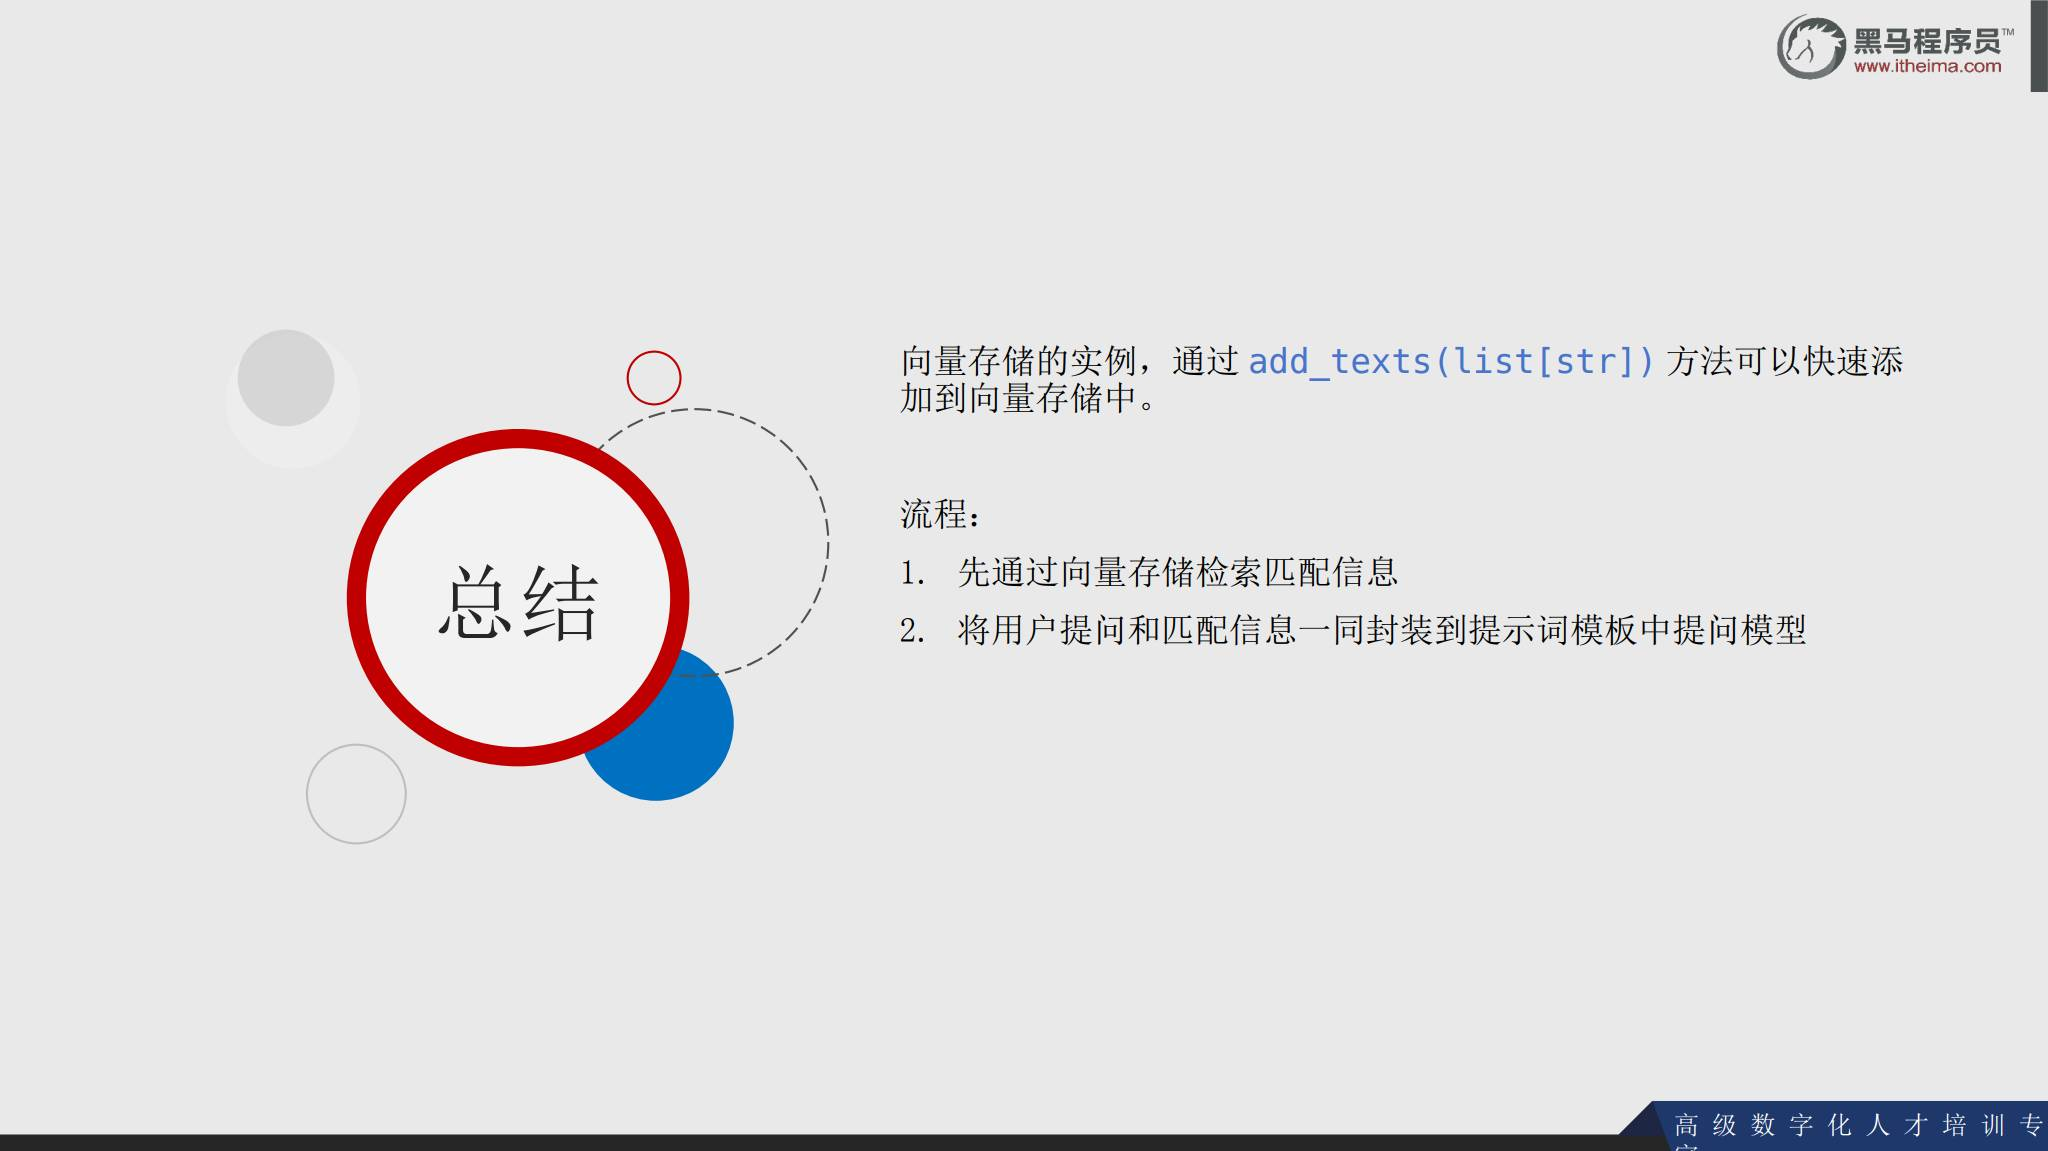


## 39. RunnablePassthrough

在链中，检索器负责根据问题返回上下文，`RunnablePassthrough` 可以把原始问题原样传递给提示词模板，同时把检索结果放入另一个变量：

```python
from langchain_core.runnables import RunnablePassthrough

rag_chain = (
    {
        "context": retriever,
        "input": RunnablePassthrough(),
    }
    | prompt
    | model
    | StrOutputParser()
)
```

这里的 `input` 保留用户原问题，`context` 使用检索器返回相关文档。两者汇合后进入 Prompt，构成典型的 RAG 链。

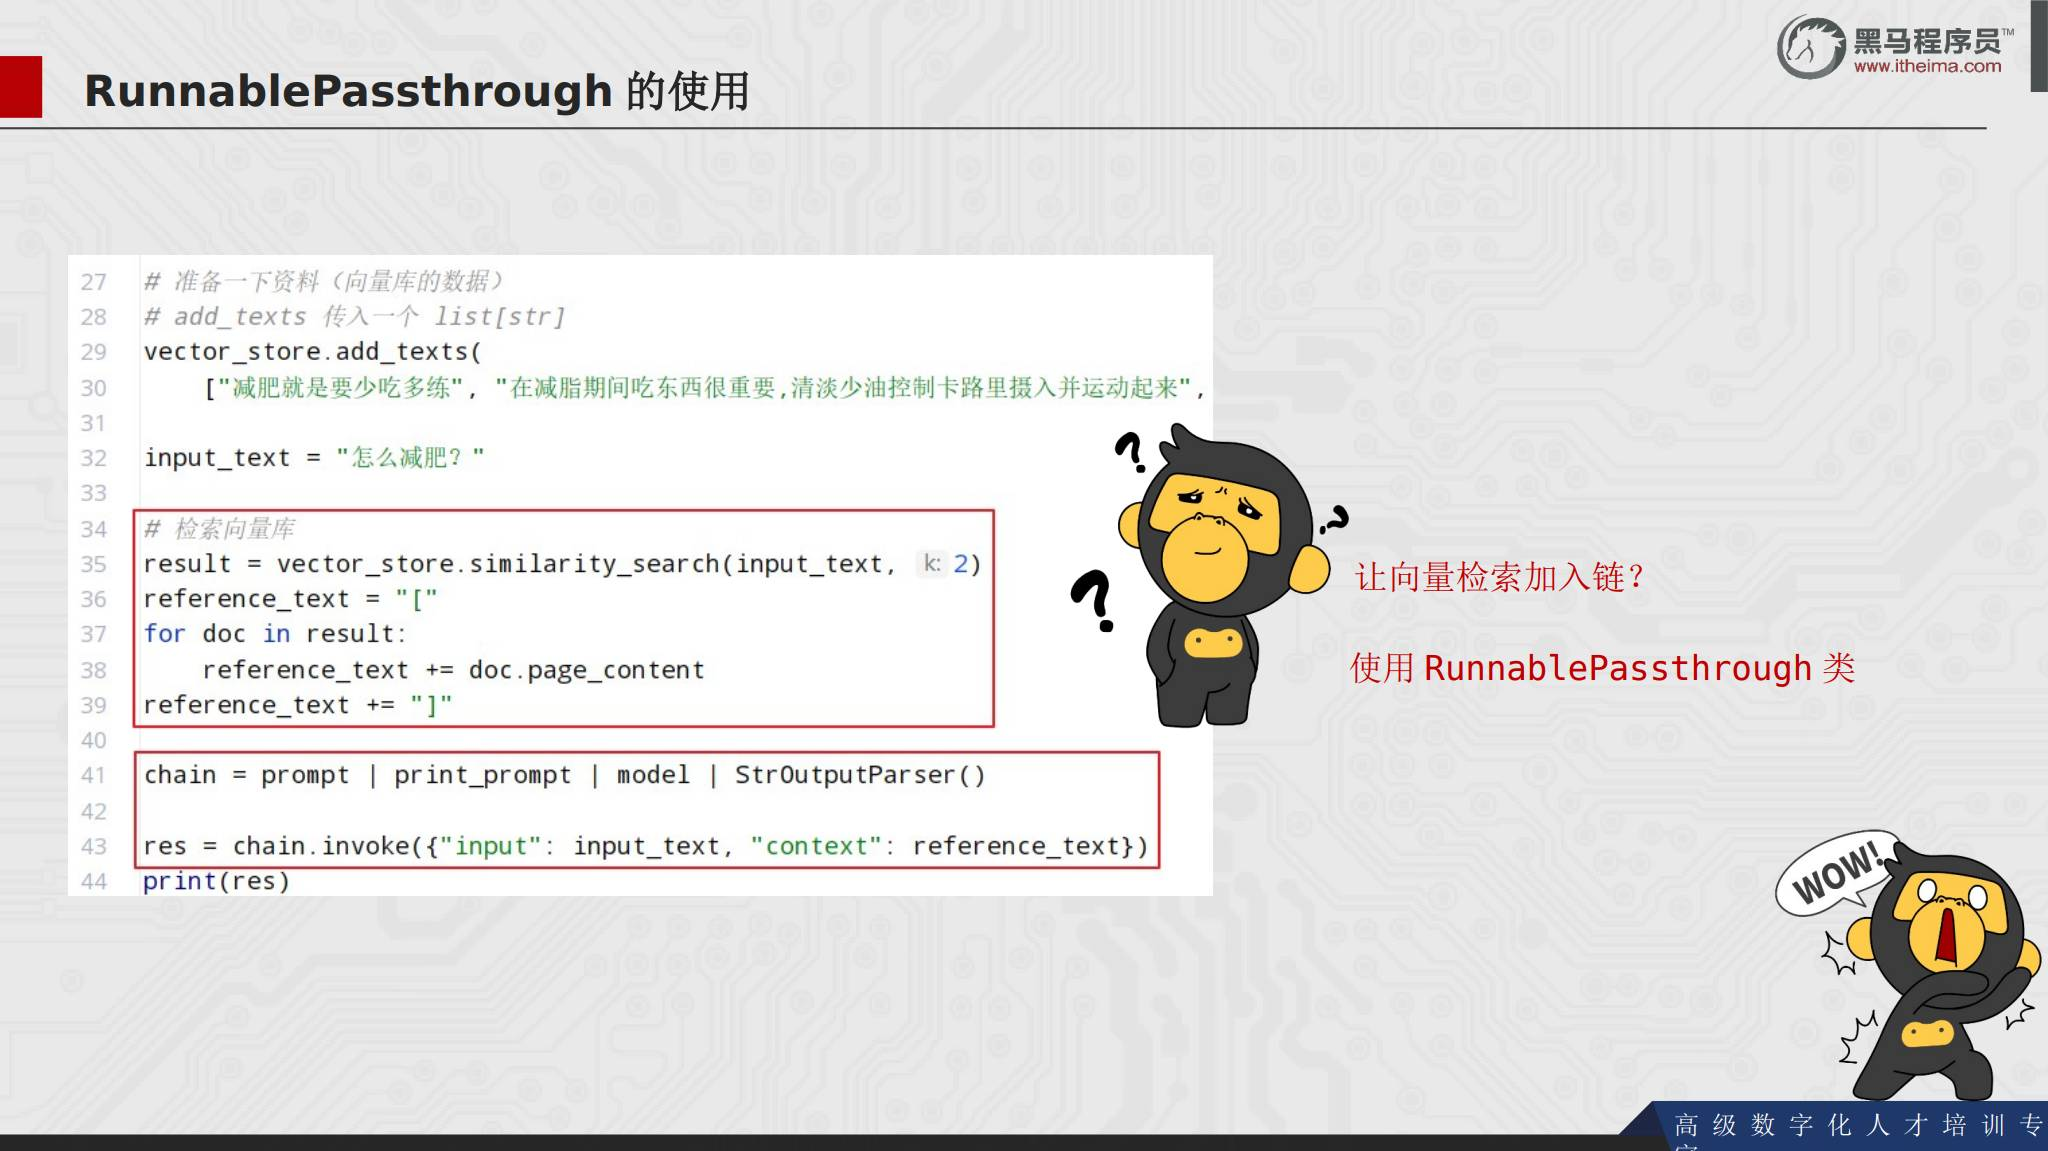


## 40. 本章小结

本篇完成了 LangChain RAG 开发的基础组件：

- 用索引、检索、生成三阶段理解 RAG。
- 用嵌入模型和余弦相似度完成语义匹配。
- 用 LangChain 统一调用 LLM、Chat Model 和 Embeddings。
- 用 PromptTemplate、FewShotPromptTemplate 和 ChatPromptTemplate 组织提示词。
- 用 `|` 构建 Runnable 链，并用输出解析器解决类型转换。
- 用内存或文件保存会话历史。
- 用 DocumentLoader、TextSplitter 和 VectorStore 构建知识库。
- 用检索器和 RunnablePassthrough 将上下文与原问题一起送入模型。


## 41. 资料边界

本篇依据第 2 份课件的 114 页内容整理。课件展示了 LangChain 组件和核心代码片段，但没有提供完整项目目录、全部配置文件和可直接运行的工程；不同版本的 LangChain、模型服务和向量库接口也可能变化，具体参数以当前环境和官方文档为准。
